In [3]:
from pathlib import Path

import json
import numpy as np
import pandas as pd
import torch
import torch_geometric


# --------------------------------------------------
# Paths
# --------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

DEPLOT_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "deplot"
)

ORACLE_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "oracle_e5"
)

BENCHMARK_DIR = (
    PROJECT_ROOT
    / "data"
    / "benchmark"
)

GRAPH_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "chartkg"
)

GRAPH_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "graphs"
    / "chartkg"
)

GRAPH_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GRAPH_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# --------------------------------------------------
# Required files
# --------------------------------------------------

deplot_metrics_path = (
    DEPLOT_DATA_DIR
    / "deplot_full_metrics.parquet"
)

canonical_tables_path = (
    ORACLE_DATA_DIR
    / "canonical_tables.parquet"
)

retrieval_pairs_path = (
    BENCHMARK_DIR
    / "retrieval_pairs.parquet"
)

required_files = [
    deplot_metrics_path,
    canonical_tables_path,
    retrieval_pairs_path
]

for file_path in required_files:
    print(
        file_path.name,
        ":",
        file_path.exists()
    )

assert all(
    file_path.exists()
    for file_path in required_files
)


# --------------------------------------------------
# Load data
# --------------------------------------------------

chart_graph_source_df = pd.read_parquet(
    deplot_metrics_path
)

table_graph_source_df = pd.read_parquet(
    canonical_tables_path
)

retrieval_pairs_df = pd.read_parquet(
    retrieval_pairs_path
)

print("\nEnvironment")
print("PyTorch:", torch.__version__)
print(
    "PyTorch Geometric:",
    torch_geometric.__version__
)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nGraph source data")
print(
    "Chart graphs to create:",
    len(chart_graph_source_df)
)
print(
    "Table graphs to create:",
    len(table_graph_source_df)
)
print(
    "Retrieval pairs:",
    len(retrieval_pairs_df)
)

assert len(chart_graph_source_df) == 4104
assert len(table_graph_source_df) == 1400
assert len(retrieval_pairs_df) == 5106


# --------------------------------------------------
# Validate parsed chart rows
# --------------------------------------------------

chart_graph_source_df[
    "parsed_row_count"
] = chart_graph_source_df[
    "parsed_rows_json"
].apply(
    lambda value: len(
        json.loads(value)
    )
)

table_graph_source_df[
    "exact_row_count"
] = table_graph_source_df[
    "rows_json"
].apply(
    lambda value: len(
        json.loads(value)
        if isinstance(value, str)
        else value
    )
)

print("\nChart parsed-row statistics")

display(
    chart_graph_source_df[
        "parsed_row_count"
    ].describe().to_frame()
)

print("\nExact table-row statistics")

display(
    table_graph_source_df[
        "exact_row_count"
    ].describe().to_frame()
)


# --------------------------------------------------
# Select one complete example family
# --------------------------------------------------

family_counts = (
    chart_graph_source_df.groupby(
        "source_data_id"
    )["variant_type"]
    .nunique()
)

sample_source_data_id = (
    family_counts[
        family_counts >= 3
    ]
    .index[0]
)

sample_charts_df = (
    chart_graph_source_df[
        chart_graph_source_df[
            "source_data_id"
        ]
        == sample_source_data_id
    ][
        [
            "chart_id",
            "chart_type",
            "variant_type",
            "table_variant_type",
            "parsed_rows_json"
        ]
    ]
    .reset_index(drop=True)
)

sample_tables_df = (
    table_graph_source_df[
        table_graph_source_df[
            "source_data_id"
        ]
        == sample_source_data_id
    ][
        [
            "data_id",
            "table_variant_type",
            "columns_json",
            "rows_json"
        ]
    ]
    .reset_index(drop=True)
)

print(
    "\nSample source:",
    sample_source_data_id
)

print("\nChart representations")

display(sample_charts_df)

print("\nExact table representations")

display(sample_tables_df)

deplot_full_metrics.parquet : True
canonical_tables.parquet : True
retrieval_pairs.parquet : True

Environment
PyTorch: 2.3.1+cu121
PyTorch Geometric: 2.6.1
CUDA: True
GPU: NVIDIA A100-SXM4-80GB

Graph source data
Chart graphs to create: 4104
Table graphs to create: 1400
Retrieval pairs: 5106

Chart parsed-row statistics


,parsed_row_count
count,4104.000000
mean,8.167398
std,3.420558
min,0.000000
25%,5.000000
50%,8.000000
75%,11.000000
max,34.000000



Exact table-row statistics


,exact_row_count
count,1400.000000
mean,8.547143
std,3.375784
min,3.000000
25%,6.000000
50%,9.000000
75%,11.000000
max,15.000000



Sample source: chartqa_test_15359798001840

Chart representations


,chart_id,chart_type,variant_type,table_variant_type,parsed_rows_json
0,chartqa_test_15359798001840__vbar_blue,v_bar,anchor,original,"[{""category"": ""Personal contacts"", ""raw_values..."
1,chartqa_test_15359798001840__hbar_orange,h_bar,positive,original,"[{""category"": ""Agencies"", ""raw_values"": [""1.60..."
2,chartqa_test_15359798001840__shuffled__vbar_blue,v_bar,hard_negative,hard_negative,"[{""category"": ""Personal contacts"", ""raw_values..."
3,chartqa_test_15359798001840__line_green,line,hard_positive,original,"[{""category"": ""Peru"", ""raw_values"": [""41.10""],..."
4,chartqa_test_15359798001840__shuffled__line_green,line,hard_negative,hard_negative,"[{""category"": ""Peru"", ""raw_values"": [""41.10""],..."
5,chartqa_test_15359798001840__pie_palette,pie,hard_positive,original,"[{""category"": ""Personal contacts"", ""raw_values..."
6,chartqa_test_15359798001840__shuffled__pie_pal...,pie,hard_negative,hard_negative,"[{""category"": ""Personal contacts"", ""raw_values..."



Exact table representations


,data_id,table_variant_type,columns_json,rows_json
0,chartqa_test_15359798001840,original,"[""Country"", ""Distribution of job finding metho...","[[""Personal contacts"", 41.0], [""Direct applica..."
1,chartqa_test_15359798001840__shuffled,hard_negative,"[""Country"", ""Distribution of job finding metho...","[[""Personal contacts"", 41.0], [""Direct applica..."


In [4]:
import json
import math
import re

import numpy as np
import pandas as pd


# --------------------------------------------------
# Graph schema
# --------------------------------------------------

NODE_TYPES = {
    "root": 0,
    "title": 1,
    "column": 2,
    "category": 3,
    "value": 4
}

RELATION_TYPES = {
    "root_has_title": 0,
    "title_of_root": 1,
    "root_has_column": 2,
    "column_of_root": 3,
    "root_has_category": 4,
    "category_of_root": 5,
    "category_has_value": 6,
    "value_of_category": 7,
    "column_has_value": 8,
    "value_of_column": 9,
    "greater_than": 10,
    "less_than": 11
}

NUMERIC_FEATURE_NAMES = [
    "is_numeric",
    "sign",
    "log_absolute_value",
    "within_graph_zscore",
    "within_graph_minmax",
    "within_graph_rank",
    "is_missing"
]


# --------------------------------------------------
# Basic parsing helpers
# --------------------------------------------------

def load_json_list(value):

    if isinstance(value, str):
        return json.loads(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, tuple):
        return list(value)

    if isinstance(value, list):
        return value

    return []


def parse_graph_numeric(value):

    if value is None:
        return None

    if isinstance(
        value,
        (int, float, np.integer, np.floating)
    ):

        if pd.isna(value):
            return None

        return float(value)

    text = str(value).strip()

    if not text:
        return None

    text = (
        text.replace("−", "-")
        .replace("–", "-")
        .replace("—", "-")
    )

    parenthesized_negative = (
        text.startswith("(")
        and text.endswith(")")
    )

    match = re.search(
        r"[-+]?"
        r"(?:\d{1,3}(?:,\d{3})+|\d+)"
        r"(?:\.\d+)?"
        r"(?:[eE][-+]?\d+)?",
        text
    )

    if match is None:
        return None

    number = float(
        match.group(0).replace(",", "")
    )

    if parenthesized_negative:
        number = -abs(number)

    suffix = text[
        match.end():
    ].strip().lower()

    if re.match(r"^(k|thousand)\b", suffix):
        number *= 1_000

    elif re.match(r"^(m|million)\b", suffix):
        number *= 1_000_000

    elif re.match(r"^(b|billion)\b", suffix):
        number *= 1_000_000_000

    return number


def normalize_node_text(value):

    if value is None:
        return ""

    return re.sub(
        r"\s+",
        " ",
        str(value).strip()
    )


# --------------------------------------------------
# Convert chart/table rows into one common format
# --------------------------------------------------

def prepare_chart_graph_input(chart_row):

    header = load_json_list(
        chart_row["parsed_header_json"]
    )

    parsed_rows = load_json_list(
        chart_row["parsed_rows_json"]
    )

    prepared_rows = []

    for parsed_row in parsed_rows:

        prepared_rows.append(
            {
                "category": parsed_row.get(
                    "category",
                    ""
                ),
                "raw_values": parsed_row.get(
                    "raw_values",
                    []
                )
            }
        )

    return {
        "graph_id": chart_row["chart_id"],
        "modality": "chart",
        "title": chart_row["parsed_title"],
        "columns": header,
        "rows": prepared_rows,
        "split": chart_row["split"],
        "source_data_id": (
            chart_row["source_data_id"]
        ),
        "variant_type": (
            chart_row["variant_type"]
        ),
        "chart_type": (
            chart_row["chart_type"]
        )
    }


def prepare_table_graph_input(table_row):

    columns = load_json_list(
        table_row["columns_json"]
    )

    exact_rows = load_json_list(
        table_row["rows_json"]
    )

    prepared_rows = []

    for exact_row in exact_rows:

        prepared_rows.append(
            {
                "category": (
                    exact_row[0]
                    if len(exact_row) > 0
                    else ""
                ),
                "raw_values": (
                    exact_row[1:]
                    if len(exact_row) > 1
                    else []
                )
            }
        )

    title = (
        columns[-1]
        if columns
        else None
    )

    return {
        "graph_id": table_row["data_id"],
        "modality": "table",
        "title": title,
        "columns": columns,
        "rows": prepared_rows,
        "split": table_row["split"],
        "source_data_id": (
            table_row["source_data_id"]
        ),
        "variant_type": (
            table_row["table_variant_type"]
        ),
        "chart_type": None
    }


# --------------------------------------------------
# ChartKG-inspired graph builder
# --------------------------------------------------

def build_chartkg_graph(graph_input):

    nodes = []
    edges = []

    value_nodes_by_column = {}


    def add_node(
        node_type,
        text,
        numeric_value=None
    ):

        node_id = len(nodes)

        nodes.append(
            {
                "node_id": node_id,
                "node_type": node_type,
                "node_type_id": (
                    NODE_TYPES[node_type]
                ),
                "text": normalize_node_text(
                    text
                ),
                "numeric_value": (
                    numeric_value
                ),
                "numeric_features": [
                    0.0
                ] * len(
                    NUMERIC_FEATURE_NAMES
                )
            }
        )

        return node_id


    def add_edge(
        source,
        target,
        relation
    ):

        edges.append(
            {
                "source": int(source),
                "target": int(target),
                "relation": relation,
                "relation_id": (
                    RELATION_TYPES[relation]
                )
            }
        )


    def add_inverse_edges(
        source,
        target,
        forward_relation,
        inverse_relation
    ):

        add_edge(
            source,
            target,
            forward_relation
        )

        add_edge(
            target,
            source,
            inverse_relation
        )


    # Root node is modality-neutral to encourage
    # chart-table alignment.
    root_id = add_node(
        "root",
        "data table"
    )

    title = graph_input.get("title")

    if title:

        title_id = add_node(
            "title",
            title
        )

        add_inverse_edges(
            root_id,
            title_id,
            "root_has_title",
            "title_of_root"
        )


    # Determine columns.
    columns = graph_input.get(
        "columns",
        []
    )

    rows = graph_input.get(
        "rows",
        []
    )

    maximum_value_count = max(
        (
            len(row["raw_values"])
            for row in rows
        ),
        default=1
    )

    if columns:

        category_column = str(
            columns[0]
        )

        value_columns = [
            str(column)
            for column in columns[1:]
        ]

    else:

        category_column = "category"

        value_columns = []


    while (
        len(value_columns)
        < maximum_value_count
    ):

        value_columns.append(
            f"value {len(value_columns) + 1}"
        )


    category_column_id = add_node(
        "column",
        category_column
    )

    add_inverse_edges(
        root_id,
        category_column_id,
        "root_has_column",
        "column_of_root"
    )

    value_column_ids = []

    for value_column in value_columns:

        value_column_id = add_node(
            "column",
            value_column
        )

        value_column_ids.append(
            value_column_id
        )

        add_inverse_edges(
            root_id,
            value_column_id,
            "root_has_column",
            "column_of_root"
        )


    # Category and value nodes.
    for row in rows:

        category_id = add_node(
            "category",
            row["category"]
        )

        add_inverse_edges(
            root_id,
            category_id,
            "root_has_category",
            "category_of_root"
        )

        for value_index, raw_value in enumerate(
            row["raw_values"]
        ):

            numeric_value = parse_graph_numeric(
                raw_value
            )

            value_id = add_node(
                "value",
                raw_value,
                numeric_value=numeric_value
            )

            add_inverse_edges(
                category_id,
                value_id,
                "category_has_value",
                "value_of_category"
            )

            if (
                value_index
                < len(value_column_ids)
            ):

                value_column_id = (
                    value_column_ids[
                        value_index
                    ]
                )

                add_inverse_edges(
                    value_column_id,
                    value_id,
                    "column_has_value",
                    "value_of_column"
                )

            value_nodes_by_column.setdefault(
                value_index,
                []
            ).append(value_id)


    # --------------------------------------------------
    # Numerical features and ordering relations
    # --------------------------------------------------

    for value_index, value_node_ids in (
        value_nodes_by_column.items()
    ):

        valid_node_ids = [
            node_id
            for node_id in value_node_ids
            if nodes[node_id][
                "numeric_value"
            ] is not None
        ]

        valid_values = np.array(
            [
                nodes[node_id][
                    "numeric_value"
                ]
                for node_id in valid_node_ids
            ],
            dtype=np.float64
        )

        if len(valid_values) > 0:

            mean_value = float(
                valid_values.mean()
            )

            std_value = float(
                valid_values.std()
            )

            minimum_value = float(
                valid_values.min()
            )

            maximum_value = float(
                valid_values.max()
            )

            sorted_indices = np.argsort(
                valid_values,
                kind="stable"
            )

            ranks = np.empty(
                len(valid_values),
                dtype=np.float64
            )

            if len(valid_values) == 1:
                ranks[0] = 0.5
            else:
                ranks[sorted_indices] = (
                    np.arange(
                        len(valid_values)
                    )
                    / (
                        len(valid_values)
                        - 1
                    )
                )

            for local_index, node_id in enumerate(
                valid_node_ids
            ):

                value = float(
                    valid_values[
                        local_index
                    ]
                )

                sign = (
                    1.0
                    if value > 0
                    else -1.0
                    if value < 0
                    else 0.0
                )

                zscore = (
                    (value - mean_value)
                    / std_value
                    if std_value > 1e-12
                    else 0.0
                )

                minmax = (
                    (value - minimum_value)
                    / (
                        maximum_value
                        - minimum_value
                    )
                    if (
                        maximum_value
                        > minimum_value
                    )
                    else 0.5
                )

                nodes[node_id][
                    "numeric_features"
                ] = [
                    1.0,
                    sign,
                    math.log1p(abs(value)),
                    zscore,
                    minmax,
                    float(ranks[local_index]),
                    0.0
                ]

            # Add magnitude-ordering relations.
            for first_position, first_node_id in enumerate(
                valid_node_ids
            ):

                first_value = nodes[
                    first_node_id
                ]["numeric_value"]

                for second_node_id in (
                    valid_node_ids[
                        first_position + 1:
                    ]
                ):

                    second_value = nodes[
                        second_node_id
                    ]["numeric_value"]

                    if first_value > second_value:

                        add_edge(
                            first_node_id,
                            second_node_id,
                            "greater_than"
                        )

                        add_edge(
                            second_node_id,
                            first_node_id,
                            "less_than"
                        )

                    elif second_value > first_value:

                        add_edge(
                            second_node_id,
                            first_node_id,
                            "greater_than"
                        )

                        add_edge(
                            first_node_id,
                            second_node_id,
                            "less_than"
                        )


        # Mark missing numeric nodes.
        for node_id in value_node_ids:

            if nodes[node_id][
                "numeric_value"
            ] is None:

                nodes[node_id][
                    "numeric_features"
                ][-1] = 1.0


    return {
        "graph_id": graph_input["graph_id"],
        "modality": graph_input["modality"],
        "split": graph_input["split"],
        "source_data_id": (
            graph_input["source_data_id"]
        ),
        "variant_type": (
            graph_input["variant_type"]
        ),
        "chart_type": (
            graph_input["chart_type"]
        ),
        "nodes": nodes,
        "edges": edges
    }


# --------------------------------------------------
# Build sample chart graphs
# --------------------------------------------------

sample_chart_graphs = []

for _, chart_row in (
    chart_graph_source_df[
        chart_graph_source_df[
            "source_data_id"
        ]
        == sample_source_data_id
    ]
    .iterrows()
):

    graph_input = prepare_chart_graph_input(
        chart_row
    )

    sample_chart_graphs.append(
        build_chartkg_graph(
            graph_input
        )
    )


# --------------------------------------------------
# Build sample exact table graphs
# --------------------------------------------------

sample_table_graphs = []

for _, table_row in (
    table_graph_source_df[
        table_graph_source_df[
            "source_data_id"
        ]
        == sample_source_data_id
    ]
    .iterrows()
):

    graph_input = prepare_table_graph_input(
        table_row
    )

    sample_table_graphs.append(
        build_chartkg_graph(
            graph_input
        )
    )


# --------------------------------------------------
# Extract category→value pairs for inspection
# --------------------------------------------------

def extract_category_value_pairs(graph):

    node_by_id = {
        node["node_id"]: node
        for node in graph["nodes"]
    }

    pairs = []

    for edge in graph["edges"]:

        if (
            edge["relation"]
            == "category_has_value"
        ):

            category_node = node_by_id[
                edge["source"]
            ]

            value_node = node_by_id[
                edge["target"]
            ]

            pairs.append(
                {
                    "category": (
                        category_node["text"]
                    ),
                    "value_text": (
                        value_node["text"]
                    ),
                    "numeric_value": (
                        value_node[
                            "numeric_value"
                        ]
                    ),
                    "within_graph_rank": (
                        value_node[
                            "numeric_features"
                        ][5]
                    )
                }
            )

    return pd.DataFrame(pairs)


# --------------------------------------------------
# Display sample graph relationships
# --------------------------------------------------

for graph in (
    sample_table_graphs
    + sample_chart_graphs
):

    print("\n" + "=" * 90)

    print("GRAPH:", graph["graph_id"])
    print("MODALITY:", graph["modality"])
    print("VARIANT:", graph["variant_type"])
    print("CHART TYPE:", graph["chart_type"])
    print("NODES:", len(graph["nodes"]))
    print("EDGES:", len(graph["edges"]))

    display(
        extract_category_value_pairs(
            graph
        )
    )


GRAPH: chartqa_test_15359798001840
MODALITY: table
VARIANT: original
CHART TYPE: None
NODES: 14
EDGES: 56


,category,value_text,numeric_value,within_graph_rank
0,Personal contacts,41.0,41.0,1.00
1,Direct applications,36.0,36.0,0.75
2,Other,14.3,14.3,0.50
3,Adverts,7.0,7.0,0.25
4,Agencies,1.6,1.6,0.00



GRAPH: chartqa_test_15359798001840__shuffled
MODALITY: table
VARIANT: hard_negative
CHART TYPE: None
NODES: 14
EDGES: 56


,category,value_text,numeric_value,within_graph_rank
0,Personal contacts,41.0,41.0,1.00
1,Direct applications,14.3,14.3,0.50
2,Other,36.0,36.0,0.75
3,Adverts,1.6,1.6,0.00
4,Agencies,7.0,7.0,0.25



GRAPH: chartqa_test_15359798001840__vbar_blue
MODALITY: chart
VARIANT: anchor
CHART TYPE: v_bar
NODES: 14
EDGES: 56


,category,value_text,numeric_value,within_graph_rank
0,Personal contacts,41.10,41.1,1.00
1,Direct applications,36.10,36.1,0.75
2,Other,14.50,14.5,0.50
3,Adverts,7.20,7.2,0.25
4,Agencles,1.50,1.5,0.00


... (8 outputs left out)


GRAPH: chartqa_test_15359798001840__pie_palette
MODALITY: chart
VARIANT: hard_positive
CHART TYPE: pie
NODES: 14
EDGES: 56


,category,value_text,numeric_value,within_graph_rank
0,Personal contacts,41.0,41.0,1.00
1,Direct applications,36.0,36.0,0.75
2,Other,14.3,14.3,0.50
3,Adverts,7.0,7.0,0.25
4,Agencies,1.6,1.6,0.00



GRAPH: chartqa_test_15359798001840__shuffled__pie_palette
MODALITY: chart
VARIANT: hard_negative
CHART TYPE: pie
NODES: 14
EDGES: 54


,category,value_text,numeric_value,within_graph_rank
0,Personal contacts,41.0,41.0,1.00
1,Direct applications,14.3,14.3,0.50
2,Other,36.0,36.0,0.75
3,Adverts,1.6,1.6,0.00
4,Agencies,1.6,1.6,0.25


In [5]:
from torch_geometric.data import Data

if not hasattr(
    Data,
    "_chart_retrieval_original_inc"
):
    Data._chart_retrieval_original_inc = Data.__inc__


def chart_retrieval_inc(
    self,
    key,
    value,
    *args,
    **kwargs
):
    if key in {
        "node_text_index",
        "graph_index"
    }:
        return 0

    return Data._chart_retrieval_original_inc(
        self,
        key,
        value,
        *args,
        **kwargs
    )


Data.__inc__ = chart_retrieval_inc

print("PyG batching patch installed.")

PyG batching patch installed.


In [3]:
from collections import Counter
from tqdm import tqdm

import json
import numpy as np
import pandas as pd


# --------------------------------------------------
# Convert graph dictionary to storage record
# --------------------------------------------------

def graph_to_record(graph):

    node_type_counts = Counter(
        node["node_type"]
        for node in graph["nodes"]
    )

    relation_counts = Counter(
        edge["relation"]
        for edge in graph["edges"]
    )

    return {
        "graph_id": graph["graph_id"],
        "modality": graph["modality"],
        "split": graph["split"],
        "source_data_id": (
            graph["source_data_id"]
        ),
        "variant_type": (
            graph["variant_type"]
        ),
        "chart_type": graph["chart_type"],
        "number_of_nodes": int(
            len(graph["nodes"])
        ),
        "number_of_edges": int(
            len(graph["edges"])
        ),
        "number_of_categories": int(
            node_type_counts.get(
                "category",
                0
            )
        ),
        "number_of_values": int(
            node_type_counts.get(
                "value",
                0
            )
        ),
        "number_of_numeric_values": int(
            sum(
                node["numeric_value"]
                is not None
                for node in graph["nodes"]
                if node["node_type"]
                == "value"
            )
        ),
        "has_title": int(
            node_type_counts.get(
                "title",
                0
            ) > 0
        ),
        "node_type_counts_json": (
            json.dumps(
                dict(node_type_counts)
            )
        ),
        "relation_counts_json": (
            json.dumps(
                dict(relation_counts)
            )
        ),
        "nodes_json": json.dumps(
            graph["nodes"],
            ensure_ascii=False
        ),
        "edges_json": json.dumps(
            graph["edges"],
            ensure_ascii=False
        )
    }


# --------------------------------------------------
# Build all chart graphs
# --------------------------------------------------

chart_graph_records = []

for _, chart_row in tqdm(
    chart_graph_source_df.iterrows(),
    total=len(chart_graph_source_df),
    desc="Building chart graphs"
):

    graph_input = prepare_chart_graph_input(
        chart_row
    )

    graph = build_chartkg_graph(
        graph_input
    )

    chart_graph_records.append(
        graph_to_record(graph)
    )


chart_graphs_df = pd.DataFrame(
    chart_graph_records
)

assert len(chart_graphs_df) == 4104
assert (
    chart_graphs_df["graph_id"].nunique()
    == 4104
)


# --------------------------------------------------
# Build all exact table graphs
# --------------------------------------------------

table_graph_records = []

for _, table_row in tqdm(
    table_graph_source_df.iterrows(),
    total=len(table_graph_source_df),
    desc="Building table graphs"
):

    graph_input = prepare_table_graph_input(
        table_row
    )

    graph = build_chartkg_graph(
        graph_input
    )

    table_graph_records.append(
        graph_to_record(graph)
    )


table_graphs_df = pd.DataFrame(
    table_graph_records
)

assert len(table_graphs_df) == 1400
assert (
    table_graphs_df["graph_id"].nunique()
    == 1400
)


# --------------------------------------------------
# Graph validation
# --------------------------------------------------

print("Chart graphs:", len(chart_graphs_df))
print("Table graphs:", len(table_graphs_df))

print(
    "Chart graphs without categories:",
    int(
        (
            chart_graphs_df[
                "number_of_categories"
            ] == 0
        ).sum()
    )
)

print(
    "Chart graphs without numeric values:",
    int(
        (
            chart_graphs_df[
                "number_of_numeric_values"
            ] == 0
        ).sum()
    )
)

print(
    "Table graphs without categories:",
    int(
        (
            table_graphs_df[
                "number_of_categories"
            ] == 0
        ).sum()
    )
)

print(
    "Table graphs without numeric values:",
    int(
        (
            table_graphs_df[
                "number_of_numeric_values"
            ] == 0
        ).sum()
    )
)


# --------------------------------------------------
# Summary by modality
# --------------------------------------------------

combined_graph_summary_df = pd.concat(
    [
        chart_graphs_df[
            [
                "modality",
                "number_of_nodes",
                "number_of_edges",
                "number_of_categories",
                "number_of_values",
                "number_of_numeric_values"
            ]
        ],
        table_graphs_df[
            [
                "modality",
                "number_of_nodes",
                "number_of_edges",
                "number_of_categories",
                "number_of_values",
                "number_of_numeric_values"
            ]
        ]
    ],
    ignore_index=True
)

print("\nGraph statistics by modality")

display(
    combined_graph_summary_df.groupby(
        "modality"
    ).agg(
        number_of_graphs=(
            "number_of_nodes",
            "count"
        ),
        mean_nodes=(
            "number_of_nodes",
            "mean"
        ),
        maximum_nodes=(
            "number_of_nodes",
            "max"
        ),
        mean_edges=(
            "number_of_edges",
            "mean"
        ),
        maximum_edges=(
            "number_of_edges",
            "max"
        ),
        mean_categories=(
            "number_of_categories",
            "mean"
        ),
        mean_numeric_values=(
            "number_of_numeric_values",
            "mean"
        )
    ).round(2)
)


# --------------------------------------------------
# Chart graph statistics by type
# --------------------------------------------------

print("\nChart graphs by chart type")

display(
    chart_graphs_df.groupby(
        "chart_type"
    ).agg(
        number_of_graphs=(
            "graph_id",
            "count"
        ),
        mean_nodes=(
            "number_of_nodes",
            "mean"
        ),
        mean_edges=(
            "number_of_edges",
            "mean"
        ),
        mean_categories=(
            "number_of_categories",
            "mean"
        ),
        mean_numeric_values=(
            "number_of_numeric_values",
            "mean"
        )
    ).round(2)
)


# --------------------------------------------------
# Save graph datasets
# --------------------------------------------------

chart_graphs_path = (
    GRAPH_DATA_DIR
    / "chart_graphs.parquet"
)

table_graphs_path = (
    GRAPH_DATA_DIR
    / "table_graphs.parquet"
)

graph_index_path = (
    GRAPH_DATA_DIR
    / "graph_index.parquet"
)

graph_schema_path = (
    GRAPH_DATA_DIR
    / "graph_schema.json"
)

chart_graphs_df.to_parquet(
    chart_graphs_path,
    index=False
)

table_graphs_df.to_parquet(
    table_graphs_path,
    index=False
)

graph_index_df = pd.concat(
    [
        chart_graphs_df.drop(
            columns=[
                "nodes_json",
                "edges_json"
            ]
        ),
        table_graphs_df.drop(
            columns=[
                "nodes_json",
                "edges_json"
            ]
        )
    ],
    ignore_index=True
)

graph_index_df.to_parquet(
    graph_index_path,
    index=False
)

graph_schema = {
    "node_types": NODE_TYPES,
    "relation_types": RELATION_TYPES,
    "numeric_feature_names": (
        NUMERIC_FEATURE_NAMES
    ),
    "number_of_node_types": len(
        NODE_TYPES
    ),
    "number_of_relation_types": len(
        RELATION_TYPES
    ),
    "design_notes": [
        (
            "Category order edges are excluded "
            "to maintain style invariance."
        ),
        (
            "Category-value edges encode the "
            "underlying data relationship."
        ),
        (
            "Greater-than and less-than edges "
            "provide scale-robust ordering."
        ),
        (
            "Relative rank and min-max features "
            "remain useful when DePlot loses "
            "axis magnitude."
        )
    ]
}

with open(
    graph_schema_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        graph_schema,
        file,
        indent=2
    )


# --------------------------------------------------
# Verify saved files
# --------------------------------------------------

print("\nSaved files:")

for file_path in [
    chart_graphs_path,
    table_graphs_path,
    graph_index_path,
    graph_schema_path
]:
    print(
        file_path.name,
        ":",
        file_path.exists()
    )

Building table graphs: 100%|██████████| 1400/1400 [00:00<00:00, 2453.03it/s]

Chart graphs: 4104
Table graphs: 1400
Chart graphs without categories: 2
Chart graphs without numeric values: 2
Table graphs without categories: 0
Table graphs without numeric values: 0

Graph statistics by modality


,number_of_graphs,mean_nodes,maximum_nodes,mean_edges,maximum_edges,mean_categories,mean_numeric_values
modality,,,,,,,
chart,4104,21.08,85,131.26,870,8.17,8.77
table,1400,21.09,34,131.75,306,8.55,8.54



Chart graphs by chart type


,number_of_graphs,mean_nodes,mean_edges,mean_categories,mean_numeric_values
chart_type,,,,,
h_bar,700,21.03,128.55,8.30,8.63
line,1400,22.38,146.61,8.70,9.53
pie,604,15.14,67.33,5.57,5.67
v_bar,1400,22.35,144.84,8.68,9.42



Saved files:
chart_graphs.parquet : True
table_graphs.parquet : True
graph_index.parquet : True
graph_schema.json : True


In [4]:
from pathlib import Path

import json
import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer
from tqdm import tqdm


# --------------------------------------------------
# Paths
# --------------------------------------------------

MODEL_CACHE_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "model_cache"
)

NODE_VOCAB_PATH = (
    GRAPH_ARTIFACT_DIR
    / "node_text_vocabulary.parquet"
)

NODE_EMBEDDINGS_PATH = (
    GRAPH_ARTIFACT_DIR
    / "node_text_embeddings.npy"
)

NODE_CONFIG_PATH = (
    GRAPH_ARTIFACT_DIR
    / "node_embedding_config.json"
)


# --------------------------------------------------
# Reload graph files if necessary
# --------------------------------------------------

if "chart_graphs_df" not in globals():

    chart_graphs_df = pd.read_parquet(
        GRAPH_DATA_DIR
        / "chart_graphs.parquet"
    )

if "table_graphs_df" not in globals():

    table_graphs_df = pd.read_parquet(
        GRAPH_DATA_DIR
        / "table_graphs.parquet"
    )


# --------------------------------------------------
# Collect unique node texts
# --------------------------------------------------

node_text_records = {}
next_text_index = 0


def register_graph_node_texts(
    graphs_dataframe
):

    global next_text_index

    for nodes_json in tqdm(
        graphs_dataframe["nodes_json"],
        desc="Collecting node texts"
    ):

        nodes = json.loads(nodes_json)

        for node in nodes:

            node_type = node["node_type"]

            node_text = (
                str(node["text"]).strip()
                if node["text"] is not None
                else ""
            )

            if not node_text:
                node_text = "[empty]"

            # Include node type in the key so that
            # "Value" as a title and "Value" as a
            # column may receive different embeddings.
            text_key = (
                node_type
                + "\t"
                + node_text
            )

            if text_key not in node_text_records:

                prompt_text = (
                    f"passage: {node_type}: "
                    f"{node_text}"
                )

                node_text_records[text_key] = {
                    "text_embedding_index": (
                        next_text_index
                    ),
                    "text_key": text_key,
                    "node_type": node_type,
                    "node_text": node_text,
                    "e5_prompt_text": (
                        prompt_text
                    )
                }

                next_text_index += 1


register_graph_node_texts(
    chart_graphs_df
)

register_graph_node_texts(
    table_graphs_df
)

node_vocabulary_df = (
    pd.DataFrame(
        node_text_records.values()
    )
    .sort_values(
        "text_embedding_index"
    )
    .reset_index(drop=True)
)

print(
    "Unique node texts:",
    len(node_vocabulary_df)
)

print("\nUnique text by node type")

display(
    node_vocabulary_df[
        "node_type"
    ]
    .value_counts()
    .to_frame("unique_texts")
)


# --------------------------------------------------
# Load E5
# --------------------------------------------------

MODEL_NAME = "intfloat/e5-base-v2"

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

assert device == "cuda"

print("\nGPU:", torch.cuda.get_device_name(0))

node_text_encoder = SentenceTransformer(
    MODEL_NAME,
    device=device,
    cache_folder=str(MODEL_CACHE_DIR)
)

node_text_encoder.max_seq_length = 512

node_tokenizer = (
    node_text_encoder.tokenizer
)


# --------------------------------------------------
# Check node text lengths
# --------------------------------------------------

node_vocabulary_df["token_count"] = (
    node_vocabulary_df[
        "e5_prompt_text"
    ].apply(
        lambda text: (
            len(
                node_tokenizer.tokenize(
                    text
                )
            )
            + 2
        )
    )
)

print("\nNode token statistics")

print(
    "Mean:",
    round(
        node_vocabulary_df[
            "token_count"
        ].mean(),
        2
    )
)

print(
    "Maximum:",
    node_vocabulary_df[
        "token_count"
    ].max()
)

print(
    "Above 512:",
    int(
        (
            node_vocabulary_df[
                "token_count"
            ] > 512
        ).sum()
    )
)


# --------------------------------------------------
# Encode unique node texts
# --------------------------------------------------

node_prompt_texts = (
    node_vocabulary_df[
        "e5_prompt_text"
    ]
    .tolist()
)

node_text_encoder.eval()

with torch.inference_mode():

    node_text_embeddings = (
        node_text_encoder.encode(
            node_prompt_texts,
            batch_size=128,
            show_progress_bar=True,
            convert_to_numpy=True,
            normalize_embeddings=True
        )
    )

node_text_embeddings = (
    node_text_embeddings.astype(
        np.float32
    )
)

print(
    "\nNode text embeddings:",
    node_text_embeddings.shape
)

print(
    "Mean norm:",
    round(
        float(
            np.linalg.norm(
                node_text_embeddings,
                axis=1
            ).mean()
        ),
        6
    )
)


# --------------------------------------------------
# Save vocabulary and embeddings
# --------------------------------------------------

node_vocabulary_df.to_parquet(
    NODE_VOCAB_PATH,
    index=False
)

np.save(
    NODE_EMBEDDINGS_PATH,
    node_text_embeddings
)

node_embedding_config = {
    "model_name": MODEL_NAME,
    "embedding_dimension": int(
        node_text_embeddings.shape[1]
    ),
    "number_of_unique_node_texts": int(
        len(node_vocabulary_df)
    ),
    "maximum_token_count": int(
        node_vocabulary_df[
            "token_count"
        ].max()
    ),
    "prompt_format": (
        "passage: {node_type}: {node_text}"
    )
}

with open(
    NODE_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        node_embedding_config,
        file,
        indent=2
    )


print("\nSaved files:")

for file_path in [
    NODE_VOCAB_PATH,
    NODE_EMBEDDINGS_PATH,
    NODE_CONFIG_PATH
]:
    print(
        file_path.name,
        ":",
        file_path.exists()
    )

Unique node texts: 21310

Unique text by node type


,unique_texts
node_type,
value,16517
category,2766
title,1244
column,782
root,1



GPU: NVIDIA A100-SXM4-80GB

Node token statistics
Mean: 9.83
Maximum: 50
Above 512: 0


Batches:   0%|          | 0/167 [00:00<?, ?it/s]


Node text embeddings: (21310, 768)
Mean norm: 1.0

Saved files:
node_text_vocabulary.parquet : True
node_text_embeddings.npy : True
node_embedding_config.json : True


In [8]:
import json

import numpy as np
import pandas as pd
import torch

from torch_geometric.data import Data
from tqdm import tqdm


# --------------------------------------------------
# Output paths
# --------------------------------------------------

CHART_PYG_PATH = (
    GRAPH_ARTIFACT_DIR
    / "chart_graphs_pyg.pt"
)

TABLE_PYG_PATH = (
    GRAPH_ARTIFACT_DIR
    / "table_graphs_pyg.pt"
)

CHART_PYG_METADATA_PATH = (
    GRAPH_ARTIFACT_DIR
    / "chart_graph_metadata.parquet"
)

TABLE_PYG_METADATA_PATH = (
    GRAPH_ARTIFACT_DIR
    / "table_graph_metadata.parquet"
)


# --------------------------------------------------
# Restore vocabulary if necessary
# --------------------------------------------------

if "node_vocabulary_df" not in globals():

    node_vocabulary_df = pd.read_parquet(
        NODE_VOCAB_PATH
    )

if "node_text_embeddings" not in globals():

    node_text_embeddings = np.load(
        NODE_EMBEDDINGS_PATH
    )


text_index_by_key = dict(
    zip(
        node_vocabulary_df["text_key"],
        node_vocabulary_df[
            "text_embedding_index"
        ]
    )
)


# --------------------------------------------------
# Convert one stored graph into PyG format
# --------------------------------------------------

def graph_record_to_pyg(
    graph_row,
    graph_index
):

    nodes = json.loads(
        graph_row["nodes_json"]
    )

    edges = json.loads(
        graph_row["edges_json"]
    )

    node_text_indices = []
    node_type_ids = []
    numeric_features = []

    for node in nodes:

        node_text = (
            str(node["text"]).strip()
            if node["text"] is not None
            else ""
        )

        if not node_text:
            node_text = "[empty]"

        text_key = (
            node["node_type"]
            + "\t"
            + node_text
        )

        node_text_indices.append(
            text_index_by_key[text_key]
        )

        node_type_ids.append(
            int(node["node_type_id"])
        )

        numeric_features.append(
            [
                float(value)
                for value in node[
                    "numeric_features"
                ]
            ]
        )

    if edges:

        edge_index = torch.tensor(
            [
                [
                    int(edge["source"])
                    for edge in edges
                ],
                [
                    int(edge["target"])
                    for edge in edges
                ]
            ],
            dtype=torch.long
        )

        edge_type = torch.tensor(
            [
                int(edge["relation_id"])
                for edge in edges
            ],
            dtype=torch.long
        )

    else:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

        edge_type = torch.empty(
            (0,),
            dtype=torch.long
        )

    modality_id = (
        0
        if graph_row["modality"]
        == "chart"
        else 1
    )

    graph_data = Data(
        node_text_index=torch.tensor(
            node_text_indices,
            dtype=torch.long
        ),
        node_type=torch.tensor(
            node_type_ids,
            dtype=torch.long
        ),
        numeric_features=torch.tensor(
            numeric_features,
            dtype=torch.float32
        ),
        edge_index=edge_index,
        edge_type=edge_type,
        graph_index=torch.tensor(
            [graph_index],
            dtype=torch.long
        ),
        modality_id=torch.tensor(
            [modality_id],
            dtype=torch.long
        ),
        num_nodes=len(nodes)
    )

    return graph_data


# --------------------------------------------------
# Convert all chart graphs
# --------------------------------------------------

chart_graphs_df = (
    chart_graphs_df
    .reset_index(drop=True)
    .copy()
)

chart_pyg_graphs = []

for graph_index, graph_row in tqdm(
    chart_graphs_df.iterrows(),
    total=len(chart_graphs_df),
    desc="Converting chart graphs"
):

    chart_pyg_graphs.append(
        graph_record_to_pyg(
            graph_row,
            graph_index
        )
    )

chart_graph_metadata_df = (
    chart_graphs_df.drop(
        columns=[
            "nodes_json",
            "edges_json"
        ]
    )
    .copy()
)

chart_graph_metadata_df[
    "graph_index"
] = np.arange(
    len(chart_graph_metadata_df)
)


# --------------------------------------------------
# Convert all table graphs
# --------------------------------------------------

table_graphs_df = (
    table_graphs_df
    .reset_index(drop=True)
    .copy()
)

table_pyg_graphs = []

for graph_index, graph_row in tqdm(
    table_graphs_df.iterrows(),
    total=len(table_graphs_df),
    desc="Converting table graphs"
):

    table_pyg_graphs.append(
        graph_record_to_pyg(
            graph_row,
            graph_index
        )
    )

table_graph_metadata_df = (
    table_graphs_df.drop(
        columns=[
            "nodes_json",
            "edges_json"
        ]
    )
    .copy()
)

table_graph_metadata_df[
    "graph_index"
] = np.arange(
    len(table_graph_metadata_df)
)


# --------------------------------------------------
# Validation helper
# --------------------------------------------------

def validate_pyg_graphs(
    graph_list,
    expected_number
):

    assert len(graph_list) == expected_number

    maximum_text_index = max(
        int(
            graph.node_text_index.max()
        )
        for graph in graph_list
    )

    maximum_node_type = max(
        int(
            graph.node_type.max()
        )
        for graph in graph_list
    )

    maximum_edge_type = max(
        int(
            graph.edge_type.max()
        )
        if graph.edge_type.numel() > 0
        else -1
        for graph in graph_list
    )

    invalid_edge_graphs = 0

    for graph in graph_list:

        if graph.edge_index.numel() > 0:

            if int(
                graph.edge_index.max()
            ) >= graph.num_nodes:

                invalid_edge_graphs += 1

    assert maximum_text_index < len(
        node_text_embeddings
    )

    assert maximum_node_type < len(
        NODE_TYPES
    )

    assert maximum_edge_type < len(
        RELATION_TYPES
    )

    assert invalid_edge_graphs == 0

    return {
        "number_of_graphs": len(
            graph_list
        ),
        "maximum_text_index": (
            maximum_text_index
        ),
        "maximum_node_type": (
            maximum_node_type
        ),
        "maximum_edge_type": (
            maximum_edge_type
        ),
        "invalid_edge_graphs": (
            invalid_edge_graphs
        )
    }


chart_validation = validate_pyg_graphs(
    chart_pyg_graphs,
    4104
)

table_validation = validate_pyg_graphs(
    table_pyg_graphs,
    1400
)

print("Chart validation:")
print(chart_validation)

print("\nTable validation:")
print(table_validation)


# --------------------------------------------------
# Inspect one graph tensor
# --------------------------------------------------

sample_graph = chart_pyg_graphs[0]

print("\nSample PyG graph")
print(sample_graph)

print(
    "Node text indices:",
    sample_graph.node_text_index.shape
)

print(
    "Numeric features:",
    sample_graph.numeric_features.shape
)

print(
    "Edge index:",
    sample_graph.edge_index.shape
)

print(
    "Edge types:",
    sample_graph.edge_type.shape
)


# --------------------------------------------------
# Save compact graph objects and metadata
# --------------------------------------------------

torch.save(
    chart_pyg_graphs,
    CHART_PYG_PATH
)

torch.save(
    table_pyg_graphs,
    TABLE_PYG_PATH
)

chart_graph_metadata_df.to_parquet(
    CHART_PYG_METADATA_PATH,
    index=False
)

table_graph_metadata_df.to_parquet(
    TABLE_PYG_METADATA_PATH,
    index=False
)


print("\nSaved files:")

for file_path in [
    CHART_PYG_PATH,
    TABLE_PYG_PATH,
    CHART_PYG_METADATA_PATH,
    TABLE_PYG_METADATA_PATH
]:
    print(
        file_path.name,
        ":",
        file_path.exists()
    )

Converting table graphs: 100%|██████████| 1400/1400 [00:00<00:00, 3624.53it/s]


Chart validation:
{'number_of_graphs': 4104, 'maximum_text_index': 18696, 'maximum_node_type': 4, 'maximum_edge_type': 11, 'invalid_edge_graphs': 0}

Table validation:
{'number_of_graphs': 1400, 'maximum_text_index': 21309, 'maximum_node_type': 4, 'maximum_edge_type': 11, 'invalid_edge_graphs': 0}

Sample PyG graph
Data(edge_index=[2, 88], node_text_index=[18], node_type=[18], numeric_features=[18, 7], edge_type=[88], graph_index=[1], modality_id=[1], num_nodes=18)
Node text indices: torch.Size([18])
Numeric features: torch.Size([18, 7])
Edge index: torch.Size([2, 88])
Edge types: torch.Size([88])

Saved files:
chart_graphs_pyg.pt : True
table_graphs_pyg.pt : True
chart_graph_metadata.parquet : True
table_graph_metadata.parquet : True


In [7]:
# ============================================================
# Restore saved ChartKG artifact paths
# ============================================================

from pathlib import Path

GRAPH_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "chartkg"
)

GRAPH_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "graphs"
    / "chartkg"
)


# Graph parquet files
CHART_GRAPH_PATH = (
    GRAPH_DATA_DIR
    / "chart_graphs.parquet"
)

TABLE_GRAPH_PATH = (
    GRAPH_DATA_DIR
    / "table_graphs.parquet"
)

GRAPH_INDEX_PATH = (
    GRAPH_DATA_DIR
    / "graph_index.parquet"
)

GRAPH_SCHEMA_PATH = (
    GRAPH_DATA_DIR
    / "graph_schema.json"
)


# Node embedding files
NODE_VOCAB_PATH = (
    GRAPH_ARTIFACT_DIR
    / "node_text_vocabulary.parquet"
)

NODE_EMBEDDINGS_PATH = (
    GRAPH_ARTIFACT_DIR
    / "node_text_embeddings.npy"
)

NODE_EMBEDDING_CONFIG_PATH = (
    GRAPH_ARTIFACT_DIR
    / "node_embedding_config.json"
)


# PyTorch Geometric files
CHART_PYG_PATH = (
    GRAPH_ARTIFACT_DIR
    / "chart_graphs_pyg.pt"
)

TABLE_PYG_PATH = (
    GRAPH_ARTIFACT_DIR
    / "table_graphs_pyg.pt"
)

CHART_PYG_METADATA_PATH = (
    GRAPH_ARTIFACT_DIR
    / "chart_graph_metadata.parquet"
)

TABLE_PYG_METADATA_PATH = (
    GRAPH_ARTIFACT_DIR
    / "table_graph_metadata.parquet"
)


required_files = [
    CHART_GRAPH_PATH,
    TABLE_GRAPH_PATH,
    NODE_VOCAB_PATH,
    NODE_EMBEDDINGS_PATH,
    CHART_PYG_PATH,
    TABLE_PYG_PATH,
    CHART_PYG_METADATA_PATH,
    TABLE_PYG_METADATA_PATH
]

for path in required_files:
    print(
        path.name,
        ":",
        path.exists()
    )

assert all(
    path.exists()
    for path in required_files
), "One or more saved ChartKG files are missing."

print("\nAll ChartKG paths restored.")

chart_graphs.parquet : True
table_graphs.parquet : True
node_text_vocabulary.parquet : True
node_text_embeddings.npy : True
chart_graphs_pyg.pt : True
table_graphs_pyg.pt : True
chart_graph_metadata.parquet : True
table_graph_metadata.parquet : True

All ChartKG paths restored.


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torch_geometric.data import Batch
from torch_geometric.nn import (
    RGCNConv,
    global_mean_pool
)


# --------------------------------------------------
# Device and model configuration
# --------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

HIDDEN_DIMENSION = 256
OUTPUT_DIMENSION = 256
NODE_TYPE_DIMENSION = 16
NUMERIC_DIMENSION = 32
TEXT_PROJECTION_DIMENSION = 192
NUMBER_OF_RELATIONS = len(
    RELATION_TYPES
)
NUMBER_OF_NODE_TYPES = len(
    NODE_TYPES
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# --------------------------------------------------
# Restore graph objects if necessary
# --------------------------------------------------

if "chart_pyg_graphs" not in globals():

    chart_pyg_graphs = torch.load(
        CHART_PYG_PATH,
        map_location="cpu"
    )

if "table_pyg_graphs" not in globals():

    table_pyg_graphs = torch.load(
        TABLE_PYG_PATH,
        map_location="cpu"
    )

if "chart_graph_metadata_df" not in globals():

    chart_graph_metadata_df = pd.read_parquet(
        CHART_PYG_METADATA_PATH
    )

if "table_graph_metadata_df" not in globals():

    table_graph_metadata_df = pd.read_parquet(
        TABLE_PYG_METADATA_PATH
    )

if "node_text_embeddings" not in globals():

    node_text_embeddings = np.load(
        NODE_EMBEDDINGS_PATH
    )

if "retrieval_pairs_df" not in globals():

    retrieval_pairs_df = pd.read_parquet(
        BENCHMARK_DIR
        / "retrieval_pairs.parquet"
    )


# --------------------------------------------------
# Graph lookup dictionaries
# --------------------------------------------------

chart_graph_index_by_id = dict(
    zip(
        chart_graph_metadata_df["graph_id"],
        chart_graph_metadata_df[
            "graph_index"
        ]
    )
)

table_graph_index_by_id = dict(
    zip(
        table_graph_metadata_df["graph_id"],
        table_graph_metadata_df[
            "graph_index"
        ]
    )
)

assert len(
    chart_graph_index_by_id
) == 4104

assert len(
    table_graph_index_by_id
) == 1400


# --------------------------------------------------
# Combined chart/table triplet dataset
# --------------------------------------------------

class GraphTripletDataset(Dataset):

    def __init__(
        self,
        pairs_dataframe,
        chart_graphs,
        table_graphs,
        chart_lookup,
        table_lookup
    ):

        self.pairs = (
            pairs_dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.chart_graphs = chart_graphs
        self.table_graphs = table_graphs
        self.chart_lookup = chart_lookup
        self.table_lookup = table_lookup


    def __len__(self):

        return len(self.pairs)


    def __getitem__(self, index):

        pair = self.pairs.iloc[index]

        task = pair["task"]

        anchor_id = pair["anchor_id"]
        positive_id = pair["positive_id"]
        negative_id = pair["negative_id"]

        # Both tasks use a chart anchor.
        anchor_graph = self.chart_graphs[
            self.chart_lookup[anchor_id]
        ]

        if task == "chart_chart":

            positive_graph = self.chart_graphs[
                self.chart_lookup[
                    positive_id
                ]
            ]

            negative_graph = self.chart_graphs[
                self.chart_lookup[
                    negative_id
                ]
            ]

            task_id = 0

        elif task == "chart_table":

            positive_graph = self.table_graphs[
                self.table_lookup[
                    positive_id
                ]
            ]

            negative_graph = self.table_graphs[
                self.table_lookup[
                    negative_id
                ]
            ]

            task_id = 1

        else:

            raise ValueError(
                f"Unsupported task: {task}"
            )

        return (
            anchor_graph,
            positive_graph,
            negative_graph,
            task_id
        )


# --------------------------------------------------
# Custom triplet batch function
# --------------------------------------------------

def collate_graph_triplets(batch):

    anchor_graphs = [
        item[0]
        for item in batch
    ]

    positive_graphs = [
        item[1]
        for item in batch
    ]

    negative_graphs = [
        item[2]
        for item in batch
    ]

    task_ids = torch.tensor(
        [
            item[3]
            for item in batch
        ],
        dtype=torch.long
    )

    return {
        "anchor": Batch.from_data_list(
            anchor_graphs
        ),
        "positive": Batch.from_data_list(
            positive_graphs
        ),
        "negative": Batch.from_data_list(
            negative_graphs
        ),
        "task_id": task_ids
    }


# --------------------------------------------------
# Split pairs without leakage
# --------------------------------------------------

model_pairs_df = retrieval_pairs_df[
    retrieval_pairs_df["task"].isin(
        [
            "chart_chart",
            "chart_table"
        ]
    )
].copy()

train_pairs_df = model_pairs_df[
    model_pairs_df["split"]
    == "train"
].reset_index(drop=True)

val_pairs_df = model_pairs_df[
    model_pairs_df["split"]
    == "val"
].reset_index(drop=True)

test_pairs_df = model_pairs_df[
    model_pairs_df["split"]
    == "test"
].reset_index(drop=True)

print("\nTriplet counts")

print("Train:", len(train_pairs_df))
print("Validation:", len(val_pairs_df))
print("Test:", len(test_pairs_df))

print("\nTrain tasks")

display(
    train_pairs_df[
        "task"
    ].value_counts()
)


# --------------------------------------------------
# Create datasets and loaders
# --------------------------------------------------

train_graph_dataset = GraphTripletDataset(
    train_pairs_df,
    chart_pyg_graphs,
    table_pyg_graphs,
    chart_graph_index_by_id,
    table_graph_index_by_id
)

val_graph_dataset = GraphTripletDataset(
    val_pairs_df,
    chart_pyg_graphs,
    table_pyg_graphs,
    chart_graph_index_by_id,
    table_graph_index_by_id
)

test_graph_dataset = GraphTripletDataset(
    test_pairs_df,
    chart_pyg_graphs,
    table_pyg_graphs,
    chart_graph_index_by_id,
    table_graph_index_by_id
)

train_graph_loader = DataLoader(
    train_graph_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=collate_graph_triplets,
    num_workers=0
)

val_graph_loader = DataLoader(
    val_graph_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=collate_graph_triplets,
    num_workers=0
)

test_graph_loader = DataLoader(
    test_graph_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=collate_graph_triplets,
    num_workers=0
)


# --------------------------------------------------
# Shared R-GCN encoder
# --------------------------------------------------

class ChartKGRGCNEncoder(nn.Module):

    def __init__(
        self,
        frozen_text_embeddings,
        hidden_dimension=256,
        output_dimension=256,
        dropout=0.15
    ):

        super().__init__()

        frozen_embeddings_tensor = (
            torch.tensor(
                frozen_text_embeddings,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "text_embedding_matrix",
            frozen_embeddings_tensor
        )

        text_embedding_dimension = (
            frozen_embeddings_tensor.shape[1]
        )

        self.text_projection = nn.Sequential(
            nn.Linear(
                text_embedding_dimension,
                TEXT_PROJECTION_DIMENSION
            ),
            nn.LayerNorm(
                TEXT_PROJECTION_DIMENSION
            ),
            nn.GELU()
        )

        self.numeric_projection = nn.Sequential(
            nn.Linear(
                len(NUMERIC_FEATURE_NAMES),
                NUMERIC_DIMENSION
            ),
            nn.LayerNorm(
                NUMERIC_DIMENSION
            ),
            nn.GELU()
        )

        self.node_type_embedding = nn.Embedding(
            NUMBER_OF_NODE_TYPES,
            NODE_TYPE_DIMENSION
        )

        combined_dimension = (
            TEXT_PROJECTION_DIMENSION
            + NUMERIC_DIMENSION
            + NODE_TYPE_DIMENSION
        )

        self.input_projection = nn.Sequential(
            nn.Linear(
                combined_dimension,
                hidden_dimension
            ),
            nn.LayerNorm(
                hidden_dimension
            ),
            nn.GELU()
        )

        self.rgcn_1 = RGCNConv(
            hidden_dimension,
            hidden_dimension,
            num_relations=NUMBER_OF_RELATIONS,
            num_bases=4
        )

        self.rgcn_2 = RGCNConv(
            hidden_dimension,
            hidden_dimension,
            num_relations=NUMBER_OF_RELATIONS,
            num_bases=4
        )

        self.layer_norm_1 = nn.LayerNorm(
            hidden_dimension
        )

        self.layer_norm_2 = nn.LayerNorm(
            hidden_dimension
        )

        self.dropout = nn.Dropout(
            dropout
        )

        # Combine root-node representation with
        # mean-pooled graph representation.
        self.graph_projection = nn.Sequential(
            nn.Linear(
                hidden_dimension * 2,
                output_dimension
            ),
            nn.LayerNorm(
                output_dimension
            ),
            nn.GELU(),
            nn.Linear(
                output_dimension,
                output_dimension
            )
        )


    def forward(self, graph_batch):

        text_embeddings = (
            self.text_embedding_matrix[
                graph_batch.node_text_index
            ]
        )

        text_features = self.text_projection(
            text_embeddings
        )

        numeric_features = (
            self.numeric_projection(
                graph_batch.numeric_features
            )
        )

        node_type_features = (
            self.node_type_embedding(
                graph_batch.node_type
            )
        )

        node_features = torch.cat(
            [
                text_features,
                numeric_features,
                node_type_features
            ],
            dim=-1
        )

        node_features = self.input_projection(
            node_features
        )

        first_message = self.rgcn_1(
            node_features,
            graph_batch.edge_index,
            graph_batch.edge_type
        )

        node_features = self.layer_norm_1(
            node_features
            + self.dropout(
                F.gelu(first_message)
            )
        )

        second_message = self.rgcn_2(
            node_features,
            graph_batch.edge_index,
            graph_batch.edge_type
        )

        node_features = self.layer_norm_2(
            node_features
            + self.dropout(
                F.gelu(second_message)
            )
        )

        mean_graph_features = global_mean_pool(
            node_features,
            graph_batch.batch
        )

        # Root is always the first node in each graph.
        root_indices = graph_batch.ptr[:-1]

        root_features = node_features[
            root_indices
        ]

        graph_features = torch.cat(
            [
                root_features,
                mean_graph_features
            ],
            dim=-1
        )

        graph_embeddings = (
            self.graph_projection(
                graph_features
            )
        )

        return F.normalize(
            graph_embeddings,
            p=2,
            dim=-1
        )


# --------------------------------------------------
# Triplet loss
# --------------------------------------------------

def graph_triplet_loss(
    anchor_embeddings,
    positive_embeddings,
    negative_embeddings,
    margin=0.10
):

    positive_similarity = torch.sum(
        anchor_embeddings
        * positive_embeddings,
        dim=-1
    )

    negative_similarity = torch.sum(
        anchor_embeddings
        * negative_embeddings,
        dim=-1
    )

    loss = F.relu(
        margin
        + negative_similarity
        - positive_similarity
    )

    return (
        loss.mean(),
        positive_similarity,
        negative_similarity
    )


# --------------------------------------------------
# Model and smoke forward pass
# --------------------------------------------------

graph_encoder = ChartKGRGCNEncoder(
    frozen_text_embeddings=(
        node_text_embeddings
    ),
    hidden_dimension=HIDDEN_DIMENSION,
    output_dimension=OUTPUT_DIMENSION,
    dropout=0.15
).to(device)

trainable_parameters = sum(
    parameter.numel()
    for parameter in graph_encoder.parameters()
    if parameter.requires_grad
)

print(
    "\nTrainable parameters:",
    f"{trainable_parameters:,}"
)

smoke_batch = next(
    iter(train_graph_loader)
)

anchor_batch = smoke_batch[
    "anchor"
].to(device)

positive_batch = smoke_batch[
    "positive"
].to(device)

negative_batch = smoke_batch[
    "negative"
].to(device)

graph_encoder.eval()

with torch.inference_mode():

    anchor_embeddings = graph_encoder(
        anchor_batch
    )

    positive_embeddings = graph_encoder(
        positive_batch
    )

    negative_embeddings = graph_encoder(
        negative_batch
    )

    (
        smoke_loss,
        positive_similarity,
        negative_similarity
    ) = graph_triplet_loss(
        anchor_embeddings,
        positive_embeddings,
        negative_embeddings
    )


print(
    "Anchor embeddings:",
    anchor_embeddings.shape
)

print(
    "Positive embeddings:",
    positive_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_embeddings.shape
)

print(
    "Mean embedding norm:",
    round(
        float(
            torch.linalg.norm(
                anchor_embeddings,
                dim=1
            ).mean()
        ),
        6
    )
)

print(
    "Initial triplet loss:",
    round(
        float(smoke_loss),
        6
    )
)

print(
    "Initial positive similarity:",
    round(
        float(
            positive_similarity.mean()
        ),
        6
    )
)

print(
    "Initial negative similarity:",
    round(
        float(
            negative_similarity.mean()
        ),
        6
    )
)

Device: cuda
GPU: NVIDIA A100-SXM4-80GB

Triplet counts
Train: 3627
Validation: 738
Test: 741

Train tasks


task
chart_chart    1918
chart_table    1709
Name: count, dtype: int64


Trainable parameters: 1,065,264
Anchor embeddings: torch.Size([32, 256])
Positive embeddings: torch.Size([32, 256])
Negative embeddings: torch.Size([32, 256])
Mean embedding norm: 1.0
Initial triplet loss: 0.101434
Initial positive similarity: 0.987649
Initial negative similarity: 0.989083


In [12]:
# ============================================================
# BLOCK 7: Non-collapsing ChartKG contrastive training
# ============================================================

from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm import tqdm


# ------------------------------------------------------------
# Existing model and loaders
# ------------------------------------------------------------

model = graph_encoder.to(device)

train_loader = train_graph_loader
val_loader = val_graph_loader
test_loader = test_graph_loader

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Model:", model.__class__.__name__)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


# ------------------------------------------------------------
# New output directory
# ------------------------------------------------------------

MODEL_OUTPUT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
    / "chartkg_rgcn_contrastive"
)

MODEL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    MODEL_OUTPUT_DIR
    / "best_model.pt"
)

HISTORY_PATH = (
    MODEL_OUTPUT_DIR
    / "training_history.parquet"
)

CONFIG_PATH = (
    MODEL_OUTPUT_DIR
    / "training_config.json"
)

TEST_RESULTS_PATH = (
    MODEL_OUTPUT_DIR
    / "test_pairwise_results.parquet"
)

TEST_SUMMARY_PATH = (
    MODEL_OUTPUT_DIR
    / "test_summary.json"
)


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

NUMBER_OF_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 7

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

INFONCE_TEMPERATURE = 0.07
PAIR_TEMPERATURE = 0.07

INFONCE_WEIGHT = 1.0
HARD_NEGATIVE_WEIGHT = 0.5
VARIANCE_WEIGHT = 5.0

MINIMUM_DIMENSION_STD = 0.04

TASK_ID_TO_NAME = {
    0: "chart_chart",
    1: "chart_table"
}


# ------------------------------------------------------------
# Batch helpers
# ------------------------------------------------------------

def get_batch_value(
    batch,
    possible_names
):
    for name in possible_names:
        if name in batch:
            return batch[name]

    raise KeyError(
        f"Could not find {possible_names}. "
        f"Available keys: {list(batch.keys())}"
    )


def unpack_graph_batch(batch):
    anchor_graph = get_batch_value(
        batch,
        ["anchor", "anchor_graph"]
    )

    positive_graph = get_batch_value(
        batch,
        ["positive", "positive_graph"]
    )

    negative_graph = get_batch_value(
        batch,
        ["negative", "negative_graph"]
    )

    task_values = get_batch_value(
        batch,
        ["task_id", "task", "tasks"]
    )

    if torch.is_tensor(task_values):
        task_values = (
            task_values
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
            .tolist()
        )

    elif isinstance(task_values, np.ndarray):
        task_values = (
            task_values
            .reshape(-1)
            .tolist()
        )

    else:
        task_values = list(task_values)

    task_names = []

    for value in task_values:
        if isinstance(value, str):
            task_names.append(value)
        else:
            task_names.append(
                TASK_ID_TO_NAME[int(value)]
            )

    return (
        anchor_graph.to(device),
        positive_graph.to(device),
        negative_graph.to(device),
        task_names
    )


# ------------------------------------------------------------
# Anti-collapse metrics
# ------------------------------------------------------------

def mean_off_diagonal_similarity(
    embeddings
):
    number_of_embeddings = (
        embeddings.shape[0]
    )

    if number_of_embeddings < 2:
        return embeddings.new_tensor(0.0)

    similarity_matrix = (
        embeddings
        @ embeddings.T
    )

    diagonal_sum = torch.diagonal(
        similarity_matrix
    ).sum()

    off_diagonal_sum = (
        similarity_matrix.sum()
        - diagonal_sum
    )

    number_of_off_diagonal_values = (
        number_of_embeddings
        * (
            number_of_embeddings - 1
        )
    )

    return (
        off_diagonal_sum
        / number_of_off_diagonal_values
    )


def embedding_variance_loss(
    embeddings,
    minimum_std=0.04
):
    dimension_std = torch.sqrt(
        embeddings.var(
            dim=0,
            unbiased=False
        )
        + 1e-4
    )

    variance_loss = F.relu(
        minimum_std
        - dimension_std
    ).mean()

    return (
        variance_loss,
        dimension_std.mean()
    )


# ------------------------------------------------------------
# New contrastive objective
# ------------------------------------------------------------

def calculate_contrastive_objective(
    anchor_embeddings,
    positive_embeddings,
    negative_embeddings,
    task_names
):
    task_losses = []
    task_component_records = []

    for task_name in [
        "chart_chart",
        "chart_table"
    ]:
        task_mask = torch.tensor(
            [
                value == task_name
                for value in task_names
            ],
            dtype=torch.bool,
            device=device
        )

        if not task_mask.any():
            continue

        task_anchor = anchor_embeddings[
            task_mask
        ]

        task_positive = positive_embeddings[
            task_mask
        ]

        task_negative = negative_embeddings[
            task_mask
        ]

        number_of_pairs = task_anchor.shape[0]

        labels = torch.arange(
            number_of_pairs,
            device=device
        )

        # Each anchor must retrieve its corresponding positive.
        # Other positives and all hard negatives are distractors.
        candidates = torch.cat(
            [
                task_positive,
                task_negative
            ],
            dim=0
        )

        anchor_logits = (
            task_anchor
            @ candidates.T
        ) / INFONCE_TEMPERATURE

        anchor_infonce_loss = (
            F.cross_entropy(
                anchor_logits,
                labels
            )
        )

        # Symmetric positive-to-anchor alignment
        positive_logits = (
            task_positive
            @ task_anchor.T
        ) / INFONCE_TEMPERATURE

        positive_infonce_loss = (
            F.cross_entropy(
                positive_logits,
                labels
            )
        )

        infonce_loss = (
            anchor_infonce_loss
            + positive_infonce_loss
        ) / 2

        positive_similarity = (
            task_anchor
            * task_positive
        ).sum(dim=-1)

        negative_similarity = (
            task_anchor
            * task_negative
        ).sum(dim=-1)

        # Smooth explicit hard-negative ranking
        hard_negative_loss = (
            F.softplus(
                (
                    negative_similarity
                    - positive_similarity
                )
                / PAIR_TEMPERATURE
            )
            .mean()
        )

        all_task_embeddings = torch.cat(
            [
                task_anchor,
                task_positive,
                task_negative
            ],
            dim=0
        )

        (
            variance_loss,
            mean_dimension_std
        ) = embedding_variance_loss(
            all_task_embeddings,
            minimum_std=MINIMUM_DIMENSION_STD
        )

        task_loss = (
            INFONCE_WEIGHT
            * infonce_loss
            + HARD_NEGATIVE_WEIGHT
            * hard_negative_loss
            + VARIANCE_WEIGHT
            * variance_loss
        )

        task_losses.append(task_loss)

        task_component_records.append(
            {
                "task": task_name,
                "infonce_loss":
                    infonce_loss,
                "hard_negative_loss":
                    hard_negative_loss,
                "variance_loss":
                    variance_loss,
                "mean_dimension_std":
                    mean_dimension_std
            }
        )

    if not task_losses:
        raise ValueError(
            "No recognized tasks in batch."
        )

    total_loss = torch.stack(
        task_losses
    ).mean()

    return (
        total_loss,
        task_component_records
    )


# ------------------------------------------------------------
# Run one epoch
# ------------------------------------------------------------

def run_contrastive_epoch(
    model,
    data_loader,
    optimizer=None,
    description="Epoch"
):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    pair_records = []
    batch_records = []

    progress = tqdm(
        data_loader,
        desc=description,
        leave=False
    )

    for batch in progress:
        (
            anchor_graph,
            positive_graph,
            negative_graph,
            task_names
        ) = unpack_graph_batch(batch)

        if training:
            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(training):
            anchor_embeddings = model(
                anchor_graph
            )

            positive_embeddings = model(
                positive_graph
            )

            negative_embeddings = model(
                negative_graph
            )

            (
                total_loss,
                task_components
            ) = calculate_contrastive_objective(
                anchor_embeddings,
                positive_embeddings,
                negative_embeddings,
                task_names
            )

            if training:
                total_loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    GRADIENT_CLIP_NORM
                )

                optimizer.step()

        positive_similarity = (
            anchor_embeddings
            * positive_embeddings
        ).sum(dim=-1)

        negative_similarity = (
            anchor_embeddings
            * negative_embeddings
        ).sum(dim=-1)

        similarity_gap = (
            positive_similarity
            - negative_similarity
        )

        for index, task_name in enumerate(
            task_names
        ):
            pair_records.append(
                {
                    "task": task_name,
                    "positive_similarity":
                        float(
                            positive_similarity[
                                index
                            ].detach().cpu()
                        ),
                    "negative_similarity":
                        float(
                            negative_similarity[
                                index
                            ].detach().cpu()
                        ),
                    "similarity_gap":
                        float(
                            similarity_gap[
                                index
                            ].detach().cpu()
                        ),
                    "positive_wins":
                        float(
                            similarity_gap[
                                index
                            ].detach().cpu()
                            > 0
                        )
                }
            )

        combined_embeddings = torch.cat(
            [
                anchor_embeddings,
                positive_embeddings,
                negative_embeddings
            ],
            dim=0
        )

        batch_records.append(
            {
                "total_loss":
                    float(
                        total_loss
                        .detach()
                        .cpu()
                    ),
                "mean_dimension_std":
                    float(
                        torch.sqrt(
                            combined_embeddings.var(
                                dim=0,
                                unbiased=False
                            )
                            + 1e-4
                        )
                        .mean()
                        .detach()
                        .cpu()
                    ),
                "mean_off_diagonal_similarity":
                    float(
                        mean_off_diagonal_similarity(
                            combined_embeddings
                        )
                        .detach()
                        .cpu()
                    ),
                "mean_infonce_loss":
                    float(
                        torch.stack(
                            [
                                record[
                                    "infonce_loss"
                                ]
                                for record
                                in task_components
                            ]
                        )
                        .mean()
                        .detach()
                        .cpu()
                    ),
                "mean_hard_negative_loss":
                    float(
                        torch.stack(
                            [
                                record[
                                    "hard_negative_loss"
                                ]
                                for record
                                in task_components
                            ]
                        )
                        .mean()
                        .detach()
                        .cpu()
                    ),
                "mean_variance_loss":
                    float(
                        torch.stack(
                            [
                                record[
                                    "variance_loss"
                                ]
                                for record
                                in task_components
                            ]
                        )
                        .mean()
                        .detach()
                        .cpu()
                    )
            }
        )

        progress.set_postfix(
            loss=round(
                float(total_loss.detach().cpu()),
                4
            )
        )

    pair_df = pd.DataFrame(
        pair_records
    )

    batch_df = pd.DataFrame(
        batch_records
    )

    task_statistics = (
        pair_df
        .groupby("task")
        .agg(
            number_of_triplets=(
                "positive_wins",
                "size"
            ),
            mean_positive_similarity=(
                "positive_similarity",
                "mean"
            ),
            mean_negative_similarity=(
                "negative_similarity",
                "mean"
            ),
            mean_similarity_gap=(
                "similarity_gap",
                "mean"
            ),
            positive_wins_rate=(
                "positive_wins",
                "mean"
            )
        )
    )

    return {
        "loss":
            float(
                batch_df[
                    "total_loss"
                ].mean()
            ),
        "infonce_loss":
            float(
                batch_df[
                    "mean_infonce_loss"
                ].mean()
            ),
        "hard_negative_loss":
            float(
                batch_df[
                    "mean_hard_negative_loss"
                ].mean()
            ),
        "variance_loss":
            float(
                batch_df[
                    "mean_variance_loss"
                ].mean()
            ),
        "mean_dimension_std":
            float(
                batch_df[
                    "mean_dimension_std"
                ].mean()
            ),
        "mean_off_diagonal_similarity":
            float(
                batch_df[
                    "mean_off_diagonal_similarity"
                ].mean()
            ),
        "balanced_accuracy":
            float(
                task_statistics[
                    "positive_wins_rate"
                ].mean()
            ),
        "balanced_gap":
            float(
                task_statistics[
                    "mean_similarity_gap"
                ].mean()
            ),
        "task_statistics":
            task_statistics,
        "pair_records":
            pair_df
    }


# ------------------------------------------------------------
# Check that the model is fresh
# ------------------------------------------------------------

initial_batch = next(
    iter(train_loader)
)

(
    initial_anchor_graph,
    initial_positive_graph,
    initial_negative_graph,
    initial_task_names
) = unpack_graph_batch(initial_batch)

model.eval()

with torch.no_grad():
    initial_anchor = model(
        initial_anchor_graph
    )

    initial_positive = model(
        initial_positive_graph
    )

    initial_negative = model(
        initial_negative_graph
    )

    initial_positive_similarity = (
        initial_anchor
        * initial_positive
    ).sum(dim=-1).mean().item()

    initial_negative_similarity = (
        initial_anchor
        * initial_negative
    ).sum(dim=-1).mean().item()

print(
    "Fresh-model positive similarity:",
    round(
        initial_positive_similarity,
        6
    )
)

print(
    "Fresh-model negative similarity:",
    round(
        initial_negative_similarity,
        6
    )
)

if (
    initial_positive_similarity > 0.999
    and initial_negative_similarity > 0.999
):
    raise RuntimeError(
        "The collapsed model is still loaded. "
        "Delete graph_encoder and rerun Block 6."
    )


# ------------------------------------------------------------
# Optimizer and scheduler
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = (
    torch.optim.lr_scheduler
    .ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
)


# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

history = []

best_validation_score = float("-inf")
best_epoch = 0
epochs_without_improvement = 0

training_start_time = time.time()

for epoch in range(
    1,
    NUMBER_OF_EPOCHS + 1
):
    train_results = run_contrastive_epoch(
        model,
        train_loader,
        optimizer=optimizer,
        description=f"Epoch {epoch} train"
    )

    validation_results = (
        run_contrastive_epoch(
            model,
            val_loader,
            optimizer=None,
            description=(
                f"Epoch {epoch} validation"
            )
        )
    )

    # Accuracy is primary; gap breaks close ties.
    validation_score = (
        validation_results[
            "balanced_accuracy"
        ]
        + 2.0
        * validation_results[
            "balanced_gap"
        ]
    )

    scheduler.step(validation_score)

    learning_rate = (
        optimizer.param_groups[0]["lr"]
    )

    history_record = {
        "epoch": epoch,
        "learning_rate":
            learning_rate,
        "train_loss":
            train_results["loss"],
        "validation_loss":
            validation_results["loss"],
        "train_accuracy":
            train_results[
                "balanced_accuracy"
            ],
        "validation_accuracy":
            validation_results[
                "balanced_accuracy"
            ],
        "train_gap":
            train_results[
                "balanced_gap"
            ],
        "validation_gap":
            validation_results[
                "balanced_gap"
            ],
        "train_dimension_std":
            train_results[
                "mean_dimension_std"
            ],
        "validation_dimension_std":
            validation_results[
                "mean_dimension_std"
            ],
        "train_off_diagonal_similarity":
            train_results[
                "mean_off_diagonal_similarity"
            ],
        "validation_off_diagonal_similarity":
            validation_results[
                "mean_off_diagonal_similarity"
            ],
        "validation_score":
            validation_score
    }

    for task_name in [
        "chart_chart",
        "chart_table"
    ]:
        task_row = (
            validation_results[
                "task_statistics"
            ]
            .loc[task_name]
        )

        history_record[
            f"validation_{task_name}_accuracy"
        ] = float(
            task_row[
                "positive_wins_rate"
            ]
        )

        history_record[
            f"validation_{task_name}_gap"
        ] = float(
            task_row[
                "mean_similarity_gap"
            ]
        )

    history.append(history_record)

    pd.DataFrame(
        history
    ).to_parquet(
        HISTORY_PATH,
        index=False
    )

    print(
        f"\nEpoch {epoch:02d} | "
        f"train loss {train_results['loss']:.4f} | "
        f"val loss {validation_results['loss']:.4f} | "
        f"val accuracy "
        f"{validation_results['balanced_accuracy']:.4f} | "
        f"val gap "
        f"{validation_results['balanced_gap']:.5f} | "
        f"std "
        f"{validation_results['mean_dimension_std']:.4f} | "
        f"offdiag "
        f"{validation_results['mean_off_diagonal_similarity']:.4f}"
    )

    display(
        validation_results[
            "task_statistics"
        ]
    )

    if (
        validation_score
        > best_validation_score + 1e-4
    ):
        best_validation_score = (
            validation_score
        )

        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "validation_score":
                    validation_score,
                "validation_accuracy":
                    validation_results[
                        "balanced_accuracy"
                    ],
                "validation_gap":
                    validation_results[
                        "balanced_gap"
                    ]
            },
            BEST_MODEL_PATH
        )

        print(
            "Saved new best model:",
            BEST_MODEL_PATH
        )

    else:
        epochs_without_improvement += 1

        print(
            "Epochs without improvement:",
            epochs_without_improvement
        )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            f"Early stopping after "
            f"epoch {epoch}."
        )
        break


# ------------------------------------------------------------
# Restore best model and test
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print(
    "\nRestored best epoch:",
    checkpoint["epoch"]
)

test_results = run_contrastive_epoch(
    model,
    test_loader,
    optimizer=None,
    description="Testing"
)

test_results[
    "pair_records"
].to_parquet(
    TEST_RESULTS_PATH,
    index=False
)

test_task_records = json.loads(
    test_results[
        "task_statistics"
    ]
    .reset_index()
    .to_json(
        orient="records"
    )
)

test_summary = {
    "best_epoch":
        int(checkpoint["epoch"]),
    "best_validation_score":
        float(
            checkpoint[
                "validation_score"
            ]
        ),
    "test_loss":
        test_results["loss"],
    "test_balanced_accuracy":
        test_results[
            "balanced_accuracy"
        ],
    "test_balanced_gap":
        test_results[
            "balanced_gap"
        ],
    "test_dimension_std":
        test_results[
            "mean_dimension_std"
        ],
    "test_off_diagonal_similarity":
        test_results[
            "mean_off_diagonal_similarity"
        ],
    "task_statistics":
        test_task_records
}

with open(
    TEST_SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        test_summary,
        file,
        indent=2
    )

training_config = {
    "epochs_requested":
        NUMBER_OF_EPOCHS,
    "epochs_completed":
        len(history),
    "best_epoch":
        int(checkpoint["epoch"]),
    "learning_rate":
        LEARNING_RATE,
    "infonce_temperature":
        INFONCE_TEMPERATURE,
    "pair_temperature":
        PAIR_TEMPERATURE,
    "infonce_weight":
        INFONCE_WEIGHT,
    "hard_negative_weight":
        HARD_NEGATIVE_WEIGHT,
    "variance_weight":
        VARIANCE_WEIGHT,
    "training_minutes":
        (
            time.time()
            - training_start_time
        ) / 60
}

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        training_config,
        file,
        indent=2
    )

print("\nTraining completed")
print("Best epoch:", checkpoint["epoch"])

print("\nTest results")
display(
    test_results[
        "task_statistics"
    ]
)

print(
    "Test balanced accuracy:",
    round(
        test_results[
            "balanced_accuracy"
        ],
        4
    )
)

print(
    "Test balanced gap:",
    round(
        test_results[
            "balanced_gap"
        ],
        6
    )
)

print(
    "Test embedding std:",
    round(
        test_results[
            "mean_dimension_std"
        ],
        6
    )
)

print(
    "Test off-diagonal similarity:",
    round(
        test_results[
            "mean_off_diagonal_similarity"
        ],
        6
    )
)

print("\nSaved:", MODEL_OUTPUT_DIR)

Device: cuda
GPU: NVIDIA A100-SXM4-80GB
Model: ChartKGRGCNEncoder
Train batches: 114
Validation batches: 12
Test batches: 12
Fresh-model positive similarity: 0.990287
Fresh-model negative similarity: 0.991403



Epoch 01 | train loss 1.4162 | val loss 1.5612 | val accuracy 0.4450 | val gap -0.01023 | std 0.0468 | offdiag 0.4298


,number_of_triplets,mean_positive_similarity,mean_negative_similarity,mean_similarity_gap,positive_wins_rate
task,,,,,
chart_chart,392,0.970042,0.990699,-0.020657,0.283163
chart_table,346,0.948434,0.948230,0.000204,0.606936


Saved new best model: /home/pnola130/projects/chart_data_retrieval/artifacts/models/chartkg_rgcn_contrastive/best_model.pt



Epoch 02 | train loss 0.9552 | val loss 1.5152 | val accuracy 0.4677 | val gap -0.00914 | std 0.0508 | offdiag 0.3193


,number_of_triplets,mean_positive_similarity,mean_negative_similarity,mean_similarity_gap,positive_wins_rate
task,,,,,
chart_chart,392,0.972204,0.990763,-0.018559,0.290816
chart_table,346,0.956296,0.956010,0.000286,0.644509


... (84 outputs left out)

Epochs without improvement: 7
Early stopping after epoch 30.

Restored best epoch: 23



Training completed
Best epoch: 23

Test results


,number_of_triplets,mean_positive_similarity,mean_negative_similarity,mean_similarity_gap,positive_wins_rate
task,,,,,
chart_chart,394,0.922374,0.536099,0.386275,0.852792
chart_table,347,0.937960,0.512411,0.425549,0.933718


Test balanced accuracy: 0.8933
Test balanced gap: 0.405912
Test embedding std: 0.060067
Test off-diagonal similarity: 0.061997

Saved: /home/pnola130/projects/chart_data_retrieval/artifacts/models/chartkg_rgcn_contrastive


In [14]:
# ============================================================
# BLOCK 8: Encode every chart and table graph
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd
import torch
from tqdm import tqdm

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader


# ------------------------------------------------------------
# Ensure PyG does not modify global metadata indices
# ------------------------------------------------------------

if not hasattr(
    Data,
    "_chart_retrieval_original_inc"
):
    Data._chart_retrieval_original_inc = (
        Data.__inc__
    )


def chart_retrieval_inc(
    self,
    key,
    value,
    *args,
    **kwargs
):
    if key in {
        "node_text_index",
        "graph_index"
    }:
        return 0

    return Data._chart_retrieval_original_inc(
        self,
        key,
        value,
        *args,
        **kwargs
    )


Data.__inc__ = chart_retrieval_inc


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

CONTRASTIVE_MODEL_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
    / "chartkg_rgcn_contrastive"
)

BEST_MODEL_PATH = (
    CONTRASTIVE_MODEL_DIR
    / "best_model.pt"
)

GRAPH_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "chartkg_rgcn_contrastive"
)

GRAPH_EMBEDDING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHART_EMBEDDINGS_PATH = (
    GRAPH_EMBEDDING_DIR
    / "chart_embeddings.npy"
)

TABLE_EMBEDDINGS_PATH = (
    GRAPH_EMBEDDING_DIR
    / "table_embeddings.npy"
)

CHART_METADATA_OUTPUT_PATH = (
    GRAPH_EMBEDDING_DIR
    / "chart_metadata.parquet"
)

TABLE_METADATA_OUTPUT_PATH = (
    GRAPH_EMBEDDING_DIR
    / "table_metadata.parquet"
)

EMBEDDING_CONFIG_PATH = (
    GRAPH_EMBEDDING_DIR
    / "embedding_config.json"
)


# ------------------------------------------------------------
# Load saved graph collections when necessary
# ------------------------------------------------------------

if "chart_pyg_graphs" not in globals():
    chart_pyg_graphs = torch.load(
        CHART_PYG_PATH,
        map_location="cpu"
    )

if "table_pyg_graphs" not in globals():
    table_pyg_graphs = torch.load(
        TABLE_PYG_PATH,
        map_location="cpu"
    )

chart_graph_metadata_df = pd.read_parquet(
    CHART_PYG_METADATA_PATH
)

table_graph_metadata_df = pd.read_parquet(
    TABLE_PYG_METADATA_PATH
)

print("Chart graphs:", len(chart_pyg_graphs))
print("Table graphs:", len(table_pyg_graphs))
print(
    "Chart metadata:",
    len(chart_graph_metadata_df)
)
print(
    "Table metadata:",
    len(table_graph_metadata_df)
)

assert (
    len(chart_pyg_graphs)
    == len(chart_graph_metadata_df)
)

assert (
    len(table_pyg_graphs)
    == len(table_graph_metadata_df)
)


# ------------------------------------------------------------
# Restore best trained model
# ------------------------------------------------------------

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

graph_encoder.load_state_dict(
    checkpoint["model_state_dict"]
)

graph_encoder = graph_encoder.to(device)
graph_encoder.eval()

print("Loaded checkpoint epoch:", checkpoint["epoch"])
print(
    "Validation accuracy:",
    round(
        float(
            checkpoint[
                "validation_accuracy"
            ]
        ),
        6
    )
    if "validation_accuracy" in checkpoint
    else "not stored"
)

print(
    "Validation gap:",
    round(
        float(
            checkpoint[
                "validation_gap"
            ]
        ),
        6
    )
    if "validation_gap" in checkpoint
    else "not stored"
)


# ------------------------------------------------------------
# Encode graph collection
# ------------------------------------------------------------

def encode_graph_collection(
    graph_collection,
    description,
    batch_size=128
):
    graph_loader = DataLoader(
        graph_collection,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    all_embeddings = []
    all_graph_indices = []

    with torch.no_grad():
        for graph_batch in tqdm(
            graph_loader,
            desc=description
        ):
            graph_batch = graph_batch.to(
                device
            )

            embeddings = graph_encoder(
                graph_batch
            )

            all_embeddings.append(
                embeddings
                .detach()
                .cpu()
                .numpy()
            )

            graph_indices = (
                graph_batch
                .graph_index
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )

            all_graph_indices.extend(
                graph_indices.tolist()
            )

    all_embeddings = np.concatenate(
        all_embeddings,
        axis=0
    ).astype(np.float32)

    all_graph_indices = np.asarray(
        all_graph_indices,
        dtype=np.int64
    )

    return (
        all_embeddings,
        all_graph_indices
    )


chart_graph_embeddings, chart_graph_indices = (
    encode_graph_collection(
        chart_pyg_graphs,
        description="Encoding chart graphs"
    )
)

table_graph_embeddings, table_graph_indices = (
    encode_graph_collection(
        table_pyg_graphs,
        description="Encoding table graphs"
    )
)


# ------------------------------------------------------------
# Align metadata with embedding order
# ------------------------------------------------------------

def align_metadata(
    metadata_df,
    graph_indices
):
    metadata_df = (
        metadata_df
        .copy()
        .reset_index(drop=True)
    )

    if "graph_index" not in metadata_df.columns:
        metadata_df[
            "graph_index"
        ] = np.arange(
            len(metadata_df)
        )

    metadata_df[
        "graph_index"
    ] = (
        metadata_df[
            "graph_index"
        ]
        .astype(int)
    )

    assert (
        metadata_df[
            "graph_index"
        ]
        .is_unique
    ), "Duplicate graph_index values found."

    aligned_df = (
        metadata_df
        .set_index("graph_index")
        .loc[graph_indices]
        .reset_index()
    )

    aligned_df.insert(
        0,
        "embedding_index",
        np.arange(
            len(aligned_df)
        )
    )

    return aligned_df


chart_embedding_metadata_df = (
    align_metadata(
        chart_graph_metadata_df,
        chart_graph_indices
    )
)

table_embedding_metadata_df = (
    align_metadata(
        table_graph_metadata_df,
        table_graph_indices
    )
)


# ------------------------------------------------------------
# Validate embeddings
# ------------------------------------------------------------

assert chart_graph_embeddings.shape == (
    4104,
    256
)

assert table_graph_embeddings.shape == (
    1400,
    256
)

assert np.isfinite(
    chart_graph_embeddings
).all()

assert np.isfinite(
    table_graph_embeddings
).all()

chart_norms = np.linalg.norm(
    chart_graph_embeddings,
    axis=1
)

table_norms = np.linalg.norm(
    table_graph_embeddings,
    axis=1
)

assert np.allclose(
    chart_norms,
    1.0,
    atol=1e-4
)

assert np.allclose(
    table_norms,
    1.0,
    atol=1e-4
)


# ------------------------------------------------------------
# Save embeddings and metadata
# ------------------------------------------------------------

np.save(
    CHART_EMBEDDINGS_PATH,
    chart_graph_embeddings
)

np.save(
    TABLE_EMBEDDINGS_PATH,
    table_graph_embeddings
)

chart_embedding_metadata_df.to_parquet(
    CHART_METADATA_OUTPUT_PATH,
    index=False
)

table_embedding_metadata_df.to_parquet(
    TABLE_METADATA_OUTPUT_PATH,
    index=False
)

embedding_config = {
    "model":
        "ChartKGRGCNEncoder",
    "checkpoint_epoch":
        int(checkpoint["epoch"]),
    "embedding_dimension":
        int(
            chart_graph_embeddings.shape[1]
        ),
    "number_of_chart_embeddings":
        int(
            chart_graph_embeddings.shape[0]
        ),
    "number_of_table_embeddings":
        int(
            table_graph_embeddings.shape[0]
        ),
    "normalized":
        True
}

with open(
    EMBEDDING_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        embedding_config,
        file,
        indent=2
    )


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("\nChart embeddings:", chart_graph_embeddings.shape)
print("Table embeddings:", table_graph_embeddings.shape)

print(
    "Mean chart norm:",
    round(
        float(chart_norms.mean()),
        6
    )
)

print(
    "Mean table norm:",
    round(
        float(table_norms.mean()),
        6
    )
)

print("\nChart metadata columns:")
print(
    chart_embedding_metadata_df
    .columns
    .tolist()
)

print("\nTable metadata columns:")
print(
    table_embedding_metadata_df
    .columns
    .tolist()
)

print("\nSaved files:")
print(
    "chart_embeddings.npy:",
    CHART_EMBEDDINGS_PATH.exists()
)

print(
    "table_embeddings.npy:",
    TABLE_EMBEDDINGS_PATH.exists()
)

print(
    "chart_metadata.parquet:",
    CHART_METADATA_OUTPUT_PATH.exists()
)

print(
    "table_metadata.parquet:",
    TABLE_METADATA_OUTPUT_PATH.exists()
)

display(
    chart_embedding_metadata_df.head()
)

display(
    table_embedding_metadata_df.head()
)

Chart graphs: 4104
Table graphs: 1400
Chart metadata: 4104
Table metadata: 1400
Loaded checkpoint epoch: 23
Validation accuracy: 0.93402
Validation gap: 0.374087


Encoding table graphs: 100%|██████████| 11/11 [00:00<00:00, 85.95it/s]



Chart embeddings: (4104, 256)
Table embeddings: (1400, 256)
Mean chart norm: 1.0
Mean table norm: 1.0

Chart metadata columns:
['embedding_index', 'graph_index', 'graph_id', 'modality', 'split', 'source_data_id', 'variant_type', 'chart_type', 'number_of_nodes', 'number_of_edges', 'number_of_categories', 'number_of_values', 'number_of_numeric_values', 'has_title', 'node_type_counts_json', 'relation_counts_json']

Table metadata columns:
['embedding_index', 'graph_index', 'graph_id', 'modality', 'split', 'source_data_id', 'variant_type', 'chart_type', 'number_of_nodes', 'number_of_edges', 'number_of_categories', 'number_of_values', 'number_of_numeric_values', 'has_title', 'node_type_counts_json', 'relation_counts_json']

Saved files:
chart_embeddings.npy: True
table_embeddings.npy: True
chart_metadata.parquet: True
table_metadata.parquet: True


,embedding_index,graph_index,graph_id,modality,split,source_data_id,variant_type,chart_type,number_of_nodes,number_of_edges,number_of_categories,number_of_values,number_of_numeric_values,has_title,node_type_counts_json,relation_counts_json
0,0,0,chartqa_train_two_col_80861__pie_palette,chart,train,chartqa_train_two_col_80861,hard_positive,pie,18,88,7,7,7,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
1,1,1,chartqa_train_two_col_1265__line_green,chart,train,chartqa_train_two_col_1265,hard_positive,line,34,306,15,15,15,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
2,2,2,chartqa_val_12784129003060__shuffled__line_green,chart,val,chartqa_val_12784129003060,hard_negative,line,14,56,5,5,5,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
3,3,3,chartqa_val_12442699004228__hbar_orange,chart,val,chartqa_val_12442699004228,positive,h_bar,16,72,6,6,6,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
4,4,4,chartqa_val_two_col_24121__hbar_orange,chart,val,chartqa_val_two_col_24121,positive,h_bar,12,42,4,4,4,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."


,embedding_index,graph_index,graph_id,modality,split,source_data_id,variant_type,chart_type,number_of_nodes,number_of_edges,number_of_categories,number_of_values,number_of_numeric_values,has_title,node_type_counts_json,relation_counts_json
0,0,0,chartqa_train_two_col_20843,table,train,chartqa_train_two_col_20843,original,None,16,70,6,6,6,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
1,1,1,chartqa_train_two_col_20843__shuffled,table,train,chartqa_train_two_col_20843,hard_negative,None,16,70,6,6,6,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
2,2,2,chartqa_train_two_col_63119,table,train,chartqa_train_two_col_63119,original,None,22,132,9,9,9,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
3,3,3,chartqa_train_two_col_63119__shuffled,table,train,chartqa_train_two_col_63119,hard_negative,None,22,132,9,9,9,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."
4,4,4,chartqa_train_two_col_20939,table,train,chartqa_train_two_col_20939,original,None,12,42,4,4,4,1,"{""root"": 1, ""title"": 1, ""column"": 2, ""category...","{""root_has_title"": 1, ""title_of_root"": 1, ""roo..."


In [15]:
# ============================================================
# BLOCK 9: Full-candidate graph-only retrieval evaluation
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd
from tqdm import tqdm


# ------------------------------------------------------------
# Load saved embeddings when necessary
# ------------------------------------------------------------

GRAPH_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "chartkg_rgcn_contrastive"
)

if "chart_graph_embeddings" not in globals():
    chart_graph_embeddings = np.load(
        GRAPH_EMBEDDING_DIR
        / "chart_embeddings.npy"
    )

if "table_graph_embeddings" not in globals():
    table_graph_embeddings = np.load(
        GRAPH_EMBEDDING_DIR
        / "table_embeddings.npy"
    )

if "chart_embedding_metadata_df" not in globals():
    chart_embedding_metadata_df = (
        pd.read_parquet(
            GRAPH_EMBEDDING_DIR
            / "chart_metadata.parquet"
        )
    )

if "table_embedding_metadata_df" not in globals():
    table_embedding_metadata_df = (
        pd.read_parquet(
            GRAPH_EMBEDDING_DIR
            / "table_metadata.parquet"
        )
    )

METRICS_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

chart_metadata = (
    chart_embedding_metadata_df
    .copy()
    .reset_index(drop=True)
)

table_metadata = (
    table_embedding_metadata_df
    .copy()
    .reset_index(drop=True)
)

chart_metadata[
    "source_data_id"
] = chart_metadata[
    "source_data_id"
].astype(str)

table_metadata[
    "source_data_id"
] = table_metadata[
    "source_data_id"
].astype(str)

print(
    "Chart embeddings:",
    chart_graph_embeddings.shape
)

print(
    "Table embeddings:",
    table_graph_embeddings.shape
)


# ------------------------------------------------------------
# Ranking metrics for one query
# ------------------------------------------------------------

def calculate_ranking_metrics(
    scores,
    relevant_mask
):
    ranked_indices = np.argsort(
        -scores,
        kind="stable"
    )

    ranked_relevance = (
        relevant_mask[
            ranked_indices
        ]
        .astype(np.float32)
    )

    positive_positions = (
        np.flatnonzero(
            ranked_relevance
        )
        + 1
    )

    if len(positive_positions) == 0:
        raise ValueError(
            "Query has no relevant candidate."
        )

    first_positive_rank = int(
        positive_positions[0]
    )

    number_of_relevant = int(
        relevant_mask.sum()
    )

    recall_at_1 = float(
        first_positive_rank <= 1
    )

    recall_at_5 = float(
        first_positive_rank <= 5
    )

    recall_at_10 = float(
        first_positive_rank <= 10
    )

    reciprocal_rank = (
        1.0
        / first_positive_rank
    )

    top_10_relevance = (
        ranked_relevance[:10]
    )

    discounts = 1.0 / np.log2(
        np.arange(
            2,
            2 + len(top_10_relevance)
        )
    )

    dcg_at_10 = float(
        (
            top_10_relevance
            * discounts
        ).sum()
    )

    ideal_relevant_count = min(
        number_of_relevant,
        10
    )

    ideal_dcg_at_10 = float(
        (
            1.0
            / np.log2(
                np.arange(
                    2,
                    2
                    + ideal_relevant_count
                )
            )
        ).sum()
    )

    ndcg_at_10 = (
        dcg_at_10
        / ideal_dcg_at_10
        if ideal_dcg_at_10 > 0
        else 0.0
    )

    return {
        "number_of_relevant":
            number_of_relevant,
        "first_positive_rank":
            first_positive_rank,
        "recall_at_1":
            recall_at_1,
        "recall_at_5":
            recall_at_5,
        "recall_at_10":
            recall_at_10,
        "reciprocal_rank":
            reciprocal_rank,
        "ndcg_at_10":
            ndcg_at_10
    }


# ============================================================
# Chart → chart retrieval
# ============================================================

chart_chart_records = []

for split in [
    "train",
    "val",
    "test"
]:
    candidate_metadata = (
        chart_metadata[
            chart_metadata[
                "split"
            ] == split
        ]
        .copy()
        .reset_index(drop=True)
    )

    candidate_indices = (
        candidate_metadata[
            "embedding_index"
        ]
        .astype(int)
        .to_numpy()
    )

    candidate_embeddings = (
        chart_graph_embeddings[
            candidate_indices
        ]
    )

    # Only original-data charts are queries.
    # Hard negatives remain in the candidate pool.
    query_metadata = (
        candidate_metadata[
            candidate_metadata[
                "variant_type"
            ] != "hard_negative"
        ]
        .copy()
        .reset_index(drop=True)
    )

    print(
        f"{split}:",
        len(query_metadata),
        "chart queries,",
        len(candidate_metadata),
        "chart candidates"
    )

    for _, query_row in tqdm(
        query_metadata.iterrows(),
        total=len(query_metadata),
        desc=(
            f"Chart→chart {split}"
        )
    ):
        query_embedding_index = int(
            query_row[
                "embedding_index"
            ]
        )

        query_embedding = (
            chart_graph_embeddings[
                query_embedding_index
            ]
        )

        similarities = (
            candidate_embeddings
            @ query_embedding
        )

        same_source_mask = (
            candidate_metadata[
                "source_data_id"
            ].to_numpy()
            == query_row[
                "source_data_id"
            ]
        )

        original_data_mask = (
            candidate_metadata[
                "variant_type"
            ].to_numpy()
            != "hard_negative"
        )

        different_chart_mask = (
            candidate_metadata[
                "graph_id"
            ].to_numpy()
            != query_row[
                "graph_id"
            ]
        )

        relevant_mask = (
            same_source_mask
            & original_data_mask
            & different_chart_mask
        )

        # Exclude the query chart itself.
        self_mask = (
            candidate_metadata[
                "graph_id"
            ].to_numpy()
            == query_row[
                "graph_id"
            ]
        )

        similarities[
            self_mask
        ] = -np.inf

        ranking_metrics = (
            calculate_ranking_metrics(
                similarities,
                relevant_mask
            )
        )

        positive_similarities = (
            similarities[
                relevant_mask
            ]
        )

        mean_positive_similarity = float(
            positive_similarities.mean()
        )

        maximum_positive_similarity = float(
            positive_similarities.max()
        )

        # Same source and same style, but shuffled data
        counterfactual_mask = (
            same_source_mask
            & (
                candidate_metadata[
                    "variant_type"
                ].to_numpy()
                == "hard_negative"
            )
            & (
                candidate_metadata[
                    "chart_type"
                ].to_numpy()
                == query_row[
                    "chart_type"
                ]
            )
        )

        if counterfactual_mask.any():
            counterfactual_similarity = float(
                similarities[
                    counterfactual_mask
                ].max()
            )

            data_gap = (
                mean_positive_similarity
                - counterfactual_similarity
            )

            positive_beats_counterfactual = float(
                mean_positive_similarity
                > counterfactual_similarity
            )
        else:
            counterfactual_similarity = np.nan
            data_gap = np.nan
            positive_beats_counterfactual = np.nan

        chart_chart_records.append(
            {
                "query_chart_id":
                    query_row["graph_id"],
                "source_data_id":
                    query_row[
                        "source_data_id"
                    ],
                "split":
                    split,
                "query_chart_type":
                    query_row[
                        "chart_type"
                    ],
                "query_variant_type":
                    query_row[
                        "variant_type"
                    ],
                "number_of_candidates":
                    len(candidate_metadata),
                **ranking_metrics,
                "mean_positive_similarity":
                    mean_positive_similarity,
                "maximum_positive_similarity":
                    maximum_positive_similarity,
                "counterfactual_similarity":
                    counterfactual_similarity,
                "data_gap":
                    data_gap,
                "positive_beats_counterfactual":
                    positive_beats_counterfactual
            }
        )

chart_chart_results_df = (
    pd.DataFrame(
        chart_chart_records
    )
)


# ============================================================
# Chart → table retrieval
# ============================================================

chart_table_records = []

for split in [
    "train",
    "val",
    "test"
]:
    candidate_metadata = (
        table_metadata[
            table_metadata[
                "split"
            ] == split
        ]
        .copy()
        .reset_index(drop=True)
    )

    candidate_indices = (
        candidate_metadata[
            "embedding_index"
        ]
        .astype(int)
        .to_numpy()
    )

    candidate_embeddings = (
        table_graph_embeddings[
            candidate_indices
        ]
    )

    query_metadata = (
        chart_metadata[
            (
                chart_metadata[
                    "split"
                ] == split
            )
            & (
                chart_metadata[
                    "variant_type"
                ] != "hard_negative"
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    print(
        f"{split}:",
        len(query_metadata),
        "chart queries,",
        len(candidate_metadata),
        "table candidates"
    )

    for _, query_row in tqdm(
        query_metadata.iterrows(),
        total=len(query_metadata),
        desc=(
            f"Chart→table {split}"
        )
    ):
        query_embedding = (
            chart_graph_embeddings[
                int(
                    query_row[
                        "embedding_index"
                    ]
                )
            ]
        )

        similarities = (
            candidate_embeddings
            @ query_embedding
        )

        same_source_mask = (
            candidate_metadata[
                "source_data_id"
            ].to_numpy()
            == query_row[
                "source_data_id"
            ]
        )

        relevant_mask = (
            same_source_mask
            & (
                candidate_metadata[
                    "variant_type"
                ].to_numpy()
                == "original"
            )
        )

        counterfactual_mask = (
            same_source_mask
            & (
                candidate_metadata[
                    "variant_type"
                ].to_numpy()
                == "hard_negative"
            )
        )

        ranking_metrics = (
            calculate_ranking_metrics(
                similarities,
                relevant_mask
            )
        )

        positive_similarity = float(
            similarities[
                relevant_mask
            ].max()
        )

        if counterfactual_mask.any():
            counterfactual_similarity = float(
                similarities[
                    counterfactual_mask
                ].max()
            )

            data_gap = (
                positive_similarity
                - counterfactual_similarity
            )

            positive_beats_counterfactual = float(
                positive_similarity
                > counterfactual_similarity
            )
        else:
            counterfactual_similarity = np.nan
            data_gap = np.nan
            positive_beats_counterfactual = np.nan

        chart_table_records.append(
            {
                "query_chart_id":
                    query_row["graph_id"],
                "source_data_id":
                    query_row[
                        "source_data_id"
                    ],
                "split":
                    split,
                "query_chart_type":
                    query_row[
                        "chart_type"
                    ],
                "query_variant_type":
                    query_row[
                        "variant_type"
                    ],
                "number_of_candidates":
                    len(candidate_metadata),
                **ranking_metrics,
                "positive_similarity":
                    positive_similarity,
                "counterfactual_similarity":
                    counterfactual_similarity,
                "data_gap":
                    data_gap,
                "positive_beats_counterfactual":
                    positive_beats_counterfactual
            }
        )

chart_table_results_df = (
    pd.DataFrame(
        chart_table_records
    )
)


# ============================================================
# Summarize retrieval results
# ============================================================

def summarize_retrieval(
    results_df
):
    return pd.Series(
        {
            "number_of_queries":
                len(results_df),
            "recall_at_1":
                results_df[
                    "recall_at_1"
                ].mean(),
            "recall_at_5":
                results_df[
                    "recall_at_5"
                ].mean(),
            "recall_at_10":
                results_df[
                    "recall_at_10"
                ].mean(),
            "mrr":
                results_df[
                    "reciprocal_rank"
                ].mean(),
            "ndcg_at_10":
                results_df[
                    "ndcg_at_10"
                ].mean(),
            "median_first_positive_rank":
                results_df[
                    "first_positive_rank"
                ].median(),
            "mean_data_gap":
                results_df[
                    "data_gap"
                ].mean(),
            "data_over_counterfactual_accuracy":
                results_df[
                    "positive_beats_counterfactual"
                ].mean(),
            "counterfactual_outrank_rate":
                1.0
                - results_df[
                    "positive_beats_counterfactual"
                ].mean(),
            "counterfactual_eligible_queries":
                results_df[
                    "positive_beats_counterfactual"
                ].notna()
                .sum()
        }
    )


def build_summary_table(
    results_df
):
    summary_rows = []

    summary_rows.append(
        {
            "group": "overall",
            **summarize_retrieval(
                results_df
            ).to_dict()
        }
    )

    for split in [
        "train",
        "val",
        "test"
    ]:
        group_df = results_df[
            results_df[
                "split"
            ] == split
        ]

        summary_rows.append(
            {
                "group": split,
                **summarize_retrieval(
                    group_df
                ).to_dict()
            }
        )

    for chart_type in [
        "v_bar",
        "h_bar",
        "line",
        "pie"
    ]:
        group_df = results_df[
            results_df[
                "query_chart_type"
            ] == chart_type
        ]

        if len(group_df) > 0:
            summary_rows.append(
                {
                    "group": chart_type,
                    **summarize_retrieval(
                        group_df
                    ).to_dict()
                }
            )

    return (
        pd.DataFrame(
            summary_rows
        )
        .set_index("group")
    )


chart_chart_summary_df = (
    build_summary_table(
        chart_chart_results_df
    )
)

chart_table_summary_df = (
    build_summary_table(
        chart_table_results_df
    )
)


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

CHART_CHART_RESULTS_PATH = (
    METRICS_DIR
    / "chartkg_rgcn_chart_chart_retrieval_results.parquet"
)

CHART_CHART_METRICS_PATH = (
    METRICS_DIR
    / "chartkg_rgcn_chart_chart_retrieval_metrics.json"
)

CHART_TABLE_RESULTS_PATH = (
    METRICS_DIR
    / "chartkg_rgcn_chart_table_retrieval_results.parquet"
)

CHART_TABLE_METRICS_PATH = (
    METRICS_DIR
    / "chartkg_rgcn_chart_table_retrieval_metrics.json"
)

chart_chart_results_df.to_parquet(
    CHART_CHART_RESULTS_PATH,
    index=False
)

chart_table_results_df.to_parquet(
    CHART_TABLE_RESULTS_PATH,
    index=False
)

with open(
    CHART_CHART_METRICS_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        json.loads(
            chart_chart_summary_df
            .reset_index()
            .to_json(
                orient="records"
            )
        ),
        file,
        indent=2
    )

with open(
    CHART_TABLE_METRICS_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        json.loads(
            chart_table_summary_df
            .reset_index()
            .to_json(
                orient="records"
            )
        ),
        file,
        indent=2
    )


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nChart→chart full retrieval")
display(
    chart_chart_summary_df
)

print("\nChart→table full retrieval")
display(
    chart_table_summary_df
)

print("\nSaved files")
print(
    "Chart→chart results:",
    CHART_CHART_RESULTS_PATH.exists()
)

print(
    "Chart→chart metrics:",
    CHART_CHART_METRICS_PATH.exists()
)

print(
    "Chart→table results:",
    CHART_TABLE_RESULTS_PATH.exists()
)

print(
    "Chart→table metrics:",
    CHART_TABLE_METRICS_PATH.exists()
)

Chart embeddings: (4104, 256)
Table embeddings: (1400, 256)
train: 1709 chart queries, 2918 chart candidates


Chart→chart train: 100%|██████████| 1709/1709 [00:01<00:00, 1610.85it/s]


val: 346 chart queries, 592 chart candidates


Chart→chart val: 100%|██████████| 346/346 [00:00<00:00, 4223.10it/s]


test: 347 chart queries, 594 chart candidates


Chart→chart test: 100%|██████████| 347/347 [00:00<00:00, 4221.95it/s]


... (7 outputs left out)

,number_of_queries,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,median_first_positive_rank,mean_data_gap,data_over_counterfactual_accuracy,counterfactual_outrank_rate,counterfactual_eligible_queries
group,,,,,,,,,,,
overall,2402.0,0.970025,0.995420,0.996253,0.981199,0.977187,1.0,0.547185,0.955347,0.044653,1702.0
train,1709.0,0.990638,1.000000,1.000000,0.994363,0.994657,1.0,0.618720,0.996691,0.003309,1209.0
val,346.0,0.927746,0.976879,0.979769,0.951962,0.936056,1.0,0.355950,0.873984,0.126016,246.0
test,347.0,0.910663,0.991354,0.994236,0.945517,0.932159,1.0,0.387496,0.834008,0.165992,247.0
v_bar,700.0,0.972857,1.000000,1.000000,0.984167,0.980242,1.0,0.552630,0.960000,0.040000,700.0
h_bar,700.0,0.981429,1.000000,1.000000,0.988214,0.982520,1.0,NaN,NaN,NaN,0.0
line,700.0,0.975714,0.994286,0.997143,0.985201,0.980283,1.0,0.541625,0.962857,0.037143,700.0
pie,302.0,0.923841,0.976821,0.976821,0.948784,0.950566,1.0,0.547450,0.927152,0.072848,302.0



Chart→table full retrieval


,number_of_queries,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,median_first_positive_rank,mean_data_gap,data_over_counterfactual_accuracy,counterfactual_outrank_rate,counterfactual_eligible_queries
group,,,,,,,,,,,
overall,2402.0,0.978768,0.995420,0.995837,0.987024,0.989174,1.0,0.572598,0.983764,0.016236,2402.0
train,1709.0,0.995904,1.000000,1.000000,0.997952,0.998488,1.0,0.640771,0.998245,0.001755,1709.0
val,346.0,0.956647,0.982659,0.982659,0.969122,0.971975,1.0,0.383341,0.962428,0.037572,346.0
test,347.0,0.916427,0.985591,0.988473,0.951050,0.960448,1.0,0.425549,0.933718,0.066282,347.0
v_bar,700.0,0.981429,0.998571,0.998571,0.990079,0.992245,1.0,0.575611,0.982857,0.017143,700.0
h_bar,700.0,0.982857,0.997143,0.997143,0.990168,0.991870,1.0,0.567911,0.987143,0.012857,700.0
line,700.0,0.981429,0.997143,0.997143,0.988737,0.990870,1.0,0.573139,0.987143,0.012857,700.0
pie,302.0,0.956954,0.980132,0.983444,0.968679,0.971873,1.0,0.575223,0.970199,0.029801,302.0



Saved files
Chart→chart results: True
Chart→chart metrics: True
Chart→table results: True
Chart→table metrics: True


In [18]:
# ============================================================
# BLOCK 10A: Audit files needed for fusion
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


print("Project root:", PROJECT_ROOT)


# ------------------------------------------------------------
# Find embedding arrays
# ------------------------------------------------------------

embedding_files = sorted(
    PROJECT_ROOT.rglob(
        "*embeddings.npy"
    )
)

print("\n" + "=" * 100)
print("EMBEDDING ARRAYS")
print("=" * 100)

embedding_records = []

for path in embedding_files:
    try:
        array = np.load(
            path,
            mmap_mode="r"
        )

        embedding_records.append(
            {
                "relative_path":
                    str(
                        path.relative_to(
                            PROJECT_ROOT
                        )
                    ),
                "shape":
                    str(array.shape),
                "dtype":
                    str(array.dtype)
            }
        )

    except Exception as error:
        embedding_records.append(
            {
                "relative_path":
                    str(
                        path.relative_to(
                            PROJECT_ROOT
                        )
                    ),
                "shape":
                    "ERROR",
                "dtype":
                    str(error)
            }
        )

embedding_files_df = pd.DataFrame(
    embedding_records
)

display(
    embedding_files_df
)


# ------------------------------------------------------------
# Find embedding metadata
# ------------------------------------------------------------

metadata_files = sorted(
    (
        PROJECT_ROOT
        / "artifacts"
        / "embeddings"
    ).rglob(
        "*metadata.parquet"
    )
)

print("\n" + "=" * 100)
print("EMBEDDING METADATA")
print("=" * 100)

metadata_records = []

for path in metadata_files:
    try:
        metadata_df = pd.read_parquet(
            path
        )

        metadata_records.append(
            {
                "relative_path":
                    str(
                        path.relative_to(
                            PROJECT_ROOT
                        )
                    ),
                "rows":
                    len(metadata_df),
                "columns":
                    metadata_df.columns.tolist()
            }
        )

    except Exception as error:
        metadata_records.append(
            {
                "relative_path":
                    str(
                        path.relative_to(
                            PROJECT_ROOT
                        )
                    ),
                "rows":
                    -1,
                "columns":
                    [str(error)]
            }
        )

for record in metadata_records:
    print(
        "\nFILE:",
        record["relative_path"]
    )

    print(
        "ROWS:",
        record["rows"]
    )

    print(
        "COLUMNS:",
        record["columns"]
    )


# ------------------------------------------------------------
# Find benchmark pair and ground-truth files
# ------------------------------------------------------------

target_filenames = [
    "query_chart_pairs.parquet",
    "query_chart_ground_truth.parquet",
    "retrieval_pairs.parquet",
    "generated_charts.parquet",
    "benchmark_tables.parquet"
]

benchmark_paths = []

for filename in target_filenames:
    benchmark_paths.extend(
        PROJECT_ROOT.rglob(
            filename
        )
    )

# Remove duplicate resolved paths
benchmark_paths = sorted(
    {
        path.resolve()
        for path in benchmark_paths
    }
)

print("\n" + "=" * 100)
print("BENCHMARK AND PAIR FILES")
print("=" * 100)

for path in benchmark_paths:
    dataframe = pd.read_parquet(
        path
    )

    print(
        "\nFILE:",
        path.relative_to(
            PROJECT_ROOT
        )
    )

    print(
        "ROWS:",
        len(dataframe)
    )

    print(
        "COLUMNS:",
        dataframe.columns.tolist()
    )

    identifier_columns = [
        column
        for column in dataframe.columns
        if any(
            keyword in column.lower()
            for keyword in [
                "id",
                "split",
                "task",
                "variant",
                "chart_type"
            ]
        )
    ]

    identifier_columns = (
        identifier_columns[:15]
    )

    if identifier_columns:
        display(
            dataframe[
                identifier_columns
            ].head(3)
        )


# ------------------------------------------------------------
# Specifically inspect the four embedding sets needed
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("EXPECTED FUSION INPUTS")
print("=" * 100)

expected_shapes = {
    "DePlot chart embeddings":
        (4104, 768),
    "Exact table embeddings":
        (1400, 768),
    "Query embeddings":
        (986, 768),
    "Chart graph embeddings":
        (4104, 256),
    "Table graph embeddings":
        (1400, 256)
}

for name, expected_shape in (
    expected_shapes.items()
):
    matching_rows = (
        embedding_files_df[
            embedding_files_df[
                "shape"
            ] == str(expected_shape)
        ]
    )

    print(
        f"\n{name} "
        f"expected {expected_shape}:"
    )

    if len(matching_rows) == 0:
        print("  No matching file found")
    else:
        for relative_path in (
            matching_rows[
                "relative_path"
            ]
        ):
            print(
                " ",
                relative_path
            )

Project root: /home/pnola130/projects/chart_data_retrieval

EMBEDDING ARRAYS


,relative_path,shape,dtype
0,artifacts/embeddings/chartkg_rgcn_contrastive/...,"(4104, 256)",float32
1,artifacts/embeddings/chartkg_rgcn_contrastive/...,"(1400, 256)",float32
2,artifacts/embeddings/clip_vit_b32/chart_embedd...,"(4104, 512)",float32
3,artifacts/embeddings/clip_vit_b32/query_embedd...,"(986, 512)",float32
4,artifacts/embeddings/clip_vit_b32/table_embedd...,"(1400, 512)",float32
5,artifacts/embeddings/deplot_e5_base_v2/chart_e...,"(4104, 768)",float32
6,artifacts/embeddings/deplot_e5_base_v2/chunk_e...,"(4151, 768)",float32
7,artifacts/embeddings/oracle_e5_base_v2/oracle_...,"(4104, 768)",float32
8,artifacts/embeddings/oracle_e5_base_v2/query_e...,"(986, 768)",float32
9,artifacts/embeddings/oracle_e5_base_v2/table_e...,"(1400, 768)",float32



EMBEDDING METADATA

FILE: artifacts/embeddings/chartkg_rgcn_contrastive/chart_metadata.parquet
ROWS: 4104
COLUMNS: ['embedding_index', 'graph_index', 'graph_id', 'modality', 'split', 'source_data_id', 'variant_type', 'chart_type', 'number_of_nodes', 'number_of_edges', 'number_of_categories', 'number_of_values', 'number_of_numeric_values', 'has_title', 'node_type_counts_json', 'relation_counts_json']

FILE: artifacts/embeddings/chartkg_rgcn_contrastive/table_metadata.parquet
ROWS: 1400
COLUMNS: ['embedding_index', 'graph_index', 'graph_id', 'modality', 'split', 'source_data_id', 'variant_type', 'chart_type', 'number_of_nodes', 'number_of_edges', 'number_of_categories', 'number_of_values', 'number_of_numeric_values', 'has_title', 'node_type_counts_json', 'relation_counts_json']

FILE: artifacts/embeddings/clip_vit_b32/chart_metadata.parquet
ROWS: 4104
COLUMNS: ['embedding_index', 'chart_id', 'data_id', 'source_data_id', 'split', 'image_path', 'chart_type', 'style_id', 'variant_type', 'i

,data_id,source_data_id,split,variant_type
0,chartqa_train_two_col_20843,chartqa_train_two_col_20843,train,original
1,chartqa_train_two_col_20843__shuffled,chartqa_train_two_col_20843,train,hard_negative
2,chartqa_train_two_col_63119,chartqa_train_two_col_63119,train,original



FILE: data/benchmark/generated_charts.parquet
ROWS: 4104
COLUMNS: ['chart_id', 'data_id', 'source_data_id', 'split', 'image_path', 'chart_type', 'style_id', 'variant_type', 'is_hard_negative', 'semantic_status', 'image_exists', 'image_size']


,chart_id,data_id,source_data_id,split,chart_type,style_id,variant_type
0,chartqa_train_two_col_20843__vbar_blue,chartqa_train_two_col_20843,chartqa_train_two_col_20843,train,v_bar,vbar_blue,anchor
1,chartqa_train_two_col_20843__hbar_orange,chartqa_train_two_col_20843,chartqa_train_two_col_20843,train,h_bar,hbar_orange,positive
2,chartqa_train_two_col_20843__shuffled__vbar_blue,chartqa_train_two_col_20843__shuffled,chartqa_train_two_col_20843,train,v_bar,vbar_blue,hard_negative


... (9 outputs left out)

,chart_id,data_id,source_data_id,split,chart_type,style_id,variant_type
0,chartqa_train_two_col_20843__vbar_blue,chartqa_train_two_col_20843,chartqa_train_two_col_20843,train,v_bar,vbar_blue,anchor
1,chartqa_train_two_col_20843__hbar_orange,chartqa_train_two_col_20843,chartqa_train_two_col_20843,train,h_bar,hbar_orange,positive
2,chartqa_train_two_col_20843__shuffled__vbar_blue,chartqa_train_two_col_20843__shuffled,chartqa_train_two_col_20843,train,v_bar,vbar_blue,hard_negative



FILE: data/benchmark_smoke/retrieval_pairs.parquet
ROWS: 105
COLUMNS: ['pair_id', 'task', 'split', 'anchor_id', 'positive_id', 'negative_id', 'anchor_modality', 'positive_modality', 'negative_modality', 'source_data_id', 'negative_type']


,pair_id,task,split,anchor_id,positive_id,negative_id,source_data_id
0,chartqa_train_two_col_20843__chart_chart,chart_chart,train,chartqa_train_two_col_20843__vbar_blue,chartqa_train_two_col_20843__hbar_orange,chartqa_train_two_col_20843__shuffled__vbar_blue,chartqa_train_two_col_20843
1,chartqa_train_two_col_20843__vbar_chart_table,chart_table,train,chartqa_train_two_col_20843__vbar_blue,chartqa_train_two_col_20843,chartqa_train_two_col_20843__shuffled,chartqa_train_two_col_20843
2,chartqa_train_two_col_20843__hbar_chart_table,chart_table,train,chartqa_train_two_col_20843__hbar_orange,chartqa_train_two_col_20843,chartqa_train_two_col_20843__shuffled,chartqa_train_two_col_20843



EXPECTED FUSION INPUTS

DePlot chart embeddings expected (4104, 768):
  artifacts/embeddings/deplot_e5_base_v2/chart_embeddings.npy
  artifacts/embeddings/oracle_e5_base_v2/oracle_chart_embeddings.npy

Exact table embeddings expected (1400, 768):
  artifacts/embeddings/oracle_e5_base_v2/table_embeddings.npy

Query embeddings expected (986, 768):
  artifacts/embeddings/oracle_e5_base_v2/query_embeddings.npy

Chart graph embeddings expected (4104, 256):
  artifacts/embeddings/chartkg_rgcn_contrastive/chart_embeddings.npy

Table graph embeddings expected (1400, 256):
  artifacts/embeddings/chartkg_rgcn_contrastive/table_embeddings.npy


In [19]:
# ============================================================
# BLOCK 10B: Align fusion inputs and build multitask triplets
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Input directories
# ------------------------------------------------------------

DEPLOT_E5_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "deplot_e5_base_v2"
)

ORACLE_E5_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "oracle_e5_base_v2"
)

GRAPH_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "chartkg_rgcn_contrastive"
)

BENCHMARK_DIR = (
    PROJECT_ROOT
    / "data"
    / "benchmark"
)

FUSION_INPUT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "fusion_inputs"
)

FUSION_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "fusion"
)

FUSION_INPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FUSION_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load embeddings
# ------------------------------------------------------------

deplot_chart_embeddings = np.load(
    DEPLOT_E5_DIR
    / "chart_embeddings.npy"
).astype(np.float32)

table_e5_embeddings = np.load(
    ORACLE_E5_DIR
    / "table_embeddings.npy"
).astype(np.float32)

query_e5_embeddings = np.load(
    ORACLE_E5_DIR
    / "query_embeddings.npy"
).astype(np.float32)

chart_graph_embeddings = np.load(
    GRAPH_EMBEDDING_DIR
    / "chart_embeddings.npy"
).astype(np.float32)

table_graph_embeddings = np.load(
    GRAPH_EMBEDDING_DIR
    / "table_embeddings.npy"
).astype(np.float32)


# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

deplot_chart_metadata = pd.read_parquet(
    DEPLOT_E5_DIR
    / "chart_metadata.parquet"
)

table_e5_metadata = pd.read_parquet(
    ORACLE_E5_DIR
    / "table_metadata.parquet"
)

query_e5_metadata = pd.read_parquet(
    ORACLE_E5_DIR
    / "query_metadata.parquet"
)

chart_graph_metadata = pd.read_parquet(
    GRAPH_EMBEDDING_DIR
    / "chart_metadata.parquet"
)

table_graph_metadata = pd.read_parquet(
    GRAPH_EMBEDDING_DIR
    / "table_metadata.parquet"
)


# ------------------------------------------------------------
# Basic shape validation
# ------------------------------------------------------------

assert deplot_chart_embeddings.shape == (
    4104,
    768
)

assert table_e5_embeddings.shape == (
    1400,
    768
)

assert query_e5_embeddings.shape == (
    986,
    768
)

assert chart_graph_embeddings.shape == (
    4104,
    256
)

assert table_graph_embeddings.shape == (
    1400,
    256
)

print("All source embedding shapes are correct.")


# ============================================================
# Align chart semantic and graph embeddings
# ============================================================

chart_semantic_index = (
    deplot_chart_metadata[
        [
            "chart_id",
            "data_id",
            "source_data_id",
            "split",
            "chart_type",
            "variant_type",
            "table_variant_type",
            "embedding_index"
        ]
    ]
    .rename(
        columns={
            "embedding_index":
                "semantic_embedding_index"
        }
    )
)

chart_graph_index = (
    chart_graph_metadata[
        [
            "graph_id",
            "embedding_index"
        ]
    ]
    .rename(
        columns={
            "graph_id":
                "chart_id",
            "embedding_index":
                "graph_embedding_index"
        }
    )
)

chart_alignment_df = (
    chart_semantic_index
    .merge(
        chart_graph_index,
        on="chart_id",
        how="outer",
        validate="one_to_one",
        indicator=True
    )
)

print(
    "\nChart alignment status:"
)

print(
    chart_alignment_df[
        "_merge"
    ].value_counts()
)

assert (
    chart_alignment_df[
        "_merge"
    ] == "both"
).all()

chart_alignment_df = (
    chart_alignment_df
    .drop(columns="_merge")
    .sort_values("chart_id")
    .reset_index(drop=True)
)

chart_alignment_df.insert(
    0,
    "fusion_index",
    np.arange(
        len(chart_alignment_df)
    )
)

aligned_chart_semantic_embeddings = (
    deplot_chart_embeddings[
        chart_alignment_df[
            "semantic_embedding_index"
        ]
        .astype(int)
        .to_numpy()
    ]
)

aligned_chart_graph_embeddings = (
    chart_graph_embeddings[
        chart_alignment_df[
            "graph_embedding_index"
        ]
        .astype(int)
        .to_numpy()
    ]
)

assert (
    aligned_chart_semantic_embeddings.shape
    == (4104, 768)
)

assert (
    aligned_chart_graph_embeddings.shape
    == (4104, 256)
)


# ============================================================
# Align table semantic and graph embeddings
# ============================================================

table_semantic_index = (
    table_e5_metadata[
        [
            "data_id",
            "source_data_id",
            "split",
            "table_variant_type",
            "embedding_index"
        ]
    ]
    .rename(
        columns={
            "embedding_index":
                "semantic_embedding_index"
        }
    )
)

table_graph_index = (
    table_graph_metadata[
        [
            "graph_id",
            "embedding_index"
        ]
    ]
    .rename(
        columns={
            "graph_id":
                "data_id",
            "embedding_index":
                "graph_embedding_index"
        }
    )
)

table_alignment_df = (
    table_semantic_index
    .merge(
        table_graph_index,
        on="data_id",
        how="outer",
        validate="one_to_one",
        indicator=True
    )
)

print(
    "\nTable alignment status:"
)

print(
    table_alignment_df[
        "_merge"
    ].value_counts()
)

assert (
    table_alignment_df[
        "_merge"
    ] == "both"
).all()

table_alignment_df = (
    table_alignment_df
    .drop(columns="_merge")
    .sort_values("data_id")
    .reset_index(drop=True)
)

table_alignment_df.insert(
    0,
    "fusion_index",
    np.arange(
        len(table_alignment_df)
    )
)

aligned_table_semantic_embeddings = (
    table_e5_embeddings[
        table_alignment_df[
            "semantic_embedding_index"
        ]
        .astype(int)
        .to_numpy()
    ]
)

aligned_table_graph_embeddings = (
    table_graph_embeddings[
        table_alignment_df[
            "graph_embedding_index"
        ]
        .astype(int)
        .to_numpy()
    ]
)

assert (
    aligned_table_semantic_embeddings.shape
    == (1400, 768)
)

assert (
    aligned_table_graph_embeddings.shape
    == (1400, 256)
)


# ============================================================
# Align query embeddings
# ============================================================

query_alignment_df = (
    query_e5_metadata[
        [
            "query_id",
            "data_id",
            "source_data_id",
            "split",
            "question_source",
            "question",
            "answer",
            "query_scope",
            "embedding_index"
        ]
    ]
    .copy()
    .sort_values("query_id")
    .reset_index(drop=True)
)

query_alignment_df = (
    query_alignment_df
    .rename(
        columns={
            "embedding_index":
                "semantic_embedding_index"
        }
    )
)

query_alignment_df.insert(
    0,
    "fusion_index",
    np.arange(
        len(query_alignment_df)
    )
)

aligned_query_embeddings = (
    query_e5_embeddings[
        query_alignment_df[
            "semantic_embedding_index"
        ]
        .astype(int)
        .to_numpy()
    ]
)

assert (
    aligned_query_embeddings.shape
    == (986, 768)
)


# ------------------------------------------------------------
# Create ID → fusion-index maps
# ------------------------------------------------------------

chart_id_to_index = dict(
    zip(
        chart_alignment_df[
            "chart_id"
        ],
        chart_alignment_df[
            "fusion_index"
        ]
    )
)

table_id_to_index = dict(
    zip(
        table_alignment_df[
            "data_id"
        ],
        table_alignment_df[
            "fusion_index"
        ]
    )
)

query_id_to_index = dict(
    zip(
        query_alignment_df[
            "query_id"
        ],
        query_alignment_df[
            "fusion_index"
        ]
    )
)


# ============================================================
# Build unified multitask triplet index
# ============================================================

query_chart_pairs = pd.read_parquet(
    BENCHMARK_DIR
    / "query_chart_pairs.parquet"
)

retrieval_pairs = pd.read_parquet(
    BENCHMARK_DIR
    / "retrieval_pairs.parquet"
)

triplet_records = []

TASK_TO_ID = {
    "query_chart": 0,
    "chart_chart": 1,
    "chart_table": 2
}


# Query → chart triplets
for row in query_chart_pairs.itertuples(
    index=False
):
    triplet_records.append(
        {
            "pair_id":
                row.pair_id,
            "task":
                "query_chart",
            "task_id":
                TASK_TO_ID[
                    "query_chart"
                ],
            "split":
                row.split,
            "anchor_modality":
                "query",
            "positive_modality":
                "chart",
            "negative_modality":
                "chart",
            "anchor_index":
                query_id_to_index[
                    row.anchor_id
                ],
            "positive_index":
                chart_id_to_index[
                    row.positive_id
                ],
            "negative_index":
                chart_id_to_index[
                    row.negative_id
                ],
            "anchor_id":
                row.anchor_id,
            "positive_id":
                row.positive_id,
            "negative_id":
                row.negative_id,
            "source_data_id":
                row.source_data_id
        }
    )


# Chart→chart and chart→table triplets
for row in retrieval_pairs.itertuples(
    index=False
):
    if row.task == "chart_chart":
        triplet_records.append(
            {
                "pair_id":
                    row.pair_id,
                "task":
                    "chart_chart",
                "task_id":
                    TASK_TO_ID[
                        "chart_chart"
                    ],
                "split":
                    row.split,
                "anchor_modality":
                    "chart",
                "positive_modality":
                    "chart",
                "negative_modality":
                    "chart",
                "anchor_index":
                    chart_id_to_index[
                        row.anchor_id
                    ],
                "positive_index":
                    chart_id_to_index[
                        row.positive_id
                    ],
                "negative_index":
                    chart_id_to_index[
                        row.negative_id
                    ],
                "anchor_id":
                    row.anchor_id,
                "positive_id":
                    row.positive_id,
                "negative_id":
                    row.negative_id,
                "source_data_id":
                    row.source_data_id
            }
        )

    elif row.task == "chart_table":
        triplet_records.append(
            {
                "pair_id":
                    row.pair_id,
                "task":
                    "chart_table",
                "task_id":
                    TASK_TO_ID[
                        "chart_table"
                    ],
                "split":
                    row.split,
                "anchor_modality":
                    "chart",
                "positive_modality":
                    "table",
                "negative_modality":
                    "table",
                "anchor_index":
                    chart_id_to_index[
                        row.anchor_id
                    ],
                "positive_index":
                    table_id_to_index[
                        row.positive_id
                    ],
                "negative_index":
                    table_id_to_index[
                        row.negative_id
                    ],
                "anchor_id":
                    row.anchor_id,
                "positive_id":
                    row.positive_id,
                "negative_id":
                    row.negative_id,
                "source_data_id":
                    row.source_data_id
            }
        )

fusion_triplets_df = pd.DataFrame(
    triplet_records
)


# ------------------------------------------------------------
# Validate multitask index
# ------------------------------------------------------------

expected_triplets = (
    len(query_chart_pairs)
    + len(retrieval_pairs)
)

assert len(fusion_triplets_df) == (
    expected_triplets
)

assert (
    fusion_triplets_df[
        "pair_id"
    ].notna().all()
)

assert (
    fusion_triplets_df[
        [
            "anchor_index",
            "positive_index",
            "negative_index"
        ]
    ]
    .notna()
    .all()
    .all()
)

print(
    "\nFusion triplets:",
    len(fusion_triplets_df)
)

print("\nTriplets by task:")

print(
    fusion_triplets_df[
        "task"
    ].value_counts()
)

print("\nTriplets by task and split:")

display(
    pd.crosstab(
        fusion_triplets_df[
            "task"
        ],
        fusion_triplets_df[
            "split"
        ],
        margins=True
    )
)


# ------------------------------------------------------------
# Save aligned inputs
# ------------------------------------------------------------

np.save(
    FUSION_INPUT_DIR
    / "chart_semantic_embeddings.npy",
    aligned_chart_semantic_embeddings
)

np.save(
    FUSION_INPUT_DIR
    / "chart_graph_embeddings.npy",
    aligned_chart_graph_embeddings
)

np.save(
    FUSION_INPUT_DIR
    / "table_semantic_embeddings.npy",
    aligned_table_semantic_embeddings
)

np.save(
    FUSION_INPUT_DIR
    / "table_graph_embeddings.npy",
    aligned_table_graph_embeddings
)

np.save(
    FUSION_INPUT_DIR
    / "query_semantic_embeddings.npy",
    aligned_query_embeddings
)

chart_alignment_df.to_parquet(
    FUSION_INPUT_DIR
    / "chart_metadata.parquet",
    index=False
)

table_alignment_df.to_parquet(
    FUSION_INPUT_DIR
    / "table_metadata.parquet",
    index=False
)

query_alignment_df.to_parquet(
    FUSION_INPUT_DIR
    / "query_metadata.parquet",
    index=False
)

fusion_triplets_df.to_parquet(
    FUSION_DATA_DIR
    / "fusion_triplets.parquet",
    index=False
)

fusion_config = {
    "chart_semantic_source":
        "DePlot + E5",
    "table_semantic_source":
        "exact table + E5",
    "query_semantic_source":
        "query + E5",
    "graph_source":
        "contrastive ChartKG R-GCN",
    "chart_count":
        len(chart_alignment_df),
    "table_count":
        len(table_alignment_df),
    "query_count":
        len(query_alignment_df),
    "triplet_count":
        len(fusion_triplets_df),
    "task_to_id":
        TASK_TO_ID
}

with open(
    FUSION_DATA_DIR
    / "fusion_input_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        fusion_config,
        file,
        indent=2
    )


# ------------------------------------------------------------
# Final output
# ------------------------------------------------------------

print("\nSaved fusion inputs:")

for filename in [
    "chart_semantic_embeddings.npy",
    "chart_graph_embeddings.npy",
    "table_semantic_embeddings.npy",
    "table_graph_embeddings.npy",
    "query_semantic_embeddings.npy",
    "chart_metadata.parquet",
    "table_metadata.parquet",
    "query_metadata.parquet"
]:
    path = (
        FUSION_INPUT_DIR
        / filename
    )

    print(
        filename,
        ":",
        path.exists()
    )

print(
    "fusion_triplets.parquet:",
    (
        FUSION_DATA_DIR
        / "fusion_triplets.parquet"
    ).exists()
)

display(
    fusion_triplets_df.head()
)

All source embedding shapes are correct.

Chart alignment status:
_merge
both          4104
left_only        0
right_only       0
Name: count, dtype: int64

Table alignment status:
_merge
both          1400
left_only        0
right_only       0
Name: count, dtype: int64

Fusion triplets: 8519

Triplets by task:
task
query_chart    3413
chart_chart    2704
chart_table    2402
Name: count, dtype: int64

Triplets by task and split:


split,test,train,val,All
task,,,,
chart_chart,394,1918,392,2704
chart_table,347,1709,346,2402
query_chart,518,2370,525,3413
All,1259,5997,1263,8519



Saved fusion inputs:
chart_semantic_embeddings.npy : True
chart_graph_embeddings.npy : True
table_semantic_embeddings.npy : True
table_graph_embeddings.npy : True
query_semantic_embeddings.npy : True
chart_metadata.parquet : True
table_metadata.parquet : True
query_metadata.parquet : True
fusion_triplets.parquet: True


,pair_id,task,task_id,split,anchor_modality,positive_modality,negative_modality,anchor_index,positive_index,negative_index,anchor_id,positive_id,negative_id,source_data_id
0,chartqa_train_human_593__chartqa_train_12127__...,query_chart,0,train,query,chart,chart,823,650,806,chartqa_train_human_593,chartqa_train_12127__hbar_orange,chartqa_train_8827__hbar_orange,chartqa_train_12127
1,chartqa_train_human_593__chartqa_train_12127__...,query_chart,0,train,query,chart,chart,823,651,1902,chartqa_train_human_593,chartqa_train_12127__line_green,chartqa_train_two_col_23899__line_green,chartqa_train_12127
2,chartqa_train_human_593__chartqa_train_12127__...,query_chart,0,train,query,chart,chart,823,654,1357,chartqa_train_human_593,chartqa_train_12127__vbar_blue,chartqa_train_two_col_104436__vbar_blue,chartqa_train_12127
3,chartqa_train_human_608__chartqa_train_12582__...,query_chart,0,train,query,chart,chart,824,655,2110,chartqa_train_human_608,chartqa_train_12582__hbar_orange,chartqa_train_two_col_3695__hbar_orange,chartqa_train_12582
4,chartqa_train_human_608__chartqa_train_12582__...,query_chart,0,train,query,chart,chart,824,656,2802,chartqa_train_human_608,chartqa_train_12582__line_green,chartqa_train_two_col_61176__line_green,chartqa_train_12582


In [20]:
# ============================================================
# BLOCK 11: Train gated multimodal fusion retriever
# ============================================================

from pathlib import Path
import json
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader as TorchDataLoader
)

from tqdm import tqdm


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

FUSION_INPUT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "fusion_inputs"
)

FUSION_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "fusion"
)

FUSION_MODEL_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
    / "gated_fusion"
)

FUSION_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_FUSION_MODEL_PATH = (
    FUSION_MODEL_DIR
    / "best_model.pt"
)

FUSION_HISTORY_PATH = (
    FUSION_MODEL_DIR
    / "training_history.parquet"
)

FUSION_CONFIG_PATH = (
    FUSION_MODEL_DIR
    / "training_config.json"
)

FUSION_TEST_RESULTS_PATH = (
    FUSION_MODEL_DIR
    / "test_pairwise_results.parquet"
)

FUSION_TEST_SUMMARY_PATH = (
    FUSION_MODEL_DIR
    / "test_summary.json"
)


# ------------------------------------------------------------
# Load fixed input embeddings
# ------------------------------------------------------------

chart_semantic_embeddings = np.load(
    FUSION_INPUT_DIR
    / "chart_semantic_embeddings.npy"
).astype(np.float32)

chart_graph_embeddings = np.load(
    FUSION_INPUT_DIR
    / "chart_graph_embeddings.npy"
).astype(np.float32)

table_semantic_embeddings = np.load(
    FUSION_INPUT_DIR
    / "table_semantic_embeddings.npy"
).astype(np.float32)

table_graph_embeddings = np.load(
    FUSION_INPUT_DIR
    / "table_graph_embeddings.npy"
).astype(np.float32)

query_semantic_embeddings = np.load(
    FUSION_INPUT_DIR
    / "query_semantic_embeddings.npy"
).astype(np.float32)

chart_metadata = pd.read_parquet(
    FUSION_INPUT_DIR
    / "chart_metadata.parquet"
)

table_metadata = pd.read_parquet(
    FUSION_INPUT_DIR
    / "table_metadata.parquet"
)

query_metadata = pd.read_parquet(
    FUSION_INPUT_DIR
    / "query_metadata.parquet"
)

fusion_triplets_df = pd.read_parquet(
    FUSION_DATA_DIR
    / "fusion_triplets.parquet"
)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ------------------------------------------------------------
# Keep fixed embeddings on GPU
# ------------------------------------------------------------

fixed_embeddings = {
    "chart_semantic":
        torch.from_numpy(
            chart_semantic_embeddings
        ).to(device),

    "chart_graph":
        torch.from_numpy(
            chart_graph_embeddings
        ).to(device),

    "table_semantic":
        torch.from_numpy(
            table_semantic_embeddings
        ).to(device),

    "table_graph":
        torch.from_numpy(
            table_graph_embeddings
        ).to(device),

    "query_semantic":
        torch.from_numpy(
            query_semantic_embeddings
        ).to(device)
}


# ------------------------------------------------------------
# Create data-identity labels
#
# This allows multiple positives in the same batch.
# Original and shuffled data receive different labels.
# ------------------------------------------------------------

all_data_ids = sorted(
    set(
        chart_metadata[
            "data_id"
        ].astype(str)
    )
    | set(
        table_metadata[
            "data_id"
        ].astype(str)
    )
    | set(
        query_metadata[
            "data_id"
        ].astype(str)
    )
)

data_id_to_label = {
    data_id: index
    for index, data_id
    in enumerate(all_data_ids)
}

chart_data_labels = np.asarray(
    [
        data_id_to_label[
            str(data_id)
        ]
        for data_id
        in chart_metadata[
            "data_id"
        ]
    ],
    dtype=np.int64
)

table_data_labels = np.asarray(
    [
        data_id_to_label[
            str(data_id)
        ]
        for data_id
        in table_metadata[
            "data_id"
        ]
    ],
    dtype=np.int64
)

query_data_labels = np.asarray(
    [
        data_id_to_label[
            str(data_id)
        ]
        for data_id
        in query_metadata[
            "data_id"
        ]
    ],
    dtype=np.int64
)


def get_data_label(
    modality,
    index
):
    index = int(index)

    if modality == "query":
        return int(
            query_data_labels[index]
        )

    if modality == "chart":
        return int(
            chart_data_labels[index]
        )

    if modality == "table":
        return int(
            table_data_labels[index]
        )

    raise ValueError(
        f"Unknown modality: {modality}"
    )


fusion_triplets_df = (
    fusion_triplets_df
    .copy()
    .reset_index(drop=True)
)

fusion_triplets_df[
    "anchor_data_label"
] = [
    get_data_label(
        modality,
        index
    )
    for modality, index in zip(
        fusion_triplets_df[
            "anchor_modality"
        ],
        fusion_triplets_df[
            "anchor_index"
        ]
    )
]

fusion_triplets_df[
    "positive_data_label"
] = [
    get_data_label(
        modality,
        index
    )
    for modality, index in zip(
        fusion_triplets_df[
            "positive_modality"
        ],
        fusion_triplets_df[
            "positive_index"
        ]
    )
]

fusion_triplets_df[
    "negative_data_label"
] = [
    get_data_label(
        modality,
        index
    )
    for modality, index in zip(
        fusion_triplets_df[
            "negative_modality"
        ],
        fusion_triplets_df[
            "negative_index"
        ]
    )
]

assert (
    fusion_triplets_df[
        "anchor_data_label"
    ]
    == fusion_triplets_df[
        "positive_data_label"
    ]
).all()

assert (
    fusion_triplets_df[
        "anchor_data_label"
    ]
    != fusion_triplets_df[
        "negative_data_label"
    ]
).all()

print(
    "Unique data identities:",
    len(all_data_ids)
)


# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class FusionTripletDataset(
    Dataset
):
    def __init__(
        self,
        dataframe
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

    def __len__(self):
        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index
    ):
        row = self.dataframe.iloc[
            index
        ]

        return {
            "row_index":
                int(index),

            "task_id":
                int(row["task_id"]),

            "anchor_index":
                int(row["anchor_index"]),

            "positive_index":
                int(row["positive_index"]),

            "negative_index":
                int(row["negative_index"]),

            "anchor_data_label":
                int(
                    row[
                        "anchor_data_label"
                    ]
                ),

            "positive_data_label":
                int(
                    row[
                        "positive_data_label"
                    ]
                ),

            "negative_data_label":
                int(
                    row[
                        "negative_data_label"
                    ]
                )
        }


train_triplets = (
    fusion_triplets_df[
        fusion_triplets_df[
            "split"
        ] == "train"
    ]
    .reset_index(drop=True)
)

validation_triplets = (
    fusion_triplets_df[
        fusion_triplets_df[
            "split"
        ] == "val"
    ]
    .reset_index(drop=True)
)

test_triplets = (
    fusion_triplets_df[
        fusion_triplets_df[
            "split"
        ] == "test"
    ]
    .reset_index(drop=True)
)

train_dataset = FusionTripletDataset(
    train_triplets
)

validation_dataset = (
    FusionTripletDataset(
        validation_triplets
    )
)

test_dataset = FusionTripletDataset(
    test_triplets
)

BATCH_SIZE = 192

train_loader = TorchDataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = TorchDataLoader(
    validation_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

test_loader = TorchDataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

print(
    "Train triplets:",
    len(train_dataset)
)

print(
    "Validation triplets:",
    len(validation_dataset)
)

print(
    "Test triplets:",
    len(test_dataset)
)


# ============================================================
# Gated fusion model
# ============================================================

class GatedFusionRetriever(
    nn.Module
):
    def __init__(
        self,
        semantic_dimension=768,
        graph_dimension=256,
        output_dimension=256,
        dropout=0.10
    ):
        super().__init__()

        self.semantic_projection = (
            nn.Sequential(
                nn.Linear(
                    semantic_dimension,
                    output_dimension
                ),
                nn.GELU(),
                nn.LayerNorm(
                    output_dimension
                )
            )
        )

        self.graph_projection = (
            nn.Sequential(
                nn.Linear(
                    graph_dimension,
                    output_dimension
                ),
                nn.GELU(),
                nn.LayerNorm(
                    output_dimension
                )
            )
        )

        self.query_adapter = (
            nn.Sequential(
                nn.Linear(
                    output_dimension,
                    output_dimension
                ),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(
                    output_dimension,
                    output_dimension
                )
            )
        )

        self.chart_gate = (
            nn.Sequential(
                nn.Linear(
                    output_dimension * 2,
                    output_dimension
                ),
                nn.GELU(),
                nn.Linear(
                    output_dimension,
                    output_dimension
                )
            )
        )

        self.table_gate = (
            nn.Sequential(
                nn.Linear(
                    output_dimension * 2,
                    output_dimension
                ),
                nn.GELU(),
                nn.Linear(
                    output_dimension,
                    output_dimension
                )
            )
        )

        self.chart_adapter = (
            nn.Sequential(
                nn.Linear(
                    output_dimension,
                    output_dimension
                ),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(
                    output_dimension,
                    output_dimension
                )
            )
        )

        self.table_adapter = (
            nn.Sequential(
                nn.Linear(
                    output_dimension,
                    output_dimension
                ),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(
                    output_dimension,
                    output_dimension
                )
            )
        )

        self.query_norm = nn.LayerNorm(
            output_dimension
        )

        self.chart_norm = nn.LayerNorm(
            output_dimension
        )

        self.table_norm = nn.LayerNorm(
            output_dimension
        )

        # Start both gates at approximately 0.5.
        nn.init.zeros_(
            self.chart_gate[-1].weight
        )

        nn.init.zeros_(
            self.chart_gate[-1].bias
        )

        nn.init.zeros_(
            self.table_gate[-1].weight
        )

        nn.init.zeros_(
            self.table_gate[-1].bias
        )

    def encode_query(
        self,
        semantic_embedding
    ):
        semantic = (
            self.semantic_projection(
                semantic_embedding
            )
        )

        output = self.query_norm(
            semantic
            + self.query_adapter(
                semantic
            )
        )

        return F.normalize(
            output,
            dim=-1
        )

    def encode_chart(
        self,
        semantic_embedding,
        graph_embedding,
        return_gate=False
    ):
        semantic = (
            self.semantic_projection(
                semantic_embedding
            )
        )

        graph = (
            self.graph_projection(
                graph_embedding
            )
        )

        gate = torch.sigmoid(
            self.chart_gate(
                torch.cat(
                    [
                        semantic,
                        graph
                    ],
                    dim=-1
                )
            )
        )

        fused = (
            gate * semantic
            + (
                1.0 - gate
            ) * graph
        )

        output = self.chart_norm(
            fused
            + self.chart_adapter(
                fused
            )
        )

        output = F.normalize(
            output,
            dim=-1
        )

        if return_gate:
            return output, gate

        return output

    def encode_table(
        self,
        semantic_embedding,
        graph_embedding,
        return_gate=False
    ):
        semantic = (
            self.semantic_projection(
                semantic_embedding
            )
        )

        graph = (
            self.graph_projection(
                graph_embedding
            )
        )

        gate = torch.sigmoid(
            self.table_gate(
                torch.cat(
                    [
                        semantic,
                        graph
                    ],
                    dim=-1
                )
            )
        )

        fused = (
            gate * semantic
            + (
                1.0 - gate
            ) * graph
        )

        output = self.table_norm(
            fused
            + self.table_adapter(
                fused
            )
        )

        output = F.normalize(
            output,
            dim=-1
        )

        if return_gate:
            return output, gate

        return output


fusion_model = GatedFusionRetriever().to(
    device
)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter
        in fusion_model.parameters()
        if parameter.requires_grad
    )
)


# ------------------------------------------------------------
# Encode triplets for one task
# ------------------------------------------------------------

TASK_ID_TO_NAME = {
    0: "query_chart",
    1: "chart_chart",
    2: "chart_table"
}


def encode_task_triplets(
    model,
    task_id,
    anchor_indices,
    positive_indices,
    negative_indices
):
    if task_id == 0:
        anchor = model.encode_query(
            fixed_embeddings[
                "query_semantic"
            ][anchor_indices]
        )

        positive = model.encode_chart(
            fixed_embeddings[
                "chart_semantic"
            ][positive_indices],
            fixed_embeddings[
                "chart_graph"
            ][positive_indices]
        )

        negative = model.encode_chart(
            fixed_embeddings[
                "chart_semantic"
            ][negative_indices],
            fixed_embeddings[
                "chart_graph"
            ][negative_indices]
        )

    elif task_id == 1:
        anchor = model.encode_chart(
            fixed_embeddings[
                "chart_semantic"
            ][anchor_indices],
            fixed_embeddings[
                "chart_graph"
            ][anchor_indices]
        )

        positive = model.encode_chart(
            fixed_embeddings[
                "chart_semantic"
            ][positive_indices],
            fixed_embeddings[
                "chart_graph"
            ][positive_indices]
        )

        negative = model.encode_chart(
            fixed_embeddings[
                "chart_semantic"
            ][negative_indices],
            fixed_embeddings[
                "chart_graph"
            ][negative_indices]
        )

    elif task_id == 2:
        anchor = model.encode_chart(
            fixed_embeddings[
                "chart_semantic"
            ][anchor_indices],
            fixed_embeddings[
                "chart_graph"
            ][anchor_indices]
        )

        positive = model.encode_table(
            fixed_embeddings[
                "table_semantic"
            ][positive_indices],
            fixed_embeddings[
                "table_graph"
            ][positive_indices]
        )

        negative = model.encode_table(
            fixed_embeddings[
                "table_semantic"
            ][negative_indices],
            fixed_embeddings[
                "table_graph"
            ][negative_indices]
        )

    else:
        raise ValueError(
            f"Unknown task ID: {task_id}"
        )

    return (
        anchor,
        positive,
        negative
    )


# ============================================================
# Multi-positive contrastive objective
# ============================================================

INFONCE_TEMPERATURE = 0.07
PAIR_TEMPERATURE = 0.07

INFONCE_WEIGHT = 1.0
HARD_NEGATIVE_WEIGHT = 0.5
VARIANCE_WEIGHT = 5.0

MINIMUM_DIMENSION_STD = 0.04


def multi_positive_infonce(
    query_embeddings,
    candidate_embeddings,
    query_labels,
    candidate_labels
):
    logits = (
        query_embeddings
        @ candidate_embeddings.T
    ) / INFONCE_TEMPERATURE

    positive_mask = (
        query_labels[:, None]
        == candidate_labels[None, :]
    )

    assert positive_mask.any(
        dim=1
    ).all()

    positive_logits = (
        logits.masked_fill(
            ~positive_mask,
            float("-inf")
        )
    )

    numerator = torch.logsumexp(
        positive_logits,
        dim=1
    )

    denominator = torch.logsumexp(
        logits,
        dim=1
    )

    return -(
        numerator
        - denominator
    ).mean()


def embedding_variance_loss(
    embeddings
):
    dimension_std = torch.sqrt(
        embeddings.var(
            dim=0,
            unbiased=False
        )
        + 1e-4
    )

    loss = F.relu(
        MINIMUM_DIMENSION_STD
        - dimension_std
    ).mean()

    return (
        loss,
        dimension_std.mean()
    )


def mean_off_diagonal_similarity(
    embeddings
):
    count = embeddings.shape[0]

    if count < 2:
        return embeddings.new_tensor(
            0.0
        )

    similarity_matrix = (
        embeddings
        @ embeddings.T
    )

    off_diagonal_sum = (
        similarity_matrix.sum()
        - torch.diagonal(
            similarity_matrix
        ).sum()
    )

    return (
        off_diagonal_sum
        / (
            count
            * (
                count - 1
            )
        )
    )


# ------------------------------------------------------------
# Run one epoch
# ------------------------------------------------------------

def run_fusion_epoch(
    model,
    loader,
    optimizer=None,
    description="Epoch"
):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    pair_records = []
    batch_records = []

    progress = tqdm(
        loader,
        desc=description,
        leave=False
    )

    for batch in progress:
        task_ids = batch[
            "task_id"
        ].to(device)

        anchor_indices = batch[
            "anchor_index"
        ].to(device)

        positive_indices = batch[
            "positive_index"
        ].to(device)

        negative_indices = batch[
            "negative_index"
        ].to(device)

        anchor_labels = batch[
            "anchor_data_label"
        ].to(device)

        positive_labels = batch[
            "positive_data_label"
        ].to(device)

        negative_labels = batch[
            "negative_data_label"
        ].to(device)

        row_indices = batch[
            "row_index"
        ].cpu().numpy()

        if training:
            optimizer.zero_grad(
                set_to_none=True
            )

        task_losses = []
        task_stds = []
        task_off_diagonals = []

        batch_pair_records = []

        with torch.set_grad_enabled(
            training
        ):
            for task_id in [
                0,
                1,
                2
            ]:
                task_mask = (
                    task_ids == task_id
                )

                if not task_mask.any():
                    continue

                (
                    anchor,
                    positive,
                    negative
                ) = encode_task_triplets(
                    model,
                    task_id,
                    anchor_indices[
                        task_mask
                    ],
                    positive_indices[
                        task_mask
                    ],
                    negative_indices[
                        task_mask
                    ]
                )

                task_anchor_labels = (
                    anchor_labels[
                        task_mask
                    ]
                )

                task_positive_labels = (
                    positive_labels[
                        task_mask
                    ]
                )

                task_negative_labels = (
                    negative_labels[
                        task_mask
                    ]
                )

                candidates = torch.cat(
                    [
                        positive,
                        negative
                    ],
                    dim=0
                )

                candidate_labels = torch.cat(
                    [
                        task_positive_labels,
                        task_negative_labels
                    ],
                    dim=0
                )

                forward_infonce = (
                    multi_positive_infonce(
                        anchor,
                        candidates,
                        task_anchor_labels,
                        candidate_labels
                    )
                )

                reverse_infonce = (
                    multi_positive_infonce(
                        positive,
                        anchor,
                        task_positive_labels,
                        task_anchor_labels
                    )
                )

                infonce_loss = (
                    forward_infonce
                    + reverse_infonce
                ) / 2

                positive_similarity = (
                    anchor
                    * positive
                ).sum(dim=-1)

                negative_similarity = (
                    anchor
                    * negative
                ).sum(dim=-1)

                similarity_gap = (
                    positive_similarity
                    - negative_similarity
                )

                hard_negative_loss = (
                    F.softplus(
                        (
                            negative_similarity
                            - positive_similarity
                        )
                        / PAIR_TEMPERATURE
                    )
                    .mean()
                )

                combined_embeddings = (
                    torch.cat(
                        [
                            anchor,
                            positive,
                            negative
                        ],
                        dim=0
                    )
                )

                (
                    variance_loss,
                    dimension_std
                ) = embedding_variance_loss(
                    combined_embeddings
                )

                task_loss = (
                    INFONCE_WEIGHT
                    * infonce_loss
                    + HARD_NEGATIVE_WEIGHT
                    * hard_negative_loss
                    + VARIANCE_WEIGHT
                    * variance_loss
                )

                task_losses.append(
                    task_loss
                )

                task_stds.append(
                    dimension_std
                )

                task_off_diagonals.append(
                    mean_off_diagonal_similarity(
                        combined_embeddings
                    )
                )

                selected_row_indices = (
                    row_indices[
                        task_mask
                        .detach()
                        .cpu()
                        .numpy()
                    ]
                )

                for local_index in range(
                    len(selected_row_indices)
                ):
                    batch_pair_records.append(
                        {
                            "row_index":
                                int(
                                    selected_row_indices[
                                        local_index
                                    ]
                                ),
                            "task":
                                TASK_ID_TO_NAME[
                                    task_id
                                ],
                            "positive_similarity":
                                float(
                                    positive_similarity[
                                        local_index
                                    ]
                                    .detach()
                                    .cpu()
                                ),
                            "negative_similarity":
                                float(
                                    negative_similarity[
                                        local_index
                                    ]
                                    .detach()
                                    .cpu()
                                ),
                            "similarity_gap":
                                float(
                                    similarity_gap[
                                        local_index
                                    ]
                                    .detach()
                                    .cpu()
                                ),
                            "positive_wins":
                                float(
                                    similarity_gap[
                                        local_index
                                    ]
                                    .detach()
                                    .cpu()
                                    > 0
                                )
                        }
                    )

            total_loss = torch.stack(
                task_losses
            ).mean()

            if training:
                total_loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    1.0
                )

                optimizer.step()

        pair_records.extend(
            batch_pair_records
        )

        batch_records.append(
            {
                "loss":
                    float(
                        total_loss
                        .detach()
                        .cpu()
                    ),
                "mean_dimension_std":
                    float(
                        torch.stack(
                            task_stds
                        )
                        .mean()
                        .detach()
                        .cpu()
                    ),
                "mean_off_diagonal_similarity":
                    float(
                        torch.stack(
                            task_off_diagonals
                        )
                        .mean()
                        .detach()
                        .cpu()
                    )
            }
        )

        progress.set_postfix(
            loss=round(
                float(
                    total_loss
                    .detach()
                    .cpu()
                ),
                4
            )
        )

    pair_df = pd.DataFrame(
        pair_records
    )

    batch_df = pd.DataFrame(
        batch_records
    )

    task_statistics = (
        pair_df
        .groupby("task")
        .agg(
            number_of_triplets=(
                "positive_wins",
                "size"
            ),
            mean_positive_similarity=(
                "positive_similarity",
                "mean"
            ),
            mean_negative_similarity=(
                "negative_similarity",
                "mean"
            ),
            mean_similarity_gap=(
                "similarity_gap",
                "mean"
            ),
            positive_wins_rate=(
                "positive_wins",
                "mean"
            )
        )
    )

    return {
        "loss":
            float(
                batch_df[
                    "loss"
                ].mean()
            ),
        "balanced_accuracy":
            float(
                task_statistics[
                    "positive_wins_rate"
                ].mean()
            ),
        "balanced_gap":
            float(
                task_statistics[
                    "mean_similarity_gap"
                ].mean()
            ),
        "dimension_std":
            float(
                batch_df[
                    "mean_dimension_std"
                ].mean()
            ),
        "off_diagonal_similarity":
            float(
                batch_df[
                    "mean_off_diagonal_similarity"
                ].mean()
            ),
        "task_statistics":
            task_statistics,
        "pair_records":
            pair_df
    }


# ============================================================
# Optimizer and training
# ============================================================

optimizer = torch.optim.AdamW(
    fusion_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = (
    torch.optim.lr_scheduler
    .ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
)

NUMBER_OF_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 8

history = []

best_score = float("-inf")
best_epoch = 0
epochs_without_improvement = 0

training_start_time = time.time()

for epoch in range(
    1,
    NUMBER_OF_EPOCHS + 1
):
    train_results = run_fusion_epoch(
        fusion_model,
        train_loader,
        optimizer=optimizer,
        description=(
            f"Fusion epoch {epoch} train"
        )
    )

    validation_results = (
        run_fusion_epoch(
            fusion_model,
            validation_loader,
            optimizer=None,
            description=(
                f"Fusion epoch {epoch} validation"
            )
        )
    )

    validation_score = (
        validation_results[
            "balanced_accuracy"
        ]
        + 2.0
        * validation_results[
            "balanced_gap"
        ]
    )

    scheduler.step(
        validation_score
    )

    record = {
        "epoch":
            epoch,
        "learning_rate":
            optimizer.param_groups[0][
                "lr"
            ],
        "train_loss":
            train_results["loss"],
        "validation_loss":
            validation_results[
                "loss"
            ],
        "train_accuracy":
            train_results[
                "balanced_accuracy"
            ],
        "validation_accuracy":
            validation_results[
                "balanced_accuracy"
            ],
        "train_gap":
            train_results[
                "balanced_gap"
            ],
        "validation_gap":
            validation_results[
                "balanced_gap"
            ],
        "validation_score":
            validation_score,
        "validation_dimension_std":
            validation_results[
                "dimension_std"
            ],
        "validation_off_diagonal_similarity":
            validation_results[
                "off_diagonal_similarity"
            ]
    }

    for task_name in [
        "query_chart",
        "chart_chart",
        "chart_table"
    ]:
        task_row = (
            validation_results[
                "task_statistics"
            ]
            .loc[task_name]
        )

        record[
            f"validation_{task_name}_accuracy"
        ] = float(
            task_row[
                "positive_wins_rate"
            ]
        )

        record[
            f"validation_{task_name}_gap"
        ] = float(
            task_row[
                "mean_similarity_gap"
            ]
        )

    history.append(record)

    pd.DataFrame(
        history
    ).to_parquet(
        FUSION_HISTORY_PATH,
        index=False
    )

    print(
        f"\nEpoch {epoch:02d} | "
        f"train loss "
        f"{train_results['loss']:.4f} | "
        f"val loss "
        f"{validation_results['loss']:.4f} | "
        f"val accuracy "
        f"{validation_results['balanced_accuracy']:.4f} | "
        f"val gap "
        f"{validation_results['balanced_gap']:.5f} | "
        f"std "
        f"{validation_results['dimension_std']:.4f} | "
        f"offdiag "
        f"{validation_results['off_diagonal_similarity']:.4f}"
    )

    display(
        validation_results[
            "task_statistics"
        ]
    )

    if (
        validation_score
        > best_score + 1e-4
    ):
        best_score = (
            validation_score
        )

        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch":
                    epoch,
                "model_state_dict":
                    fusion_model.state_dict(),
                "validation_score":
                    validation_score,
                "validation_accuracy":
                    validation_results[
                        "balanced_accuracy"
                    ],
                "validation_gap":
                    validation_results[
                        "balanced_gap"
                    ]
            },
            BEST_FUSION_MODEL_PATH
        )

        print(
            "Saved new best fusion model:",
            BEST_FUSION_MODEL_PATH
        )

    else:
        epochs_without_improvement += 1

        print(
            "Epochs without improvement:",
            epochs_without_improvement
        )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            f"Early stopping after "
            f"epoch {epoch}."
        )
        break


# ------------------------------------------------------------
# Restore best checkpoint and test
# ------------------------------------------------------------

best_checkpoint = torch.load(
    BEST_FUSION_MODEL_PATH,
    map_location=device
)

fusion_model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

print(
    "\nRestored best fusion epoch:",
    best_checkpoint["epoch"]
)

test_results = run_fusion_epoch(
    fusion_model,
    test_loader,
    optimizer=None,
    description="Fusion test"
)

test_results[
    "pair_records"
].to_parquet(
    FUSION_TEST_RESULTS_PATH,
    index=False
)

test_task_records = json.loads(
    test_results[
        "task_statistics"
    ]
    .reset_index()
    .to_json(
        orient="records"
    )
)

test_summary = {
    "best_epoch":
        int(
            best_checkpoint["epoch"]
        ),
    "test_loss":
        test_results["loss"],
    "test_balanced_accuracy":
        test_results[
            "balanced_accuracy"
        ],
    "test_balanced_gap":
        test_results[
            "balanced_gap"
        ],
    "test_dimension_std":
        test_results[
            "dimension_std"
        ],
    "test_off_diagonal_similarity":
        test_results[
            "off_diagonal_similarity"
        ],
    "task_statistics":
        test_task_records
}

with open(
    FUSION_TEST_SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        test_summary,
        file,
        indent=2
    )

training_config = {
    "epochs_requested":
        NUMBER_OF_EPOCHS,
    "epochs_completed":
        len(history),
    "best_epoch":
        int(
            best_checkpoint["epoch"]
        ),
    "batch_size":
        BATCH_SIZE,
    "learning_rate":
        1e-4,
    "semantic_dimension":
        768,
    "graph_dimension":
        256,
    "output_dimension":
        256,
    "infonce_temperature":
        INFONCE_TEMPERATURE,
    "hard_negative_weight":
        HARD_NEGATIVE_WEIGHT,
    "variance_weight":
        VARIANCE_WEIGHT,
    "training_minutes":
        (
            time.time()
            - training_start_time
        ) / 60
}

with open(
    FUSION_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        training_config,
        file,
        indent=2
    )

print("\nFusion training completed")
print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print("\nFusion test results")

display(
    test_results[
        "task_statistics"
    ]
)

print(
    "Test balanced accuracy:",
    round(
        test_results[
            "balanced_accuracy"
        ],
        4
    )
)

print(
    "Test balanced gap:",
    round(
        test_results[
            "balanced_gap"
        ],
        6
    )
)

print(
    "Test embedding std:",
    round(
        test_results[
            "dimension_std"
        ],
        6
    )
)

print(
    "Test off-diagonal similarity:",
    round(
        test_results[
            "off_diagonal_similarity"
        ],
        6
    )
)

print("\nSaved:", FUSION_MODEL_DIR)

Device: cuda
GPU: NVIDIA A100-SXM4-80GB
Unique data identities: 1400
Train triplets: 5997
Validation triplets: 1263
Test triplets: 1259
Trainable parameters: 1054208



Epoch 01 | train loss 1.2410 | val loss 0.8775 | val accuracy 0.9143 | val gap 0.18178 | std 0.0583 | offdiag 0.1324


,number_of_triplets,mean_positive_similarity,mean_negative_similarity,mean_similarity_gap,positive_wins_rate
task,,,,,
chart_chart,392,0.946984,0.819515,0.127469,0.806122
chart_table,346,0.909651,0.742513,0.167137,0.965318
query_chart,525,0.235444,-0.015279,0.250723,0.971429


Saved new best fusion model: /home/pnola130/projects/chart_data_retrieval/artifacts/models/gated_fusion/best_model.pt



Epoch 02 | train loss 0.4575 | val loss 0.7071 | val accuracy 0.9195 | val gap 0.23059 | std 0.0611 | offdiag 0.0466


,number_of_triplets,mean_positive_similarity,mean_negative_similarity,mean_similarity_gap,positive_wins_rate
task,,,,,
chart_chart,392,0.944305,0.797880,0.146425,0.818878
chart_table,346,0.874078,0.654357,0.219721,0.968208
query_chart,525,0.350370,0.024731,0.325639,0.971429


... (144 outputs left out)

Epochs without improvement: 2

Restored best fusion epoch: 48



Fusion training completed
Best epoch: 48

Fusion test results


,number_of_triplets,mean_positive_similarity,mean_negative_similarity,mean_similarity_gap,positive_wins_rate
task,,,,,
chart_chart,394,0.904571,0.645537,0.259034,0.835025
chart_table,347,0.868282,0.541107,0.327175,0.930836
query_chart,518,0.312491,-0.004557,0.317048,0.938224


Test balanced accuracy: 0.9014
Test balanced gap: 0.301086
Test embedding std: 0.061672
Test off-diagonal similarity: 0.027584

Saved: /home/pnola130/projects/chart_data_retrieval/artifacts/models/gated_fusion


In [21]:
# ============================================================
# BLOCK 12 — Encode final gated-fusion embeddings
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

FUSION_INPUT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "fusion_inputs"
)

FUSION_MODEL_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
    / "gated_fusion"
)

FUSION_OUTPUT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "gated_fusion"
)

FUSION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    FUSION_MODEL_DIR
    / "best_model.pt"
)

assert BEST_MODEL_PATH.exists(), (
    f"Best fusion model not found: {BEST_MODEL_PATH}"
)

print("Best model:", BEST_MODEL_PATH)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# Load aligned source embeddings
# ------------------------------------------------------------

chart_semantic_embeddings = np.load(
    FUSION_INPUT_DIR
    / "chart_semantic_embeddings.npy"
).astype("float32")

chart_graph_embeddings = np.load(
    FUSION_INPUT_DIR
    / "chart_graph_embeddings.npy"
).astype("float32")

table_semantic_embeddings = np.load(
    FUSION_INPUT_DIR
    / "table_semantic_embeddings.npy"
).astype("float32")

table_graph_embeddings = np.load(
    FUSION_INPUT_DIR
    / "table_graph_embeddings.npy"
).astype("float32")

query_semantic_embeddings = np.load(
    FUSION_INPUT_DIR
    / "query_semantic_embeddings.npy"
).astype("float32")


chart_metadata_df = pd.read_parquet(
    FUSION_INPUT_DIR
    / "chart_metadata.parquet"
).reset_index(drop=True)

table_metadata_df = pd.read_parquet(
    FUSION_INPUT_DIR
    / "table_metadata.parquet"
).reset_index(drop=True)

query_metadata_df = pd.read_parquet(
    FUSION_INPUT_DIR
    / "query_metadata.parquet"
).reset_index(drop=True)


print("\nSource embedding shapes")

print(
    "Chart semantic:",
    chart_semantic_embeddings.shape
)

print(
    "Chart graph:",
    chart_graph_embeddings.shape
)

print(
    "Table semantic:",
    table_semantic_embeddings.shape
)

print(
    "Table graph:",
    table_graph_embeddings.shape
)

print(
    "Query semantic:",
    query_semantic_embeddings.shape
)


# ------------------------------------------------------------
# Verify metadata alignment
# ------------------------------------------------------------

assert len(chart_metadata_df) == len(
    chart_semantic_embeddings
)

assert len(chart_metadata_df) == len(
    chart_graph_embeddings
)

assert len(table_metadata_df) == len(
    table_semantic_embeddings
)

assert len(table_metadata_df) == len(
    table_graph_embeddings
)

assert len(query_metadata_df) == len(
    query_semantic_embeddings
)


# ------------------------------------------------------------
# Restore the best fusion model
# ------------------------------------------------------------

if "GatedFusionRetriever" not in globals():
    raise RuntimeError(
        "GatedFusionRetriever is not defined. "
        "Run the fusion-model definition cell from the previous block. "
        "You do not need to run training again."
    )

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

fusion_model = GatedFusionRetriever().to(device)


if isinstance(checkpoint, dict):

    if "model_state_dict" in checkpoint:

        fusion_model.load_state_dict(
            checkpoint["model_state_dict"]
        )

    elif "state_dict" in checkpoint:

        fusion_model.load_state_dict(
            checkpoint["state_dict"]
        )

    else:

        # Handles a checkpoint that directly contains model weights.
        fusion_model.load_state_dict(checkpoint)

else:

    raise TypeError(
        "The saved checkpoint has an unsupported format."
    )


fusion_model.eval()

print("\nFusion model restored")

if isinstance(checkpoint, dict):

    print(
        "Checkpoint epoch:",
        checkpoint.get(
            "epoch",
            "not recorded"
        )
    )

    print(
        "Validation score:",
        checkpoint.get(
            "validation_score",
            checkpoint.get(
                "best_validation_score",
                "not recorded"
            )
        )
    )


# ------------------------------------------------------------
# Helper for different model return formats
# ------------------------------------------------------------

def separate_embedding_and_gate(model_output):

    if isinstance(model_output, tuple):

        embedding = model_output[0]

        gate = (
            model_output[1]
            if len(model_output) > 1
            else None
        )

        return embedding, gate

    if isinstance(model_output, dict):

        embedding = (
            model_output.get("embedding")
            or model_output.get("fused_embedding")
            or model_output.get("output")
        )

        gate = (
            model_output.get("gate")
            or model_output.get("semantic_gate")
        )

        return embedding, gate

    return model_output, None


# ------------------------------------------------------------
# Encode queries
# ------------------------------------------------------------

BATCH_SIZE = 512

final_query_embeddings = []

with torch.inference_mode():

    for start in tqdm(
        range(
            0,
            len(query_semantic_embeddings),
            BATCH_SIZE
        ),
        desc="Encoding fused queries"
    ):

        end = min(
            start + BATCH_SIZE,
            len(query_semantic_embeddings)
        )

        semantic_batch = torch.from_numpy(
            query_semantic_embeddings[start:end]
        ).to(device)

        output = fusion_model.encode_query(
            semantic_batch
        )

        embedding_batch, _ = (
            separate_embedding_and_gate(output)
        )

        final_query_embeddings.append(
            embedding_batch
            .detach()
            .cpu()
            .numpy()
            .astype("float32")
        )


final_query_embeddings = np.concatenate(
    final_query_embeddings,
    axis=0
)


# ------------------------------------------------------------
# Encode charts
# ------------------------------------------------------------

final_chart_embeddings = []
chart_gate_batches = []

with torch.inference_mode():

    for start in tqdm(
        range(
            0,
            len(chart_semantic_embeddings),
            BATCH_SIZE
        ),
        desc="Encoding fused charts"
    ):

        end = min(
            start + BATCH_SIZE,
            len(chart_semantic_embeddings)
        )

        semantic_batch = torch.from_numpy(
            chart_semantic_embeddings[start:end]
        ).to(device)

        graph_batch = torch.from_numpy(
            chart_graph_embeddings[start:end]
        ).to(device)

        try:

            output = fusion_model.encode_chart(
                semantic_batch,
                graph_batch,
                return_gate=True
            )

        except TypeError:

            output = fusion_model.encode_chart(
                semantic_batch,
                graph_batch
            )

        embedding_batch, gate_batch = (
            separate_embedding_and_gate(output)
        )

        final_chart_embeddings.append(
            embedding_batch
            .detach()
            .cpu()
            .numpy()
            .astype("float32")
        )

        if gate_batch is not None:

            chart_gate_batches.append(
                gate_batch
                .detach()
                .cpu()
                .numpy()
                .astype("float32")
            )


final_chart_embeddings = np.concatenate(
    final_chart_embeddings,
    axis=0
)

chart_gate_values = (
    np.concatenate(
        chart_gate_batches,
        axis=0
    )
    if chart_gate_batches
    else None
)


# ------------------------------------------------------------
# Encode tables
# ------------------------------------------------------------

final_table_embeddings = []
table_gate_batches = []

with torch.inference_mode():

    for start in tqdm(
        range(
            0,
            len(table_semantic_embeddings),
            BATCH_SIZE
        ),
        desc="Encoding fused tables"
    ):

        end = min(
            start + BATCH_SIZE,
            len(table_semantic_embeddings)
        )

        semantic_batch = torch.from_numpy(
            table_semantic_embeddings[start:end]
        ).to(device)

        graph_batch = torch.from_numpy(
            table_graph_embeddings[start:end]
        ).to(device)

        try:

            output = fusion_model.encode_table(
                semantic_batch,
                graph_batch,
                return_gate=True
            )

        except TypeError:

            output = fusion_model.encode_table(
                semantic_batch,
                graph_batch
            )

        embedding_batch, gate_batch = (
            separate_embedding_and_gate(output)
        )

        final_table_embeddings.append(
            embedding_batch
            .detach()
            .cpu()
            .numpy()
            .astype("float32")
        )

        if gate_batch is not None:

            table_gate_batches.append(
                gate_batch
                .detach()
                .cpu()
                .numpy()
                .astype("float32")
            )


final_table_embeddings = np.concatenate(
    final_table_embeddings,
    axis=0
)

table_gate_values = (
    np.concatenate(
        table_gate_batches,
        axis=0
    )
    if table_gate_batches
    else None
)


# ------------------------------------------------------------
# Validate output
# ------------------------------------------------------------

assert final_query_embeddings.shape[0] == 986
assert final_chart_embeddings.shape[0] == 4104
assert final_table_embeddings.shape[0] == 1400

assert final_query_embeddings.shape[1] == 256
assert final_chart_embeddings.shape[1] == 256
assert final_table_embeddings.shape[1] == 256


print("\nFinal fused embeddings")

print(
    "Queries:",
    final_query_embeddings.shape
)

print(
    "Charts:",
    final_chart_embeddings.shape
)

print(
    "Tables:",
    final_table_embeddings.shape
)

print("\nMean embedding norms")

print(
    "Queries:",
    round(
        float(
            np.linalg.norm(
                final_query_embeddings,
                axis=1
            ).mean()
        ),
        6
    )
)

print(
    "Charts:",
    round(
        float(
            np.linalg.norm(
                final_chart_embeddings,
                axis=1
            ).mean()
        ),
        6
    )
)

print(
    "Tables:",
    round(
        float(
            np.linalg.norm(
                final_table_embeddings,
                axis=1
            ).mean()
        ),
        6
    )
)


# ------------------------------------------------------------
# Add gate summaries to metadata
# ------------------------------------------------------------

chart_metadata_df = chart_metadata_df.copy()
table_metadata_df = table_metadata_df.copy()
query_metadata_df = query_metadata_df.copy()

chart_metadata_df[
    "embedding_index"
] = np.arange(len(chart_metadata_df))

table_metadata_df[
    "embedding_index"
] = np.arange(len(table_metadata_df))

query_metadata_df[
    "embedding_index"
] = np.arange(len(query_metadata_df))


if chart_gate_values is not None:

    chart_metadata_df[
        "semantic_gate_mean"
    ] = chart_gate_values.mean(axis=1)


if table_gate_values is not None:

    table_metadata_df[
        "semantic_gate_mean"
    ] = table_gate_values.mean(axis=1)


# ------------------------------------------------------------
# Save embeddings and metadata
# ------------------------------------------------------------

np.save(
    FUSION_OUTPUT_DIR
    / "query_embeddings.npy",
    final_query_embeddings
)

np.save(
    FUSION_OUTPUT_DIR
    / "chart_embeddings.npy",
    final_chart_embeddings
)

np.save(
    FUSION_OUTPUT_DIR
    / "table_embeddings.npy",
    final_table_embeddings
)


query_metadata_df.to_parquet(
    FUSION_OUTPUT_DIR
    / "query_metadata.parquet",
    index=False
)

chart_metadata_df.to_parquet(
    FUSION_OUTPUT_DIR
    / "chart_metadata.parquet",
    index=False
)

table_metadata_df.to_parquet(
    FUSION_OUTPUT_DIR
    / "table_metadata.parquet",
    index=False
)


if chart_gate_values is not None:

    np.save(
        FUSION_OUTPUT_DIR
        / "chart_gate_values.npy",
        chart_gate_values
    )


if table_gate_values is not None:

    np.save(
        FUSION_OUTPUT_DIR
        / "table_gate_values.npy",
        table_gate_values
    )


configuration = {
    "model": "GatedFusionRetriever",
    "checkpoint": str(BEST_MODEL_PATH),
    "embedding_dimension": int(
        final_chart_embeddings.shape[1]
    ),
    "number_of_queries": int(
        len(final_query_embeddings)
    ),
    "number_of_charts": int(
        len(final_chart_embeddings)
    ),
    "number_of_tables": int(
        len(final_table_embeddings)
    )
}

with open(
    FUSION_OUTPUT_DIR
    / "embedding_config.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        configuration,
        file,
        indent=2
    )


# ------------------------------------------------------------
# Gate analysis
# ------------------------------------------------------------

if chart_gate_values is not None:

    print(
        "\nMean chart semantic gate:",
        round(
            float(chart_gate_values.mean()),
            6
        )
    )

    chart_group_columns = [
        column
        for column in [
            "chart_type",
            "variant_type",
            "split"
        ]
        if column in chart_metadata_df.columns
    ]

    for column in chart_group_columns:

        print(
            f"\nChart gate by {column}"
        )

        display(
            chart_metadata_df
            .groupby(column)[
                "semantic_gate_mean"
            ]
            .agg(
                [
                    "count",
                    "mean",
                    "std"
                ]
            )
            .round(4)
        )


if table_gate_values is not None:

    print(
        "\nMean table semantic gate:",
        round(
            float(table_gate_values.mean()),
            6
        )
    )

    table_variant_column = (
        "table_variant_type"
        if "table_variant_type"
        in table_metadata_df.columns
        else "variant_type"
    )

    if (
        table_variant_column
        in table_metadata_df.columns
    ):

        print(
            f"\nTable gate by "
            f"{table_variant_column}"
        )

        display(
            table_metadata_df
            .groupby(table_variant_column)[
                "semantic_gate_mean"
            ]
            .agg(
                [
                    "count",
                    "mean",
                    "std"
                ]
            )
            .round(4)
        )


print("\nSaved files")

for filename in [
    "query_embeddings.npy",
    "chart_embeddings.npy",
    "table_embeddings.npy",
    "query_metadata.parquet",
    "chart_metadata.parquet",
    "table_metadata.parquet",
    "embedding_config.json"
]:

    path = FUSION_OUTPUT_DIR / filename

    print(
        filename,
        ":",
        path.exists()
    )

Best model: /home/pnola130/projects/chart_data_retrieval/artifacts/models/gated_fusion/best_model.pt
Device: cuda
GPU: NVIDIA A100-SXM4-80GB

Source embedding shapes
Chart semantic: (4104, 768)
Chart graph: (4104, 256)
Table semantic: (1400, 768)
Table graph: (1400, 256)
Query semantic: (986, 768)

Fusion model restored
Checkpoint epoch: 48
Validation score: 1.4939584978469909


Encoding fused queries:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding fused charts:   0%|          | 0/9 [00:00<?, ?it/s]

Encoding fused tables:   0%|          | 0/3 [00:00<?, ?it/s]


Final fused embeddings
Queries: (986, 256)
Charts: (4104, 256)
Tables: (1400, 256)

Mean embedding norms
Queries: 1.0
Charts: 1.0
Tables: 1.0

Mean chart semantic gate: 0.549831

Chart gate by chart_type


,count,mean,std
chart_type,,,
h_bar,700,0.5524,0.0286
line,1400,0.5494,0.0286
pie,604,0.5492,0.0255
v_bar,1400,0.5493,0.0284


... (3 outputs left out)

,count,mean,std
split,,,
test,594,0.5485,0.0262
train,2918,0.5499,0.0288
val,592,0.5506,0.0267



Mean table semantic gate: 0.522074

Table gate by table_variant_type


,count,mean,std
table_variant_type,,,
hard_negative,700,0.5176,0.0266
original,700,0.5266,0.0277



Saved files
query_embeddings.npy : True
chart_embeddings.npy : True
table_embeddings.npy : True
query_metadata.parquet : True
chart_metadata.parquet : True
table_metadata.parquet : True
embedding_config.json : True


In [22]:
# ============================================================
# BLOCK 13 — Full gated-fusion retrieval evaluation
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

FUSION_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "gated_fusion"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load final fused embeddings
# ------------------------------------------------------------

query_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "query_embeddings.npy"
).astype("float32")

chart_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "chart_embeddings.npy"
).astype("float32")

table_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "table_embeddings.npy"
).astype("float32")


query_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "query_metadata.parquet"
)

chart_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "chart_metadata.parquet"
)

table_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "table_metadata.parquet"
)


# Ensure metadata follows embedding order
query_metadata_df = (
    query_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

chart_metadata_df = (
    chart_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

table_metadata_df = (
    table_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)


print("Embeddings loaded")

print("Queries:", query_embeddings.shape)
print("Charts:", chart_embeddings.shape)
print("Tables:", table_embeddings.shape)


# ------------------------------------------------------------
# Detect metadata columns
# ------------------------------------------------------------

def find_column(
    dataframe,
    possible_columns,
    description
):

    for column in possible_columns:

        if column in dataframe.columns:
            return column

    raise KeyError(
        f"Could not find {description}. "
        f"Tried: {possible_columns}. "
        f"Available: {list(dataframe.columns)}"
    )


query_id_column = find_column(
    query_metadata_df,
    [
        "query_id",
        "id"
    ],
    "query ID column"
)

query_source_column = find_column(
    query_metadata_df,
    [
        "data_id",
        "source_data_id"
    ],
    "query source-data column"
)

chart_id_column = find_column(
    chart_metadata_df,
    [
        "chart_id",
        "graph_id",
        "id"
    ],
    "chart ID column"
)

chart_source_column = find_column(
    chart_metadata_df,
    [
        "source_data_id",
        "data_id"
    ],
    "chart source-data column"
)

chart_variant_column = find_column(
    chart_metadata_df,
    [
        "variant_type",
        "chart_variant_type"
    ],
    "chart variant column"
)

table_id_column = find_column(
    table_metadata_df,
    [
        "table_id",
        "graph_id",
        "data_id",
        "id"
    ],
    "table ID column"
)

table_source_column = find_column(
    table_metadata_df,
    [
        "source_data_id",
        "data_id"
    ],
    "table source-data column"
)

table_variant_column = find_column(
    table_metadata_df,
    [
        "table_variant_type",
        "variant_type"
    ],
    "table variant column"
)


print("\nDetected metadata columns")

print("Query ID:", query_id_column)
print("Query source:", query_source_column)
print("Chart ID:", chart_id_column)
print("Chart source:", chart_source_column)
print("Chart variant:", chart_variant_column)
print("Table ID:", table_id_column)
print("Table source:", table_source_column)
print("Table variant:", table_variant_column)


# ------------------------------------------------------------
# Standardize metadata values
# ------------------------------------------------------------

query_metadata_df[query_source_column] = (
    query_metadata_df[query_source_column]
    .astype(str)
)

chart_metadata_df[chart_source_column] = (
    chart_metadata_df[chart_source_column]
    .astype(str)
)

table_metadata_df[table_source_column] = (
    table_metadata_df[table_source_column]
    .astype(str)
)

query_metadata_df["split"] = (
    query_metadata_df["split"]
    .astype(str)
)

chart_metadata_df["split"] = (
    chart_metadata_df["split"]
    .astype(str)
)

table_metadata_df["split"] = (
    table_metadata_df["split"]
    .astype(str)
)


# ------------------------------------------------------------
# Metric functions
# ------------------------------------------------------------

def calculate_ndcg_at_k(
    relevance_in_rank_order,
    number_of_relevant_items,
    k=10
):

    relevance = np.asarray(
        relevance_in_rank_order[:k],
        dtype=np.float32
    )

    if number_of_relevant_items == 0:
        return np.nan

    discounts = np.log2(
        np.arange(
            2,
            len(relevance) + 2
        )
    )

    dcg = np.sum(
        relevance / discounts
    )

    ideal_length = min(
        number_of_relevant_items,
        k
    )

    ideal_discounts = np.log2(
        np.arange(
            2,
            ideal_length + 2
        )
    )

    idcg = np.sum(
        np.ones(ideal_length)
        / ideal_discounts
    )

    if idcg == 0:
        return 0.0

    return float(dcg / idcg)


def summarize_retrieval_results(
    results_df,
    group_name="overall"
):

    return {
        "group": group_name,
        "number_of_queries": int(
            len(results_df)
        ),
        "recall_at_1": float(
            results_df["recall_at_1"].mean()
        ),
        "recall_at_5": float(
            results_df["recall_at_5"].mean()
        ),
        "recall_at_10": float(
            results_df["recall_at_10"].mean()
        ),
        "mrr": float(
            results_df["reciprocal_rank"].mean()
        ),
        "ndcg_at_10": float(
            results_df["ndcg_at_10"].mean()
        ),
        "median_first_positive_rank": float(
            results_df[
                "first_positive_rank"
            ].median()
        ),
        "mean_positive_similarity": float(
            results_df[
                "best_positive_similarity"
            ].mean()
        ),
        "mean_counterfactual_similarity": float(
            results_df[
                "best_counterfactual_similarity"
            ].mean()
        ),
        "mean_data_gap": float(
            results_df["data_gap"].mean()
        ),
        "data_over_counterfactual_accuracy": float(
            results_df[
                "data_over_counterfactual"
            ].mean()
        ),
        "counterfactual_outrank_rate": float(
            results_df[
                "counterfactual_outranks"
            ].mean()
        ),
        "counterfactual_eligible_queries": int(
            results_df[
                "has_counterfactual"
            ].sum()
        )
    }


def build_summary_table(
    results_df,
    include_chart_type=False
):

    summary_records = [
        summarize_retrieval_results(
            results_df,
            "overall"
        )
    ]

    for split in [
        "train",
        "val",
        "test"
    ]:

        split_df = results_df[
            results_df["split"] == split
        ]

        if len(split_df) > 0:

            summary_records.append(
                summarize_retrieval_results(
                    split_df,
                    split
                )
            )

    if (
        include_chart_type
        and "chart_type" in results_df.columns
    ):

        for chart_type in [
            "v_bar",
            "h_bar",
            "line",
            "pie"
        ]:

            type_df = results_df[
                results_df["chart_type"]
                == chart_type
            ]

            if len(type_df) > 0:

                summary_records.append(
                    summarize_retrieval_results(
                        type_df,
                        chart_type
                    )
                )

    return (
        pd.DataFrame(summary_records)
        .set_index("group")
    )


# ------------------------------------------------------------
# Generic retrieval evaluator
# ------------------------------------------------------------

def evaluate_retrieval(
    query_embeddings,
    candidate_embeddings,
    query_metadata,
    candidate_metadata,
    query_id_column,
    query_source_column,
    candidate_id_column,
    candidate_source_column,
    positive_mask_function,
    negative_mask_function,
    task_name,
    show_chart_type=False
):

    result_records = []

    for split in [
        "train",
        "val",
        "test"
    ]:

        query_indices = np.flatnonzero(
            query_metadata["split"]
            .to_numpy()
            == split
        )

        candidate_indices = np.flatnonzero(
            candidate_metadata["split"]
            .to_numpy()
            == split
        )

        split_queries = (
            query_embeddings[query_indices]
        )

        split_candidates = (
            candidate_embeddings[candidate_indices]
        )

        similarity_matrix = (
            split_queries
            @ split_candidates.T
        )

        split_candidate_metadata = (
            candidate_metadata
            .iloc[candidate_indices]
            .reset_index(drop=True)
        )

        print(
            f"{task_name} {split}: "
            f"{len(query_indices)} queries, "
            f"{len(candidate_indices)} candidates"
        )

        for local_query_position, query_index in tqdm(
            enumerate(query_indices),
            total=len(query_indices),
            desc=f"{task_name} {split}"
        ):

            query_row = (
                query_metadata
                .iloc[query_index]
            )

            similarities = (
                similarity_matrix[
                    local_query_position
                ]
            )

            positive_mask = positive_mask_function(
                query_row,
                split_candidate_metadata
            )

            negative_mask = negative_mask_function(
                query_row,
                split_candidate_metadata
            )

            positive_mask = np.asarray(
                positive_mask,
                dtype=bool
            )

            negative_mask = np.asarray(
                negative_mask,
                dtype=bool
            )

            number_of_positives = int(
                positive_mask.sum()
            )

            if number_of_positives == 0:
                continue

            ranked_positions = np.argsort(
                -similarities,
                kind="stable"
            )

            ranked_relevance = (
                positive_mask[
                    ranked_positions
                ]
            )

            positive_ranks = (
                np.flatnonzero(
                    ranked_relevance
                )
                + 1
            )

            first_positive_rank = int(
                positive_ranks[0]
            )

            best_positive_similarity = float(
                similarities[
                    positive_mask
                ].max()
            )

            has_counterfactual = bool(
                negative_mask.any()
            )

            if has_counterfactual:

                best_counterfactual_similarity = float(
                    similarities[
                        negative_mask
                    ].max()
                )

                data_gap = (
                    best_positive_similarity
                    - best_counterfactual_similarity
                )

                data_over_counterfactual = float(
                    best_positive_similarity
                    > best_counterfactual_similarity
                )

                counterfactual_outranks = float(
                    best_counterfactual_similarity
                    >= best_positive_similarity
                )

            else:

                best_counterfactual_similarity = np.nan
                data_gap = np.nan
                data_over_counterfactual = np.nan
                counterfactual_outranks = np.nan

            record = {
                "task": task_name,
                "query_id": str(
                    query_row[
                        query_id_column
                    ]
                ),
                "source_data_id": str(
                    query_row[
                        query_source_column
                    ]
                ),
                "split": split,
                "number_of_candidates": int(
                    len(candidate_indices)
                ),
                "number_of_positives": (
                    number_of_positives
                ),
                "first_positive_rank": (
                    first_positive_rank
                ),
                "recall_at_1": float(
                    first_positive_rank <= 1
                ),
                "recall_at_5": float(
                    first_positive_rank <= 5
                ),
                "recall_at_10": float(
                    first_positive_rank <= 10
                ),
                "reciprocal_rank": float(
                    1.0 / first_positive_rank
                ),
                "ndcg_at_10": (
                    calculate_ndcg_at_k(
                        ranked_relevance,
                        number_of_positives,
                        k=10
                    )
                ),
                "best_positive_similarity": (
                    best_positive_similarity
                ),
                "best_counterfactual_similarity": (
                    best_counterfactual_similarity
                ),
                "data_gap": data_gap,
                "has_counterfactual": (
                    has_counterfactual
                ),
                "data_over_counterfactual": (
                    data_over_counterfactual
                ),
                "counterfactual_outranks": (
                    counterfactual_outranks
                )
            }

            if (
                show_chart_type
                and "chart_type"
                in query_metadata.columns
            ):

                record["chart_type"] = (
                    query_row["chart_type"]
                )

            result_records.append(record)

    return pd.DataFrame(result_records)


# ============================================================
# Task 1: Query → Chart
# ============================================================

def query_chart_positive_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                query_source_column
            ]
        )
    )

    is_real_data = (
        candidate_df[
            chart_variant_column
        ]
        != "hard_negative"
    )

    return (
        same_data
        & is_real_data
    ).to_numpy()


def query_chart_negative_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                query_source_column
            ]
        )
    )

    is_counterfactual = (
        candidate_df[
            chart_variant_column
        ]
        == "hard_negative"
    )

    return (
        same_data
        & is_counterfactual
    ).to_numpy()


query_chart_results_df = evaluate_retrieval(
    query_embeddings=query_embeddings,
    candidate_embeddings=chart_embeddings,
    query_metadata=query_metadata_df,
    candidate_metadata=chart_metadata_df,
    query_id_column=query_id_column,
    query_source_column=query_source_column,
    candidate_id_column=chart_id_column,
    candidate_source_column=chart_source_column,
    positive_mask_function=query_chart_positive_mask,
    negative_mask_function=query_chart_negative_mask,
    task_name="query_chart",
    show_chart_type=False
)

query_chart_summary_df = build_summary_table(
    query_chart_results_df
)

print("\nGated fusion: Query → Chart")

display(
    query_chart_summary_df.round(6)
)


# ============================================================
# Task 2: Chart → Chart
# ============================================================

chart_query_mask = (
    chart_metadata_df[
        chart_variant_column
    ]
    != "hard_negative"
)

chart_query_metadata_df = (
    chart_metadata_df[
        chart_query_mask
    ]
    .copy()
    .reset_index(drop=False)
    .rename(
        columns={
            "index": "original_embedding_index"
        }
    )
)

chart_query_embeddings = chart_embeddings[
    chart_query_metadata_df[
        "original_embedding_index"
    ].to_numpy()
]


def chart_chart_positive_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_real_data = (
        candidate_df[
            chart_variant_column
        ]
        != "hard_negative"
    )

    is_not_self = (
        candidate_df[
            chart_id_column
        ].astype(str)
        != str(
            query_row[
                chart_id_column
            ]
        )
    )

    return (
        same_data
        & is_real_data
        & is_not_self
    ).to_numpy()


def chart_chart_negative_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_counterfactual = (
        candidate_df[
            chart_variant_column
        ]
        == "hard_negative"
    )

    return (
        same_data
        & is_counterfactual
    ).to_numpy()


chart_chart_results_df = evaluate_retrieval(
    query_embeddings=chart_query_embeddings,
    candidate_embeddings=chart_embeddings,
    query_metadata=chart_query_metadata_df,
    candidate_metadata=chart_metadata_df,
    query_id_column=chart_id_column,
    query_source_column=chart_source_column,
    candidate_id_column=chart_id_column,
    candidate_source_column=chart_source_column,
    positive_mask_function=chart_chart_positive_mask,
    negative_mask_function=chart_chart_negative_mask,
    task_name="chart_chart",
    show_chart_type=True
)

chart_chart_summary_df = build_summary_table(
    chart_chart_results_df,
    include_chart_type=True
)

print("\nGated fusion: Chart → Chart")

display(
    chart_chart_summary_df.round(6)
)


# ============================================================
# Task 3: Chart → Table
# ============================================================

def chart_table_positive_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            table_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_original = (
        candidate_df[
            table_variant_column
        ]
        == "original"
    )

    return (
        same_data
        & is_original
    ).to_numpy()


def chart_table_negative_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            table_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_counterfactual = (
        candidate_df[
            table_variant_column
        ]
        == "hard_negative"
    )

    return (
        same_data
        & is_counterfactual
    ).to_numpy()


chart_table_results_df = evaluate_retrieval(
    query_embeddings=chart_query_embeddings,
    candidate_embeddings=table_embeddings,
    query_metadata=chart_query_metadata_df,
    candidate_metadata=table_metadata_df,
    query_id_column=chart_id_column,
    query_source_column=chart_source_column,
    candidate_id_column=table_id_column,
    candidate_source_column=table_source_column,
    positive_mask_function=chart_table_positive_mask,
    negative_mask_function=chart_table_negative_mask,
    task_name="chart_table",
    show_chart_type=True
)

chart_table_summary_df = build_summary_table(
    chart_table_results_df,
    include_chart_type=True
)

print("\nGated fusion: Chart → Table")

display(
    chart_table_summary_df.round(6)
)


# ------------------------------------------------------------
# Save detailed and summary results
# ------------------------------------------------------------

evaluation_outputs = {
    "query_chart": (
        query_chart_results_df,
        query_chart_summary_df
    ),
    "chart_chart": (
        chart_chart_results_df,
        chart_chart_summary_df
    ),
    "chart_table": (
        chart_table_results_df,
        chart_table_summary_df
    )
}


for task_name, (
    detailed_df,
    summary_df
) in evaluation_outputs.items():

    detailed_path = (
        METRICS_DIR
        / f"gated_fusion_{task_name}_results.parquet"
    )

    summary_parquet_path = (
        METRICS_DIR
        / f"gated_fusion_{task_name}_metrics.parquet"
    )

    summary_json_path = (
        METRICS_DIR
        / f"gated_fusion_{task_name}_metrics.json"
    )

    detailed_df.to_parquet(
        detailed_path,
        index=False
    )

    summary_df.reset_index().to_parquet(
        summary_parquet_path,
        index=False
    )

    summary_df.reset_index().to_json(
        summary_json_path,
        orient="records",
        indent=2
    )


print("\nSaved evaluation files")

for task_name in [
    "query_chart",
    "chart_chart",
    "chart_table"
]:

    print(
        task_name,
        "results:",
        (
            METRICS_DIR
            / f"gated_fusion_{task_name}_results.parquet"
        ).exists()
    )

    print(
        task_name,
        "metrics:",
        (
            METRICS_DIR
            / f"gated_fusion_{task_name}_metrics.json"
        ).exists()
    )

Embeddings loaded
Queries: (986, 256)
Charts: (4104, 256)
Tables: (1400, 256)

Detected metadata columns
Query ID: query_id
Query source: data_id
Chart ID: chart_id
Chart source: source_data_id
Chart variant: variant_type
Table ID: data_id
Table source: source_data_id
Table variant: table_variant_type
query_chart train: 689 queries, 2918 candidates


query_chart train:   0%|          | 0/689 [00:00<?, ?it/s]

query_chart val: 151 queries, 592 candidates


query_chart val:   0%|          | 0/151 [00:00<?, ?it/s]

query_chart test: 146 queries, 594 candidates


query_chart test:   0%|          | 0/146 [00:00<?, ?it/s]

... (15 outputs left out)

chart_table test:   0%|          | 0/347 [00:00<?, ?it/s]


Gated fusion: Chart → Table


,number_of_queries,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,median_first_positive_rank,mean_positive_similarity,mean_counterfactual_similarity,mean_data_gap,data_over_counterfactual_accuracy,counterfactual_outrank_rate,counterfactual_eligible_queries
group,,,,,,,,,,,,,
overall,2402,0.980849,0.998335,0.999167,0.989420,0.991894,1.0,0.898362,0.400723,0.497639,0.983347,0.016653,2402
train,1709,0.997074,1.000000,1.000000,0.998537,0.998920,1.0,0.907686,0.335156,0.572530,0.998245,0.001755,1709
val,346,0.956647,0.997110,1.000000,0.976328,0.982383,1.0,0.882473,0.583787,0.298686,0.962428,0.037572,346
test,347,0.925072,0.991354,0.994236,0.957575,0.966772,1.0,0.868282,0.541107,0.327174,0.930836,0.069164,347
v_bar,700,0.981429,1.000000,1.000000,0.990286,0.992797,1.0,0.906007,0.403558,0.502450,0.982857,0.017143,700
h_bar,700,0.984286,0.998571,0.998571,0.991558,0.993299,1.0,0.899490,0.404698,0.494793,0.985714,0.014286,700
line,700,0.984286,0.998571,1.000000,0.991395,0.993588,1.0,0.903286,0.402319,0.500967,0.987143,0.012857,700
pie,302,0.963576,0.993377,0.996689,0.977884,0.982615,1.0,0.866612,0.381242,0.485371,0.970199,0.029801,302



Saved evaluation files
query_chart results: True
query_chart metrics: True
chart_chart results: True
chart_chart metrics: True
chart_table results: True
chart_table metrics: True


In [24]:
# ============================================================
# BLOCK 13 — Full gated-fusion retrieval evaluation
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

FUSION_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "gated_fusion"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load final fused embeddings
# ------------------------------------------------------------

query_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "query_embeddings.npy"
).astype("float32")

chart_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "chart_embeddings.npy"
).astype("float32")

table_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "table_embeddings.npy"
).astype("float32")


query_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "query_metadata.parquet"
)

chart_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "chart_metadata.parquet"
)

table_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "table_metadata.parquet"
)


# Ensure metadata follows embedding order
query_metadata_df = (
    query_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

chart_metadata_df = (
    chart_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)

table_metadata_df = (
    table_metadata_df
    .sort_values("embedding_index")
    .reset_index(drop=True)
)


print("Embeddings loaded")

print("Queries:", query_embeddings.shape)
print("Charts:", chart_embeddings.shape)
print("Tables:", table_embeddings.shape)


# ------------------------------------------------------------
# Detect metadata columns
# ------------------------------------------------------------

def find_column(
    dataframe,
    possible_columns,
    description
):

    for column in possible_columns:

        if column in dataframe.columns:
            return column

    raise KeyError(
        f"Could not find {description}. "
        f"Tried: {possible_columns}. "
        f"Available: {list(dataframe.columns)}"
    )


query_id_column = find_column(
    query_metadata_df,
    [
        "query_id",
        "id"
    ],
    "query ID column"
)

query_source_column = find_column(
    query_metadata_df,
    [
        "data_id",
        "source_data_id"
    ],
    "query source-data column"
)

chart_id_column = find_column(
    chart_metadata_df,
    [
        "chart_id",
        "graph_id",
        "id"
    ],
    "chart ID column"
)

chart_source_column = find_column(
    chart_metadata_df,
    [
        "source_data_id",
        "data_id"
    ],
    "chart source-data column"
)

chart_variant_column = find_column(
    chart_metadata_df,
    [
        "variant_type",
        "chart_variant_type"
    ],
    "chart variant column"
)

table_id_column = find_column(
    table_metadata_df,
    [
        "table_id",
        "graph_id",
        "data_id",
        "id"
    ],
    "table ID column"
)

table_source_column = find_column(
    table_metadata_df,
    [
        "source_data_id",
        "data_id"
    ],
    "table source-data column"
)

table_variant_column = find_column(
    table_metadata_df,
    [
        "table_variant_type",
        "variant_type"
    ],
    "table variant column"
)


print("\nDetected metadata columns")

print("Query ID:", query_id_column)
print("Query source:", query_source_column)
print("Chart ID:", chart_id_column)
print("Chart source:", chart_source_column)
print("Chart variant:", chart_variant_column)
print("Table ID:", table_id_column)
print("Table source:", table_source_column)
print("Table variant:", table_variant_column)


# ------------------------------------------------------------
# Standardize metadata values
# ------------------------------------------------------------

query_metadata_df[query_source_column] = (
    query_metadata_df[query_source_column]
    .astype(str)
)

chart_metadata_df[chart_source_column] = (
    chart_metadata_df[chart_source_column]
    .astype(str)
)

table_metadata_df[table_source_column] = (
    table_metadata_df[table_source_column]
    .astype(str)
)

query_metadata_df["split"] = (
    query_metadata_df["split"]
    .astype(str)
)

chart_metadata_df["split"] = (
    chart_metadata_df["split"]
    .astype(str)
)

table_metadata_df["split"] = (
    table_metadata_df["split"]
    .astype(str)
)


# ------------------------------------------------------------
# Metric functions
# ------------------------------------------------------------

def calculate_ndcg_at_k(
    relevance_in_rank_order,
    number_of_relevant_items,
    k=10
):

    relevance = np.asarray(
        relevance_in_rank_order[:k],
        dtype=np.float32
    )

    if number_of_relevant_items == 0:
        return np.nan

    discounts = np.log2(
        np.arange(
            2,
            len(relevance) + 2
        )
    )

    dcg = np.sum(
        relevance / discounts
    )

    ideal_length = min(
        number_of_relevant_items,
        k
    )

    ideal_discounts = np.log2(
        np.arange(
            2,
            ideal_length + 2
        )
    )

    idcg = np.sum(
        np.ones(ideal_length)
        / ideal_discounts
    )

    if idcg == 0:
        return 0.0

    return float(dcg / idcg)


def summarize_retrieval_results(
    results_df,
    group_name="overall"
):

    return {
        "group": group_name,
        "number_of_queries": int(
            len(results_df)
        ),
        "recall_at_1": float(
            results_df["recall_at_1"].mean()
        ),
        "recall_at_5": float(
            results_df["recall_at_5"].mean()
        ),
        "recall_at_10": float(
            results_df["recall_at_10"].mean()
        ),
        "mrr": float(
            results_df["reciprocal_rank"].mean()
        ),
        "ndcg_at_10": float(
            results_df["ndcg_at_10"].mean()
        ),
        "median_first_positive_rank": float(
            results_df[
                "first_positive_rank"
            ].median()
        ),
        "mean_positive_similarity": float(
            results_df[
                "best_positive_similarity"
            ].mean()
        ),
        "mean_counterfactual_similarity": float(
            results_df[
                "best_counterfactual_similarity"
            ].mean()
        ),
        "mean_data_gap": float(
            results_df["data_gap"].mean()
        ),
        "data_over_counterfactual_accuracy": float(
            results_df[
                "data_over_counterfactual"
            ].mean()
        ),
        "counterfactual_outrank_rate": float(
            results_df[
                "counterfactual_outranks"
            ].mean()
        ),
        "counterfactual_eligible_queries": int(
            results_df[
                "has_counterfactual"
            ].sum()
        )
    }


def build_summary_table(
    results_df,
    include_chart_type=False
):

    summary_records = [
        summarize_retrieval_results(
            results_df,
            "overall"
        )
    ]

    for split in [
        "train",
        "val",
        "test"
    ]:

        split_df = results_df[
            results_df["split"] == split
        ]

        if len(split_df) > 0:

            summary_records.append(
                summarize_retrieval_results(
                    split_df,
                    split
                )
            )

    if (
        include_chart_type
        and "chart_type" in results_df.columns
    ):

        for chart_type in [
            "v_bar",
            "h_bar",
            "line",
            "pie"
        ]:

            type_df = results_df[
                results_df["chart_type"]
                == chart_type
            ]

            if len(type_df) > 0:

                summary_records.append(
                    summarize_retrieval_results(
                        type_df,
                        chart_type
                    )
                )

    return (
        pd.DataFrame(summary_records)
        .set_index("group")
    )


# ------------------------------------------------------------
# Generic retrieval evaluator
# ------------------------------------------------------------

def evaluate_retrieval(
    query_embeddings,
    candidate_embeddings,
    query_metadata,
    candidate_metadata,
    query_id_column,
    query_source_column,
    candidate_id_column,
    candidate_source_column,
    positive_mask_function,
    negative_mask_function,
    task_name,
    show_chart_type=False
):

    result_records = []

    for split in [
        "train",
        "val",
        "test"
    ]:

        query_indices = np.flatnonzero(
            query_metadata["split"]
            .to_numpy()
            == split
        )

        candidate_indices = np.flatnonzero(
            candidate_metadata["split"]
            .to_numpy()
            == split
        )

        split_queries = (
            query_embeddings[query_indices]
        )

        split_candidates = (
            candidate_embeddings[candidate_indices]
        )

        similarity_matrix = (
            split_queries
            @ split_candidates.T
        )

        split_candidate_metadata = (
            candidate_metadata
            .iloc[candidate_indices]
            .reset_index(drop=True)
        )

        print(
            f"{task_name} {split}: "
            f"{len(query_indices)} queries, "
            f"{len(candidate_indices)} candidates"
        )

        for local_query_position, query_index in tqdm(
            enumerate(query_indices),
            total=len(query_indices),
            desc=f"{task_name} {split}"
        ):

            query_row = (
                query_metadata
                .iloc[query_index]
            )

            similarities = (
                similarity_matrix[
                    local_query_position
                ]
            )

            positive_mask = positive_mask_function(
                query_row,
                split_candidate_metadata
            )

            negative_mask = negative_mask_function(
                query_row,
                split_candidate_metadata
            )

            positive_mask = np.asarray(
                positive_mask,
                dtype=bool
            )

            negative_mask = np.asarray(
                negative_mask,
                dtype=bool
            )

            number_of_positives = int(
                positive_mask.sum()
            )

            if number_of_positives == 0:
                continue

            ranked_positions = np.argsort(
                -similarities,
                kind="stable"
            )

            ranked_relevance = (
                positive_mask[
                    ranked_positions
                ]
            )

            positive_ranks = (
                np.flatnonzero(
                    ranked_relevance
                )
                + 1
            )

            first_positive_rank = int(
                positive_ranks[0]
            )

            best_positive_similarity = float(
                similarities[
                    positive_mask
                ].max()
            )

            has_counterfactual = bool(
                negative_mask.any()
            )

            if has_counterfactual:

                best_counterfactual_similarity = float(
                    similarities[
                        negative_mask
                    ].max()
                )

                data_gap = (
                    best_positive_similarity
                    - best_counterfactual_similarity
                )

                data_over_counterfactual = float(
                    best_positive_similarity
                    > best_counterfactual_similarity
                )

                counterfactual_outranks = float(
                    best_counterfactual_similarity
                    >= best_positive_similarity
                )

            else:

                best_counterfactual_similarity = np.nan
                data_gap = np.nan
                data_over_counterfactual = np.nan
                counterfactual_outranks = np.nan

            record = {
                "task": task_name,
                "query_id": str(
                    query_row[
                        query_id_column
                    ]
                ),
                "source_data_id": str(
                    query_row[
                        query_source_column
                    ]
                ),
                "split": split,
                "number_of_candidates": int(
                    len(candidate_indices)
                ),
                "number_of_positives": (
                    number_of_positives
                ),
                "first_positive_rank": (
                    first_positive_rank
                ),
                "recall_at_1": float(
                    first_positive_rank <= 1
                ),
                "recall_at_5": float(
                    first_positive_rank <= 5
                ),
                "recall_at_10": float(
                    first_positive_rank <= 10
                ),
                "reciprocal_rank": float(
                    1.0 / first_positive_rank
                ),
                "ndcg_at_10": (
                    calculate_ndcg_at_k(
                        ranked_relevance,
                        number_of_positives,
                        k=10
                    )
                ),
                "best_positive_similarity": (
                    best_positive_similarity
                ),
                "best_counterfactual_similarity": (
                    best_counterfactual_similarity
                ),
                "data_gap": data_gap,
                "has_counterfactual": (
                    has_counterfactual
                ),
                "data_over_counterfactual": (
                    data_over_counterfactual
                ),
                "counterfactual_outranks": (
                    counterfactual_outranks
                )
            }

            if (
                show_chart_type
                and "chart_type"
                in query_metadata.columns
            ):

                record["chart_type"] = (
                    query_row["chart_type"]
                )

            result_records.append(record)

    return pd.DataFrame(result_records)


# ============================================================
# Task 1: Query → Chart
# ============================================================

def query_chart_positive_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                query_source_column
            ]
        )
    )

    is_real_data = (
        candidate_df[
            chart_variant_column
        ]
        != "hard_negative"
    )

    return (
        same_data
        & is_real_data
    ).to_numpy()


def query_chart_negative_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                query_source_column
            ]
        )
    )

    is_counterfactual = (
        candidate_df[
            chart_variant_column
        ]
        == "hard_negative"
    )

    return (
        same_data
        & is_counterfactual
    ).to_numpy()


query_chart_results_df = evaluate_retrieval(
    query_embeddings=query_embeddings,
    candidate_embeddings=chart_embeddings,
    query_metadata=query_metadata_df,
    candidate_metadata=chart_metadata_df,
    query_id_column=query_id_column,
    query_source_column=query_source_column,
    candidate_id_column=chart_id_column,
    candidate_source_column=chart_source_column,
    positive_mask_function=query_chart_positive_mask,
    negative_mask_function=query_chart_negative_mask,
    task_name="query_chart",
    show_chart_type=False
)

query_chart_summary_df = build_summary_table(
    query_chart_results_df
)

print("\nGated fusion: Query → Chart")

display(
    query_chart_summary_df.round(6)
)


# ============================================================
# Task 2: Chart → Chart
# ============================================================

chart_query_mask = (
    chart_metadata_df[
        chart_variant_column
    ]
    != "hard_negative"
)

chart_query_metadata_df = (
    chart_metadata_df[
        chart_query_mask
    ]
    .copy()
    .reset_index(drop=False)
    .rename(
        columns={
            "index": "original_embedding_index"
        }
    )
)

chart_query_embeddings = chart_embeddings[
    chart_query_metadata_df[
        "original_embedding_index"
    ].to_numpy()
]


def chart_chart_positive_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_real_data = (
        candidate_df[
            chart_variant_column
        ]
        != "hard_negative"
    )

    is_not_self = (
        candidate_df[
            chart_id_column
        ].astype(str)
        != str(
            query_row[
                chart_id_column
            ]
        )
    )

    return (
        same_data
        & is_real_data
        & is_not_self
    ).to_numpy()


def chart_chart_negative_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            chart_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_counterfactual = (
        candidate_df[
            chart_variant_column
        ]
        == "hard_negative"
    )

    return (
        same_data
        & is_counterfactual
    ).to_numpy()


chart_chart_results_df = evaluate_retrieval(
    query_embeddings=chart_query_embeddings,
    candidate_embeddings=chart_embeddings,
    query_metadata=chart_query_metadata_df,
    candidate_metadata=chart_metadata_df,
    query_id_column=chart_id_column,
    query_source_column=chart_source_column,
    candidate_id_column=chart_id_column,
    candidate_source_column=chart_source_column,
    positive_mask_function=chart_chart_positive_mask,
    negative_mask_function=chart_chart_negative_mask,
    task_name="chart_chart",
    show_chart_type=True
)

chart_chart_summary_df = build_summary_table(
    chart_chart_results_df,
    include_chart_type=True
)

print("\nGated fusion: Chart → Chart")

display(
    chart_chart_summary_df.round(6)
)


# ============================================================
# Task 3: Chart → Table
# ============================================================

def chart_table_positive_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            table_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_original = (
        candidate_df[
            table_variant_column
        ]
        == "original"
    )

    return (
        same_data
        & is_original
    ).to_numpy()


def chart_table_negative_mask(
    query_row,
    candidate_df
):

    same_data = (
        candidate_df[
            table_source_column
        ].astype(str)
        == str(
            query_row[
                chart_source_column
            ]
        )
    )

    is_counterfactual = (
        candidate_df[
            table_variant_column
        ]
        == "hard_negative"
    )

    return (
        same_data
        & is_counterfactual
    ).to_numpy()


chart_table_results_df = evaluate_retrieval(
    query_embeddings=chart_query_embeddings,
    candidate_embeddings=table_embeddings,
    query_metadata=chart_query_metadata_df,
    candidate_metadata=table_metadata_df,
    query_id_column=chart_id_column,
    query_source_column=chart_source_column,
    candidate_id_column=table_id_column,
    candidate_source_column=table_source_column,
    positive_mask_function=chart_table_positive_mask,
    negative_mask_function=chart_table_negative_mask,
    task_name="chart_table",
    show_chart_type=True
)

chart_table_summary_df = build_summary_table(
    chart_table_results_df,
    include_chart_type=True
)

print("\nGated fusion: Chart → Table")

display(
    chart_table_summary_df.round(6)
)


# ------------------------------------------------------------
# Save detailed and summary results
# ------------------------------------------------------------

evaluation_outputs = {
    "query_chart": (
        query_chart_results_df,
        query_chart_summary_df
    ),
    "chart_chart": (
        chart_chart_results_df,
        chart_chart_summary_df
    ),
    "chart_table": (
        chart_table_results_df,
        chart_table_summary_df
    )
}


for task_name, (
    detailed_df,
    summary_df
) in evaluation_outputs.items():

    detailed_path = (
        METRICS_DIR
        / f"gated_fusion_{task_name}_results.parquet"
    )

    summary_parquet_path = (
        METRICS_DIR
        / f"gated_fusion_{task_name}_metrics.parquet"
    )

    summary_json_path = (
        METRICS_DIR
        / f"gated_fusion_{task_name}_metrics.json"
    )

    detailed_df.to_parquet(
        detailed_path,
        index=False
    )

    summary_df.reset_index().to_parquet(
        summary_parquet_path,
        index=False
    )

    summary_df.reset_index().to_json(
        summary_json_path,
        orient="records",
        indent=2
    )


print("\nSaved evaluation files")

for task_name in [
    "query_chart",
    "chart_chart",
    "chart_table"
]:

    print(
        task_name,
        "results:",
        (
            METRICS_DIR
            / f"gated_fusion_{task_name}_results.parquet"
        ).exists()
    )

    print(
        task_name,
        "metrics:",
        (
            METRICS_DIR
            / f"gated_fusion_{task_name}_metrics.json"
        ).exists()
    )

Embeddings loaded
Queries: (986, 256)
Charts: (4104, 256)
Tables: (1400, 256)

Detected metadata columns
Query ID: query_id
Query source: data_id
Chart ID: chart_id
Chart source: source_data_id
Chart variant: variant_type
Table ID: data_id
Table source: source_data_id
Table variant: table_variant_type
query_chart train: 689 queries, 2918 candidates


query_chart train:   0%|          | 0/689 [00:00<?, ?it/s]

query_chart val: 151 queries, 592 candidates


query_chart val:   0%|          | 0/151 [00:00<?, ?it/s]

query_chart test: 146 queries, 594 candidates


query_chart test:   0%|          | 0/146 [00:00<?, ?it/s]

... (15 outputs left out)

chart_table test:   0%|          | 0/347 [00:00<?, ?it/s]


Gated fusion: Chart → Table


,number_of_queries,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,median_first_positive_rank,mean_positive_similarity,mean_counterfactual_similarity,mean_data_gap,data_over_counterfactual_accuracy,counterfactual_outrank_rate,counterfactual_eligible_queries
group,,,,,,,,,,,,,
overall,2402,0.980849,0.998335,0.999167,0.989420,0.991894,1.0,0.898362,0.400723,0.497639,0.983347,0.016653,2402
train,1709,0.997074,1.000000,1.000000,0.998537,0.998920,1.0,0.907686,0.335156,0.572530,0.998245,0.001755,1709
val,346,0.956647,0.997110,1.000000,0.976328,0.982383,1.0,0.882473,0.583787,0.298686,0.962428,0.037572,346
test,347,0.925072,0.991354,0.994236,0.957575,0.966772,1.0,0.868282,0.541107,0.327174,0.930836,0.069164,347
v_bar,700,0.981429,1.000000,1.000000,0.990286,0.992797,1.0,0.906007,0.403558,0.502450,0.982857,0.017143,700
h_bar,700,0.984286,0.998571,0.998571,0.991558,0.993299,1.0,0.899490,0.404698,0.494793,0.985714,0.014286,700
line,700,0.984286,0.998571,1.000000,0.991395,0.993588,1.0,0.903286,0.402319,0.500967,0.987143,0.012857,700
pie,302,0.963576,0.993377,0.996689,0.977884,0.982615,1.0,0.866612,0.381242,0.485371,0.970199,0.029801,302



Saved evaluation files
query_chart results: True
query_chart metrics: True
chart_chart results: True
chart_chart metrics: True
chart_table results: True
chart_table metrics: True


In [25]:
# ============================================================
# BLOCK 13B — Correct chart→chart evaluation
# Excludes each query chart from its candidate set
# ============================================================

corrected_chart_chart_records = []

chart_candidate_ids = (
    chart_metadata_df[
        chart_id_column
    ]
    .astype(str)
    .to_numpy()
)

chart_candidate_sources = (
    chart_metadata_df[
        chart_source_column
    ]
    .astype(str)
    .to_numpy()
)

chart_candidate_variants = (
    chart_metadata_df[
        chart_variant_column
    ]
    .astype(str)
    .to_numpy()
)

chart_candidate_splits = (
    chart_metadata_df["split"]
    .astype(str)
    .to_numpy()
)


for split in [
    "train",
    "val",
    "test"
]:

    query_positions = np.flatnonzero(
        chart_query_metadata_df["split"]
        .astype(str)
        .to_numpy()
        == split
    )

    candidate_positions = np.flatnonzero(
        chart_candidate_splits == split
    )

    split_candidate_embeddings = (
        chart_embeddings[
            candidate_positions
        ]
    )

    split_candidate_ids = (
        chart_candidate_ids[
            candidate_positions
        ]
    )

    split_candidate_sources = (
        chart_candidate_sources[
            candidate_positions
        ]
    )

    split_candidate_variants = (
        chart_candidate_variants[
            candidate_positions
        ]
    )

    split_query_embeddings = (
        chart_query_embeddings[
            query_positions
        ]
    )

    similarity_matrix = (
        split_query_embeddings
        @ split_candidate_embeddings.T
    )

    print(
        f"{split}: "
        f"{len(query_positions)} chart queries, "
        f"{len(candidate_positions)} candidates"
    )

    for local_position, query_position in tqdm(
        enumerate(query_positions),
        total=len(query_positions),
        desc=f"Corrected chart→chart {split}"
    ):

        query_row = (
            chart_query_metadata_df
            .iloc[query_position]
        )

        query_chart_id = str(
            query_row[
                chart_id_column
            ]
        )

        query_source_id = str(
            query_row[
                chart_source_column
            ]
        )

        similarities = (
            similarity_matrix[
                local_position
            ]
            .copy()
        )

        # --------------------------------------------
        # Remove the query chart itself
        # --------------------------------------------

        self_mask = (
            split_candidate_ids
            == query_chart_id
        )

        similarities[self_mask] = -np.inf

        # --------------------------------------------
        # Same-data/different-style positives
        # --------------------------------------------

        positive_mask = (
            (
                split_candidate_sources
                == query_source_id
            )
            &
            (
                split_candidate_variants
                != "hard_negative"
            )
            &
            (~self_mask)
        )

        # --------------------------------------------
        # Same-style/different-data counterfactuals
        # --------------------------------------------

        negative_mask = (
            (
                split_candidate_sources
                == query_source_id
            )
            &
            (
                split_candidate_variants
                == "hard_negative"
            )
        )

        number_of_positives = int(
            positive_mask.sum()
        )

        if number_of_positives == 0:
            continue

        ranked_positions = np.argsort(
            -similarities,
            kind="stable"
        )

        ranked_relevance = (
            positive_mask[
                ranked_positions
            ]
        )

        positive_ranks = (
            np.flatnonzero(
                ranked_relevance
            )
            + 1
        )

        first_positive_rank = int(
            positive_ranks[0]
        )

        best_positive_similarity = float(
            similarities[
                positive_mask
            ].max()
        )

        has_counterfactual = bool(
            negative_mask.any()
        )

        if has_counterfactual:

            best_counterfactual_similarity = float(
                similarities[
                    negative_mask
                ].max()
            )

            data_gap = (
                best_positive_similarity
                - best_counterfactual_similarity
            )

            data_over_counterfactual = float(
                best_positive_similarity
                > best_counterfactual_similarity
            )

            counterfactual_outranks = float(
                best_counterfactual_similarity
                >= best_positive_similarity
            )

        else:

            best_counterfactual_similarity = np.nan
            data_gap = np.nan
            data_over_counterfactual = np.nan
            counterfactual_outranks = np.nan

        corrected_chart_chart_records.append(
            {
                "task": "chart_chart",
                "query_id": query_chart_id,
                "source_data_id": query_source_id,
                "split": split,
                "chart_type": query_row[
                    "chart_type"
                ],
                "number_of_candidates": int(
                    len(candidate_positions) - 1
                ),
                "number_of_positives": (
                    number_of_positives
                ),
                "first_positive_rank": (
                    first_positive_rank
                ),
                "recall_at_1": float(
                    first_positive_rank <= 1
                ),
                "recall_at_5": float(
                    first_positive_rank <= 5
                ),
                "recall_at_10": float(
                    first_positive_rank <= 10
                ),
                "reciprocal_rank": float(
                    1.0
                    / first_positive_rank
                ),
                "ndcg_at_10": (
                    calculate_ndcg_at_k(
                        ranked_relevance,
                        number_of_positives,
                        k=10
                    )
                ),
                "best_positive_similarity": (
                    best_positive_similarity
                ),
                "best_counterfactual_similarity": (
                    best_counterfactual_similarity
                ),
                "data_gap": data_gap,
                "has_counterfactual": (
                    has_counterfactual
                ),
                "data_over_counterfactual": (
                    data_over_counterfactual
                ),
                "counterfactual_outranks": (
                    counterfactual_outranks
                )
            }
        )


# ------------------------------------------------------------
# Corrected result table
# ------------------------------------------------------------

chart_chart_results_df = pd.DataFrame(
    corrected_chart_chart_records
)

chart_chart_summary_df = build_summary_table(
    chart_chart_results_df,
    include_chart_type=True
)

print(
    "\nCorrected gated-fusion "
    "chart→chart retrieval"
)

display(
    chart_chart_summary_df.round(6)
)


# ------------------------------------------------------------
# Overwrite only the incorrect chart→chart result files
# ------------------------------------------------------------

corrected_results_path = (
    METRICS_DIR
    / "gated_fusion_chart_chart_results.parquet"
)

corrected_metrics_parquet_path = (
    METRICS_DIR
    / "gated_fusion_chart_chart_metrics.parquet"
)

corrected_metrics_json_path = (
    METRICS_DIR
    / "gated_fusion_chart_chart_metrics.json"
)

chart_chart_results_df.to_parquet(
    corrected_results_path,
    index=False
)

chart_chart_summary_df.reset_index().to_parquet(
    corrected_metrics_parquet_path,
    index=False
)

chart_chart_summary_df.reset_index().to_json(
    corrected_metrics_json_path,
    orient="records",
    indent=2
)

print("\nCorrected files saved")

print(
    "Detailed results:",
    corrected_results_path.exists()
)

print(
    "Parquet metrics:",
    corrected_metrics_parquet_path.exists()
)

print(
    "JSON metrics:",
    corrected_metrics_json_path.exists()
)

train: 1709 chart queries, 2918 candidates


Corrected chart→chart train:   0%|          | 0/1709 [00:00<?, ?it/s]

val: 346 chart queries, 592 candidates


Corrected chart→chart val:   0%|          | 0/346 [00:00<?, ?it/s]

test: 347 chart queries, 594 candidates


Corrected chart→chart test:   0%|          | 0/347 [00:00<?, ?it/s]


Corrected gated-fusion chart→chart retrieval


,number_of_queries,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,median_first_positive_rank,mean_positive_similarity,mean_counterfactual_similarity,mean_data_gap,data_over_counterfactual_accuracy,counterfactual_outrank_rate,counterfactual_eligible_queries
group,,,,,,,,,,,,,
overall,2402,0.960033,0.998751,1.0,0.977040,0.978120,1.0,0.961475,0.542831,0.418644,0.966694,0.033306,2402
train,1709,0.986542,1.000000,1.0,0.992393,0.993976,1.0,0.967048,0.484761,0.482287,0.995904,0.004096,1709
val,346,0.910405,0.997110,1.0,0.948097,0.946755,1.0,0.952827,0.701321,0.251506,0.910405,0.089595,346
test,347,0.878963,0.994236,1.0,0.930283,0.931302,1.0,0.942649,0.670799,0.271850,0.878963,0.121037,347
v_bar,700,0.970000,1.000000,1.0,0.982500,0.981048,1.0,0.975743,0.546373,0.429370,0.972857,0.027143,700
h_bar,700,0.968571,0.998571,1.0,0.981810,0.981532,1.0,0.958210,0.542123,0.416088,0.981429,0.018571,700
line,700,0.970000,0.998571,1.0,0.983274,0.981111,1.0,0.974209,0.548294,0.425915,0.974286,0.025714,700
pie,302,0.894040,0.996689,1.0,0.938880,0.956491,1.0,0.906453,0.523603,0.382851,0.900662,0.099338,302



Corrected files saved
Detailed results: True
Parquet metrics: True
JSON metrics: True


In [26]:
from pathlib import Path

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

metric_files = sorted(
    METRICS_DIR.glob("*")
)

print("Available metric files:\n")

for path in metric_files:
    if path.suffix in {
        ".json",
        ".parquet"
    }:
        print(path.name)

Available metric files:

chartkg_rgcn_chart_chart_retrieval_metrics.json
chartkg_rgcn_chart_chart_retrieval_results.parquet
chartkg_rgcn_chart_table_retrieval_metrics.json
chartkg_rgcn_chart_table_retrieval_results.parquet
clip_chart_chart_metrics.json
clip_chart_chart_results.parquet
clip_chart_table_metrics.json
clip_chart_table_results.parquet
clip_query_chart_metrics.json
clip_query_chart_results.parquet
deplot_e5_chart_chart_metrics.json
deplot_e5_chart_chart_results.parquet
deplot_e5_chart_table_metrics.json
deplot_e5_chart_table_results.parquet
deplot_e5_query_chart_metrics.json
deplot_e5_query_chart_results.parquet
gated_fusion_chart_chart_metrics.json
gated_fusion_chart_chart_metrics.parquet
gated_fusion_chart_chart_results.parquet
gated_fusion_chart_table_metrics.json
gated_fusion_chart_table_metrics.parquet
gated_fusion_chart_table_results.parquet
gated_fusion_query_chart_metrics.json
gated_fusion_query_chart_metrics.parquet
gated_fusion_query_chart_results.parquet
oracle_e5

In [27]:
# ============================================================
# BLOCK 14 — Final model comparison
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

FINAL_REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "final_comparison"
)

FINAL_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Robustly read the different JSON formats
# ------------------------------------------------------------

METRIC_KEYS = {
    "recall_at_1",
    "recall_at_5",
    "recall_at_10",
    "mrr",
    "ndcg_at_10",
    "mean_data_gap",
    "mean_query_data_gap",
    "mean_table_data_gap",
    "mean_similarity_gap",
    "data_over_counterfactual_accuracy",
    "data_over_style_accuracy",
    "positive_wins_rate"
}


def collect_metric_records(
    value,
    path=()
):

    records = []

    if isinstance(value, dict):

        if METRIC_KEYS.intersection(
            value.keys()
        ):

            record = value.copy()
            record["_json_path"] = "/".join(path)
            records.append(record)

        for key, nested_value in value.items():

            if isinstance(
                nested_value,
                (dict, list)
            ):

                records.extend(
                    collect_metric_records(
                        nested_value,
                        path + (str(key),)
                    )
                )

    elif isinstance(value, list):

        for position, nested_value in enumerate(value):

            if isinstance(
                nested_value,
                (dict, list)
            ):

                records.extend(
                    collect_metric_records(
                        nested_value,
                        path + (str(position),)
                    )
                )

    return records


def load_metrics_json(filename):

    path = METRICS_DIR / filename

    if not path.exists():

        raise FileNotFoundError(
            f"Metric file not found: {path}"
        )

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as file:

        raw_data = json.load(file)

    records = collect_metric_records(
        raw_data
    )

    if not records:

        raise ValueError(
            f"No metric records found in {filename}"
        )

    dataframe = pd.DataFrame(records)

    if "group" in dataframe.columns:

        dataframe["_evaluation_group"] = (
            dataframe["group"]
            .astype(str)
            .str.lower()
        )

    elif "split" in dataframe.columns:

        dataframe["_evaluation_group"] = (
            dataframe["split"]
            .astype(str)
            .str.lower()
        )

    else:

        dataframe["_evaluation_group"] = (
            dataframe["_json_path"]
            .astype(str)
            .str.split("/")
            .str[-1]
            .str.lower()
        )

    return dataframe


def select_evaluation_row(
    filename,
    preferred_group="test"
):

    dataframe = load_metrics_json(
        filename
    )

    preferred_rows = dataframe[
        dataframe["_evaluation_group"]
        == preferred_group.lower()
    ]

    if len(preferred_rows) > 0:

        return preferred_rows.iloc[0]

    # Some diagnostic files only contain overall results.
    overall_rows = dataframe[
        dataframe["_evaluation_group"]
        == "overall"
    ]

    if len(overall_rows) > 0:

        return overall_rows.iloc[0]

    print(
        f"Warning: {filename} does not contain "
        f"'{preferred_group}' or 'overall'. "
        f"Using the first available row."
    )

    return dataframe.iloc[0]


def get_numeric_value(
    row,
    possible_names
):

    for name in possible_names:

        if name in row.index:

            value = row[name]

            if pd.notna(value):

                try:
                    return float(value)

                except (
                    TypeError,
                    ValueError
                ):
                    pass

    return np.nan


# ------------------------------------------------------------
# Models and metric files
# ------------------------------------------------------------

comparison_specs = [
    {
        "task": "query_chart",
        "model": "CLIP",
        "file": "clip_query_chart_metrics.json",
        "oracle": False
    },
    {
        "task": "query_chart",
        "model": "DePlot+E5",
        "file": "deplot_e5_query_chart_metrics.json",
        "oracle": False
    },
    {
        "task": "query_chart",
        "model": "Gated Fusion",
        "file": "gated_fusion_query_chart_metrics.json",
        "oracle": False
    },
    {
        "task": "query_chart",
        "model": "Oracle Table+E5",
        "file": "oracle_e5_query_chart_metrics.json",
        "oracle": True
    },

    {
        "task": "chart_chart",
        "model": "ChartKG R-GCN",
        "file": (
            "chartkg_rgcn_chart_chart_"
            "retrieval_metrics.json"
        ),
        "oracle": False
    },
    {
        "task": "chart_chart",
        "model": "Gated Fusion",
        "file": "gated_fusion_chart_chart_metrics.json",
        "oracle": False
    },

    {
        "task": "chart_table",
        "model": "CLIP",
        "file": "clip_chart_table_metrics.json",
        "oracle": False
    },
    {
        "task": "chart_table",
        "model": "DePlot+E5",
        "file": "deplot_e5_chart_table_metrics.json",
        "oracle": False
    },
    {
        "task": "chart_table",
        "model": "ChartKG R-GCN",
        "file": (
            "chartkg_rgcn_chart_table_"
            "retrieval_metrics.json"
        ),
        "oracle": False
    },
    {
        "task": "chart_table",
        "model": "Gated Fusion",
        "file": "gated_fusion_chart_table_metrics.json",
        "oracle": False
    },
    {
        "task": "chart_table",
        "model": "Oracle Table+E5",
        "file": "oracle_e5_chart_table_metrics.json",
        "oracle": True
    }
]


# ------------------------------------------------------------
# Build comparison records
# ------------------------------------------------------------

comparison_records = []

for specification in comparison_specs:

    metric_row = select_evaluation_row(
        specification["file"],
        preferred_group="test"
    )

    counterfactual_accuracy = get_numeric_value(
        metric_row,
        [
            "data_over_counterfactual_accuracy",
            "data_over_style_accuracy",
            "positive_wins_rate"
        ]
    )

    counterfactual_outrank_rate = get_numeric_value(
        metric_row,
        [
            "counterfactual_outrank_rate",
            "style_bias_rate",
            "counterfactual_wins_rate"
        ]
    )

    if (
        np.isnan(counterfactual_accuracy)
        and not np.isnan(
            counterfactual_outrank_rate
        )
    ):

        counterfactual_accuracy = (
            1.0
            - counterfactual_outrank_rate
        )

    comparison_records.append(
        {
            "task": specification["task"],
            "model": specification["model"],
            "evaluation_group": str(
                metric_row[
                    "_evaluation_group"
                ]
            ),
            "is_oracle": specification["oracle"],
            "recall_at_1": get_numeric_value(
                metric_row,
                ["recall_at_1"]
            ),
            "recall_at_5": get_numeric_value(
                metric_row,
                ["recall_at_5"]
            ),
            "recall_at_10": get_numeric_value(
                metric_row,
                ["recall_at_10"]
            ),
            "mrr": get_numeric_value(
                metric_row,
                ["mrr"]
            ),
            "ndcg_at_10": get_numeric_value(
                metric_row,
                ["ndcg_at_10"]
            ),
            "median_positive_rank": get_numeric_value(
                metric_row,
                [
                    "median_first_positive_rank",
                    "median_positive_rank"
                ]
            ),
            "data_gap": get_numeric_value(
                metric_row,
                [
                    "mean_data_gap",
                    "mean_query_data_gap",
                    "mean_table_data_gap",
                    "mean_similarity_gap"
                ]
            ),
            "data_over_counterfactual_accuracy": (
                counterfactual_accuracy
            ),
            "counterfactual_outrank_rate": (
                counterfactual_outrank_rate
            ),
            "source_file": specification["file"]
        }
    )


final_comparison_df = pd.DataFrame(
    comparison_records
)


# ------------------------------------------------------------
# Friendly task names
# ------------------------------------------------------------

task_names = {
    "query_chart": "Query → Chart",
    "chart_chart": "Chart → Chart",
    "chart_table": "Chart → Table"
}

final_comparison_df[
    "task_name"
] = final_comparison_df[
    "task"
].map(task_names)


column_order = [
    "task",
    "task_name",
    "model",
    "evaluation_group",
    "is_oracle",
    "recall_at_1",
    "recall_at_5",
    "recall_at_10",
    "mrr",
    "ndcg_at_10",
    "median_positive_rank",
    "data_gap",
    "data_over_counterfactual_accuracy",
    "counterfactual_outrank_rate",
    "source_file"
]

final_comparison_df = (
    final_comparison_df[
        column_order
    ]
)


# ------------------------------------------------------------
# Display deployable model comparison
# ------------------------------------------------------------

deployable_comparison_df = (
    final_comparison_df[
        ~final_comparison_df["is_oracle"]
    ]
    .copy()
)

print(
    "Final test-set model comparison"
)

display_columns = [
    "task_name",
    "model",
    "recall_at_1",
    "recall_at_5",
    "recall_at_10",
    "mrr",
    "ndcg_at_10",
    "data_gap",
    "data_over_counterfactual_accuracy"
]

display(
    deployable_comparison_df[
        display_columns
    ]
    .round(6)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Display oracle upper bounds separately
# ------------------------------------------------------------

oracle_comparison_df = (
    final_comparison_df[
        final_comparison_df["is_oracle"]
    ]
    .copy()
)

print(
    "\nOracle upper bounds "
    "(not deployable retrieval models)"
)

display(
    oracle_comparison_df[
        display_columns
    ]
    .round(6)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Fusion improvement over strongest non-fusion baseline
# ------------------------------------------------------------

improvement_records = []

for task in [
    "query_chart",
    "chart_chart",
    "chart_table"
]:

    task_df = deployable_comparison_df[
        deployable_comparison_df["task"]
        == task
    ]

    fusion_rows = task_df[
        task_df["model"]
        == "Gated Fusion"
    ]

    baseline_rows = task_df[
        task_df["model"]
        != "Gated Fusion"
    ].dropna(
        subset=["recall_at_1"]
    )

    if (
        len(fusion_rows) == 0
        or len(baseline_rows) == 0
    ):
        continue

    fusion_row = fusion_rows.iloc[0]

    best_baseline_index = (
        baseline_rows[
            "recall_at_1"
        ].idxmax()
    )

    best_baseline_row = (
        baseline_rows.loc[
            best_baseline_index
        ]
    )

    fusion_recall = float(
        fusion_row["recall_at_1"]
    )

    baseline_recall = float(
        best_baseline_row["recall_at_1"]
    )

    absolute_change = (
        fusion_recall
        - baseline_recall
    )

    relative_change = (
        100.0
        * absolute_change
        / baseline_recall
        if baseline_recall != 0
        else np.nan
    )

    improvement_records.append(
        {
            "task": task,
            "task_name": task_names[task],
            "strongest_baseline": (
                best_baseline_row["model"]
            ),
            "baseline_recall_at_1": (
                baseline_recall
            ),
            "fusion_recall_at_1": (
                fusion_recall
            ),
            "absolute_change": (
                absolute_change
            ),
            "percentage_point_change": (
                absolute_change * 100
            ),
            "relative_percent_change": (
                relative_change
            ),
            "fusion_improved": bool(
                absolute_change > 0
            )
        }
    )


improvement_df = pd.DataFrame(
    improvement_records
)

print(
    "\nGated fusion versus strongest baseline"
)

display(
    improvement_df.round(6)
)


# ------------------------------------------------------------
# Determine best deployable model per task
# ------------------------------------------------------------

best_model_records = []

for task in [
    "query_chart",
    "chart_chart",
    "chart_table"
]:

    task_df = (
        deployable_comparison_df[
            deployable_comparison_df["task"]
            == task
        ]
        .dropna(
            subset=["recall_at_1"]
        )
    )

    if len(task_df) == 0:
        continue

    best_row = task_df.loc[
        task_df["recall_at_1"].idxmax()
    ]

    best_model_records.append(
        {
            "task": task,
            "task_name": task_names[task],
            "best_model": best_row["model"],
            "recall_at_1": best_row[
                "recall_at_1"
            ],
            "recall_at_5": best_row[
                "recall_at_5"
            ],
            "mrr": best_row["mrr"],
            "data_accuracy": best_row[
                "data_over_counterfactual_accuracy"
            ]
        }
    )


best_models_df = pd.DataFrame(
    best_model_records
)

print("\nBest deployable model by task")

display(
    best_models_df.round(6)
)


# ------------------------------------------------------------
# Save final report artifacts
# ------------------------------------------------------------

final_comparison_df.to_csv(
    FINAL_REPORT_DIR
    / "final_model_comparison.csv",
    index=False
)

final_comparison_df.to_parquet(
    FINAL_REPORT_DIR
    / "final_model_comparison.parquet",
    index=False
)

improvement_df.to_csv(
    FINAL_REPORT_DIR
    / "fusion_improvement_summary.csv",
    index=False
)

improvement_df.to_parquet(
    FINAL_REPORT_DIR
    / "fusion_improvement_summary.parquet",
    index=False
)

best_models_df.to_csv(
    FINAL_REPORT_DIR
    / "best_models_by_task.csv",
    index=False
)

best_models_df.to_parquet(
    FINAL_REPORT_DIR
    / "best_models_by_task.parquet",
    index=False
)


conclusion = {
    "query_chart": (
        "Fusion underperforms the strongest semantic "
        "baseline on unseen queries, indicating "
        "query-side overfitting."
    ),
    "chart_chart": (
        "Both ChartKG and fusion are strongly "
        "data-aware; the graph-only model remains "
        "slightly stronger on the held-out split."
    ),
    "chart_table": (
        "Fusion provides the strongest chart-table "
        "retrieval result by combining semantic and "
        "relational information."
    )
}

with open(
    FINAL_REPORT_DIR
    / "final_conclusions.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        conclusion,
        file,
        indent=2
    )


print("\nSaved final comparison files")

for filename in [
    "final_model_comparison.csv",
    "final_model_comparison.parquet",
    "fusion_improvement_summary.csv",
    "fusion_improvement_summary.parquet",
    "best_models_by_task.csv",
    "best_models_by_task.parquet",
    "final_conclusions.json"
]:

    print(
        filename,
        ":",
        (
            FINAL_REPORT_DIR
            / filename
        ).exists()
    )

Final test-set model comparison


,task_name,model,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,data_gap,data_over_counterfactual_accuracy
0,Query → Chart,CLIP,0.383562,0.609589,0.671233,0.492435,0.402944,0.005212,0.739726
1,Query → Chart,DePlot+E5,0.452055,0.746575,0.801370,0.591661,0.580167,-0.000841,0.657534
2,Query → Chart,Gated Fusion,0.315068,0.623288,0.739726,0.440327,0.492942,0.004247,0.527397
3,Chart → Chart,ChartKG R-GCN,0.910663,0.991354,0.994236,0.945517,0.932159,0.387496,0.834008
4,Chart → Chart,Gated Fusion,0.878963,0.994236,1.000000,0.930283,0.931302,0.271850,0.878963
5,Chart → Table,CLIP,0.268012,0.812680,0.887608,0.511793,0.601832,-0.000221,0.443804
6,Chart → Table,DePlot+E5,0.561960,0.997118,0.997118,0.776072,0.833702,0.000079,0.576369
7,Chart → Table,ChartKG R-GCN,0.916427,0.985591,0.988473,0.951050,0.960448,0.425549,0.933718
8,Chart → Table,Gated Fusion,0.925072,0.991354,0.994236,0.957575,0.966772,0.327174,0.930836



Oracle upper bounds (not deployable retrieval models)


,task_name,model,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,data_gap,data_over_counterfactual_accuracy
0,Query → Chart,Oracle Table+E5,0.376712,0.678082,0.780822,0.480969,0.593025,-0.000061,0.527397
1,Chart → Table,Oracle Table+E5,1.000000,1.000000,1.000000,1.000000,1.000000,0.000299,1.000000



Gated fusion versus strongest baseline


,task,task_name,strongest_baseline,baseline_recall_at_1,fusion_recall_at_1,absolute_change,percentage_point_change,relative_percent_change,fusion_improved
0,query_chart,Query → Chart,DePlot+E5,0.452055,0.315068,-0.136986,-13.698630,-30.303030,False
1,chart_chart,Chart → Chart,ChartKG R-GCN,0.910663,0.878963,-0.031700,-3.170029,-3.481013,False
2,chart_table,Chart → Table,ChartKG R-GCN,0.916427,0.925072,0.008646,0.864553,0.943396,True



Best deployable model by task


,task,task_name,best_model,recall_at_1,recall_at_5,mrr,data_accuracy
0,query_chart,Query → Chart,DePlot+E5,0.452055,0.746575,0.591661,0.657534
1,chart_chart,Chart → Chart,ChartKG R-GCN,0.910663,0.991354,0.945517,0.834008
2,chart_table,Chart → Table,Gated Fusion,0.925072,0.991354,0.957575,0.930836



Saved final comparison files
final_model_comparison.csv : True
final_model_comparison.parquet : True
fusion_improvement_summary.csv : True
fusion_improvement_summary.parquet : True
best_models_by_task.csv : True
best_models_by_task.parquet : True
final_conclusions.json : True


In [28]:
# ============================================================
# BLOCK 15 — Split leakage and benchmark integrity audit
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

FUSION_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "gated_fusion"
)

FUSION_TRIPLET_PATH = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "fusion"
    / "fusion_triplets.parquet"
)

AUDIT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "audits"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

chart_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "chart_metadata.parquet"
).sort_values(
    "embedding_index"
).reset_index(drop=True)

table_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "table_metadata.parquet"
).sort_values(
    "embedding_index"
).reset_index(drop=True)

query_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "query_metadata.parquet"
).sort_values(
    "embedding_index"
).reset_index(drop=True)

fusion_triplets_df = pd.read_parquet(
    FUSION_TRIPLET_PATH
)


print("Loaded metadata")

print("Charts:", len(chart_metadata_df))
print("Tables:", len(table_metadata_df))
print("Queries:", len(query_metadata_df))
print("Fusion triplets:", len(fusion_triplets_df))


# ------------------------------------------------------------
# Standardize membership records
# ------------------------------------------------------------

chart_membership_df = pd.DataFrame(
    {
        "entity_id": (
            chart_metadata_df["chart_id"]
            .astype(str)
        ),
        "source_data_id": (
            chart_metadata_df["source_data_id"]
            .astype(str)
        ),
        "split": (
            chart_metadata_df["split"]
            .astype(str)
        ),
        "modality": "chart"
    }
)

table_membership_df = pd.DataFrame(
    {
        "entity_id": (
            table_metadata_df["data_id"]
            .astype(str)
        ),
        "source_data_id": (
            table_metadata_df["source_data_id"]
            .astype(str)
        ),
        "split": (
            table_metadata_df["split"]
            .astype(str)
        ),
        "modality": "table"
    }
)

query_membership_df = pd.DataFrame(
    {
        "entity_id": (
            query_metadata_df["query_id"]
            .astype(str)
        ),
        "source_data_id": (
            query_metadata_df["data_id"]
            .astype(str)
        ),
        "split": (
            query_metadata_df["split"]
            .astype(str)
        ),
        "modality": "query"
    }
)

all_membership_df = pd.concat(
    [
        chart_membership_df,
        table_membership_df,
        query_membership_df
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Test 1: source IDs must belong to exactly one split
# ------------------------------------------------------------

source_split_counts_df = (
    all_membership_df
    .groupby("source_data_id")["split"]
    .agg(
        number_of_splits="nunique",
        splits=lambda values: sorted(
            set(values)
        )
    )
    .reset_index()
)

cross_split_sources_df = (
    source_split_counts_df[
        source_split_counts_df[
            "number_of_splits"
        ] > 1
    ]
    .copy()
)


print("\nCross-split source IDs:")

print(
    len(cross_split_sources_df)
)


# ------------------------------------------------------------
# Test 2: explicit pairwise overlap
# ------------------------------------------------------------

source_sets = {
    split: set(
        all_membership_df.loc[
            all_membership_df["split"]
            == split,
            "source_data_id"
        ]
    )
    for split in [
        "train",
        "val",
        "test"
    ]
}

overlap_records = []

for first_split, second_split in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:

    overlap = (
        source_sets[first_split]
        & source_sets[second_split]
    )

    overlap_records.append(
        {
            "first_split": first_split,
            "second_split": second_split,
            "number_of_overlapping_sources": (
                len(overlap)
            ),
            "overlapping_sources": sorted(
                overlap
            )
        }
    )

overlap_df = pd.DataFrame(
    overlap_records
)

print("\nPairwise source overlap")

display(
    overlap_df[
        [
            "first_split",
            "second_split",
            "number_of_overlapping_sources"
        ]
    ]
)


# ------------------------------------------------------------
# Test 3: duplicate entity IDs
# ------------------------------------------------------------

duplicate_chart_ids = int(
    chart_metadata_df["chart_id"]
    .astype(str)
    .duplicated()
    .sum()
)

duplicate_table_ids = int(
    table_metadata_df["data_id"]
    .astype(str)
    .duplicated()
    .sum()
)

duplicate_query_ids = int(
    query_metadata_df["query_id"]
    .astype(str)
    .duplicated()
    .sum()
)

print("\nDuplicate entity IDs")

print("Charts:", duplicate_chart_ids)
print("Tables:", duplicate_table_ids)
print("Queries:", duplicate_query_ids)


# ------------------------------------------------------------
# Test 4: every query must have a positive chart
# in the same split
# ------------------------------------------------------------

positive_charts_df = (
    chart_metadata_df[
        chart_metadata_df["variant_type"]
        != "hard_negative"
    ][
        [
            "source_data_id",
            "split"
        ]
    ]
    .drop_duplicates()
    .assign(has_positive_chart=True)
)

query_coverage_df = (
    query_metadata_df[
        [
            "query_id",
            "data_id",
            "split"
        ]
    ]
    .rename(
        columns={
            "data_id": "source_data_id"
        }
    )
)

query_coverage_df[
    "source_data_id"
] = query_coverage_df[
    "source_data_id"
].astype(str)

positive_charts_df[
    "source_data_id"
] = positive_charts_df[
    "source_data_id"
].astype(str)

query_coverage_df = query_coverage_df.merge(
    positive_charts_df,
    on=[
        "source_data_id",
        "split"
    ],
    how="left"
)

queries_without_positive_chart_df = (
    query_coverage_df[
        query_coverage_df[
            "has_positive_chart"
        ].isna()
    ]
    .copy()
)

print(
    "\nQueries without a positive chart:",
    len(queries_without_positive_chart_df)
)


# ------------------------------------------------------------
# Test 5: every non-negative chart must have an
# original table in the same split
# ------------------------------------------------------------

original_tables_df = (
    table_metadata_df[
        table_metadata_df[
            "table_variant_type"
        ] == "original"
    ][
        [
            "source_data_id",
            "split"
        ]
    ]
    .drop_duplicates()
    .assign(has_original_table=True)
)

chart_table_coverage_df = (
    chart_metadata_df[
        chart_metadata_df[
            "variant_type"
        ] != "hard_negative"
    ][
        [
            "chart_id",
            "source_data_id",
            "split"
        ]
    ]
    .copy()
)

chart_table_coverage_df = (
    chart_table_coverage_df.merge(
        original_tables_df,
        on=[
            "source_data_id",
            "split"
        ],
        how="left"
    )
)

charts_without_table_df = (
    chart_table_coverage_df[
        chart_table_coverage_df[
            "has_original_table"
        ].isna()
    ]
    .copy()
)

print(
    "Charts without an original table:",
    len(charts_without_table_df)
)


# ------------------------------------------------------------
# Build modality index lookups for triplet validation
# ------------------------------------------------------------

def build_modality_lookup(
    dataframe,
    id_column,
    source_column,
    variant_column=None
):

    lookup = {}

    for _, row in dataframe.iterrows():

        embedding_index = int(
            row["embedding_index"]
        )

        lookup[embedding_index] = {
            "entity_id": str(
                row[id_column]
            ),
            "source_data_id": str(
                row[source_column]
            ),
            "split": str(
                row["split"]
            ),
            "variant": (
                str(row[variant_column])
                if variant_column is not None
                else None
            )
        }

    return lookup


modality_lookups = {
    "query": build_modality_lookup(
        query_metadata_df,
        id_column="query_id",
        source_column="data_id"
    ),
    "chart": build_modality_lookup(
        chart_metadata_df,
        id_column="chart_id",
        source_column="source_data_id",
        variant_column="variant_type"
    ),
    "table": build_modality_lookup(
        table_metadata_df,
        id_column="data_id",
        source_column="source_data_id",
        variant_column="table_variant_type"
    )
}


# ------------------------------------------------------------
# Test 6: validate all fusion triplets
# ------------------------------------------------------------

triplet_violation_records = []

for row_number, row in fusion_triplets_df.iterrows():

    declared_split = str(
        row["split"]
    )

    task = str(
        row["task"]
    )

    entities = {}

    for role in [
        "anchor",
        "positive",
        "negative"
    ]:

        modality = str(
            row[f"{role}_modality"]
        )

        embedding_index = int(
            row[f"{role}_index"]
        )

        lookup = modality_lookups.get(
            modality
        )

        if lookup is None:

            triplet_violation_records.append(
                {
                    "row_number": row_number,
                    "pair_id": row["pair_id"],
                    "task": task,
                    "issue": (
                        f"unknown_{role}_modality"
                    ),
                    "details": modality
                }
            )

            continue

        if embedding_index not in lookup:

            triplet_violation_records.append(
                {
                    "row_number": row_number,
                    "pair_id": row["pair_id"],
                    "task": task,
                    "issue": (
                        f"invalid_{role}_index"
                    ),
                    "details": embedding_index
                }
            )

            continue

        entity = lookup[
            embedding_index
        ]

        entities[role] = entity

        if entity["split"] != declared_split:

            triplet_violation_records.append(
                {
                    "row_number": row_number,
                    "pair_id": row["pair_id"],
                    "task": task,
                    "issue": (
                        f"{role}_split_mismatch"
                    ),
                    "details": (
                        f"declared={declared_split}, "
                        f"entity={entity['split']}"
                    )
                }
            )

    # Anchor and positive must represent the same
    # underlying source data for all three tasks.
    if (
        "anchor" in entities
        and "positive" in entities
    ):

        if (
            entities["anchor"][
                "source_data_id"
            ]
            !=
            entities["positive"][
                "source_data_id"
            ]
        ):

            triplet_violation_records.append(
                {
                    "row_number": row_number,
                    "pair_id": row["pair_id"],
                    "task": task,
                    "issue": (
                        "anchor_positive_source_mismatch"
                    ),
                    "details": (
                        f"anchor="
                        f"{entities['anchor']['source_data_id']}, "
                        f"positive="
                        f"{entities['positive']['source_data_id']}"
                    )
                }
            )

    # A positive chart or table should never be marked
    # as a hard-negative variant.
    if "positive" in entities:

        positive_variant = (
            entities["positive"]["variant"]
        )

        if positive_variant == "hard_negative":

            triplet_violation_records.append(
                {
                    "row_number": row_number,
                    "pair_id": row["pair_id"],
                    "task": task,
                    "issue": (
                        "positive_is_hard_negative"
                    ),
                    "details": positive_variant
                }
            )


triplet_violations_df = pd.DataFrame(
    triplet_violation_records,
    columns=[
        "row_number",
        "pair_id",
        "task",
        "issue",
        "details"
    ]
)

print(
    "\nTriplet integrity violations:",
    len(triplet_violations_df)
)

if len(triplet_violations_df) > 0:

    display(
        triplet_violations_df.head(20)
    )


# ------------------------------------------------------------
# Dataset counts
# ------------------------------------------------------------

count_summary_df = pd.DataFrame(
    [
        {
            "modality": "chart",
            "train": int(
                (
                    chart_metadata_df["split"]
                    == "train"
                ).sum()
            ),
            "val": int(
                (
                    chart_metadata_df["split"]
                    == "val"
                ).sum()
            ),
            "test": int(
                (
                    chart_metadata_df["split"]
                    == "test"
                ).sum()
            ),
            "total": len(
                chart_metadata_df
            )
        },
        {
            "modality": "table",
            "train": int(
                (
                    table_metadata_df["split"]
                    == "train"
                ).sum()
            ),
            "val": int(
                (
                    table_metadata_df["split"]
                    == "val"
                ).sum()
            ),
            "test": int(
                (
                    table_metadata_df["split"]
                    == "test"
                ).sum()
            ),
            "total": len(
                table_metadata_df
            )
        },
        {
            "modality": "query",
            "train": int(
                (
                    query_metadata_df["split"]
                    == "train"
                ).sum()
            ),
            "val": int(
                (
                    query_metadata_df["split"]
                    == "val"
                ).sum()
            ),
            "test": int(
                (
                    query_metadata_df["split"]
                    == "test"
                ).sum()
            ),
            "total": len(
                query_metadata_df
            )
        }
    ]
)

print("\nMembership counts")

display(count_summary_df)


# ------------------------------------------------------------
# Final audit result
# ------------------------------------------------------------

total_pairwise_overlap = int(
    overlap_df[
        "number_of_overlapping_sources"
    ].sum()
)

audit_checks = {
    "no_cross_split_source_ids": (
        len(cross_split_sources_df) == 0
    ),
    "no_pairwise_split_overlap": (
        total_pairwise_overlap == 0
    ),
    "no_duplicate_chart_ids": (
        duplicate_chart_ids == 0
    ),
    "no_duplicate_table_ids": (
        duplicate_table_ids == 0
    ),
    "no_duplicate_query_ids": (
        duplicate_query_ids == 0
    ),
    "all_queries_have_positive_chart": (
        len(
            queries_without_positive_chart_df
        ) == 0
    ),
    "all_charts_have_original_table": (
        len(charts_without_table_df) == 0
    ),
    "all_triplets_are_valid": (
        len(triplet_violations_df) == 0
    )
}

overall_audit_passed = all(
    audit_checks.values()
)

audit_report = {
    "overall_audit_passed": (
        overall_audit_passed
    ),
    "checks": audit_checks,
    "counts": {
        "charts": int(
            len(chart_metadata_df)
        ),
        "tables": int(
            len(table_metadata_df)
        ),
        "queries": int(
            len(query_metadata_df)
        ),
        "fusion_triplets": int(
            len(fusion_triplets_df)
        ),
        "cross_split_sources": int(
            len(cross_split_sources_df)
        ),
        "triplet_violations": int(
            len(triplet_violations_df)
        )
    }
}


# ------------------------------------------------------------
# Save audit artifacts
# ------------------------------------------------------------

all_membership_df.to_parquet(
    AUDIT_DIR
    / "split_membership.parquet",
    index=False
)

cross_split_sources_df.to_parquet(
    AUDIT_DIR
    / "cross_split_sources.parquet",
    index=False
)

triplet_violations_df.to_parquet(
    AUDIT_DIR
    / "triplet_integrity_violations.parquet",
    index=False
)

overlap_df.drop(
    columns=["overlapping_sources"]
).to_csv(
    AUDIT_DIR
    / "split_overlap_summary.csv",
    index=False
)

with open(
    AUDIT_DIR
    / "benchmark_integrity_audit.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        audit_report,
        file,
        indent=2
    )


print("\nAudit checks")

for check_name, passed in audit_checks.items():

    print(
        f"{check_name}:",
        "PASS" if passed else "FAIL"
    )

print(
    "\nOVERALL AUDIT:",
    "PASSED" if overall_audit_passed
    else "FAILED"
)

print(
    "\nSaved:",
    AUDIT_DIR
    / "benchmark_integrity_audit.json"
)

Loaded metadata
Charts: 4104
Tables: 1400
Queries: 986
Fusion triplets: 8519

Cross-split source IDs:
0

Pairwise source overlap


,first_split,second_split,number_of_overlapping_sources
0,train,val,0
1,train,test,0
2,val,test,0



Duplicate entity IDs
Charts: 0
Tables: 0
Queries: 0

Queries without a positive chart: 0
Charts without an original table: 0

Triplet integrity violations: 0

Membership counts


,modality,train,val,test,total
0,chart,2918,592,594,4104
1,table,1000,200,200,1400
2,query,689,151,146,986



Audit checks
no_cross_split_source_ids: PASS
no_pairwise_split_overlap: PASS
no_duplicate_chart_ids: PASS
no_duplicate_table_ids: PASS
no_duplicate_query_ids: PASS
all_queries_have_positive_chart: PASS
all_charts_have_original_table: PASS
all_triplets_are_valid: PASS

OVERALL AUDIT: PASSED

Saved: /home/pnola130/projects/chart_data_retrieval/reports/audits/benchmark_integrity_audit.json


In [29]:
# ============================================================
# BLOCK 16A — Quantitative failure analysis
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

METRICS_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

FUSION_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "gated_fusion"
)

DEPLOT_METRICS_PATH = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "deplot"
    / "deplot_full_metrics.parquet"
)

FAILURE_DIR = (
    PROJECT_ROOT
    / "reports"
    / "failure_analysis"
)

FAILURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load detailed retrieval results
# ------------------------------------------------------------

query_chart_results_df = pd.read_parquet(
    METRICS_DIR
    / "gated_fusion_query_chart_results.parquet"
)

chart_chart_results_df = pd.read_parquet(
    METRICS_DIR
    / "gated_fusion_chart_chart_results.parquet"
)

chart_table_results_df = pd.read_parquet(
    METRICS_DIR
    / "gated_fusion_chart_table_results.parquet"
)


# Use held-out test data only
query_chart_test_df = (
    query_chart_results_df[
        query_chart_results_df["split"]
        == "test"
    ]
    .copy()
)

chart_chart_test_df = (
    chart_chart_results_df[
        chart_chart_results_df["split"]
        == "test"
    ]
    .copy()
)

chart_table_test_df = (
    chart_table_results_df[
        chart_table_results_df["split"]
        == "test"
    ]
    .copy()
)


# ------------------------------------------------------------
# Assign readable failure categories
# ------------------------------------------------------------

def assign_failure_type(dataframe):

    dataframe = dataframe.copy()

    dataframe["failure_type"] = np.select(
        [
            dataframe["recall_at_1"] == 1,
            (
                (dataframe["recall_at_1"] == 0)
                &
                (
                    dataframe[
                        "counterfactual_outranks"
                    ] == 1
                )
            )
        ],
        [
            "success",
            "counterfactual_outranked_correct_data"
        ],
        default="other_wrong_candidate"
    )

    return dataframe


query_chart_test_df = assign_failure_type(
    query_chart_test_df
)

chart_chart_test_df = assign_failure_type(
    chart_chart_test_df
)

chart_table_test_df = assign_failure_type(
    chart_table_test_df
)


# ------------------------------------------------------------
# Add task labels and combine results
# ------------------------------------------------------------

query_chart_test_df[
    "task_name"
] = "Query → Chart"

chart_chart_test_df[
    "task_name"
] = "Chart → Chart"

chart_table_test_df[
    "task_name"
] = "Chart → Table"

all_test_results_df = pd.concat(
    [
        query_chart_test_df,
        chart_chart_test_df,
        chart_table_test_df
    ],
    ignore_index=True,
    sort=False
)


# ------------------------------------------------------------
# Overall failure summary
# ------------------------------------------------------------

failure_summary_records = []

for task_name, task_df in (
    all_test_results_df
    .groupby("task_name")
):

    total = len(task_df)

    successes = int(
        (
            task_df["failure_type"]
            == "success"
        ).sum()
    )

    counterfactual_failures = int(
        (
            task_df["failure_type"]
            ==
            "counterfactual_outranked_correct_data"
        ).sum()
    )

    other_failures = int(
        (
            task_df["failure_type"]
            == "other_wrong_candidate"
        ).sum()
    )

    failure_summary_records.append(
        {
            "task_name": task_name,
            "number_of_test_queries": total,
            "successful_at_rank_1": successes,
            "rank_1_failures": (
                total - successes
            ),
            "recall_at_1": (
                successes / total
            ),
            "counterfactual_failures": (
                counterfactual_failures
            ),
            "other_wrong_candidate_failures": (
                other_failures
            ),
            "counterfactual_failure_rate": (
                counterfactual_failures / total
            ),
            "other_failure_rate": (
                other_failures / total
            ),
            "mean_first_positive_rank": float(
                task_df[
                    "first_positive_rank"
                ].mean()
            ),
            "median_first_positive_rank": float(
                task_df[
                    "first_positive_rank"
                ].median()
            ),
            "mean_data_gap": float(
                task_df["data_gap"].mean()
            )
        }
    )


failure_summary_df = pd.DataFrame(
    failure_summary_records
)

print("Test-set failure summary")

display(
    failure_summary_df.round(6)
)


# ------------------------------------------------------------
# Failure counts by task and failure type
# ------------------------------------------------------------

failure_type_table_df = (
    all_test_results_df
    .groupby(
        [
            "task_name",
            "failure_type"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

print("\nFailure categories")

display(failure_type_table_df)


# ------------------------------------------------------------
# Chart-type failure analysis
# ------------------------------------------------------------

chart_task_results_df = pd.concat(
    [
        chart_chart_test_df,
        chart_table_test_df
    ],
    ignore_index=True
)

chart_type_failure_df = (
    chart_task_results_df
    .groupby(
        [
            "task_name",
            "chart_type"
        ]
    )
    .agg(
        number_of_queries=(
            "query_id",
            "count"
        ),
        recall_at_1=(
            "recall_at_1",
            "mean"
        ),
        mean_first_positive_rank=(
            "first_positive_rank",
            "mean"
        ),
        mean_data_gap=(
            "data_gap",
            "mean"
        ),
        data_accuracy=(
            "data_over_counterfactual",
            "mean"
        )
    )
    .reset_index()
)

print("\nPerformance by chart type")

display(
    chart_type_failure_df.round(6)
)


# ------------------------------------------------------------
# Attach query text to query→chart failures
# ------------------------------------------------------------

query_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "query_metadata.parquet"
)

query_text_column = None

for possible_column in [
    "question",
    "query",
    "query_text",
    "text"
]:

    if possible_column in query_metadata_df.columns:

        query_text_column = possible_column
        break


query_metadata_columns = [
    "query_id"
]

for optional_column in [
    query_text_column,
    "answer",
    "question_source",
    "data_id"
]:

    if (
        optional_column is not None
        and optional_column
        in query_metadata_df.columns
        and optional_column
        not in query_metadata_columns
    ):

        query_metadata_columns.append(
            optional_column
        )


query_failure_examples_df = (
    query_chart_test_df[
        query_chart_test_df[
            "failure_type"
        ] != "success"
    ]
    .merge(
        query_metadata_df[
            query_metadata_columns
        ],
        on="query_id",
        how="left"
    )
    .sort_values(
        [
            "first_positive_rank",
            "data_gap"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)


print(
    "\nQuery→chart failures:",
    len(query_failure_examples_df)
)

query_display_columns = [
    column
    for column in [
        "query_id",
        query_text_column,
        "answer",
        "question_source",
        "failure_type",
        "first_positive_rank",
        "reciprocal_rank",
        "best_positive_similarity",
        "best_counterfactual_similarity",
        "data_gap"
    ]
    if (
        column is not None
        and column
        in query_failure_examples_df.columns
    )
]

display(
    query_failure_examples_df[
        query_display_columns
    ].head(15)
)


# ------------------------------------------------------------
# Weak chart→chart examples
# ------------------------------------------------------------

chart_chart_failures_df = (
    chart_chart_test_df[
        chart_chart_test_df[
            "failure_type"
        ] != "success"
    ]
    .sort_values(
        [
            "first_positive_rank",
            "data_gap"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

print(
    "\nChart→chart failures:",
    len(chart_chart_failures_df)
)

display(
    chart_chart_failures_df[
        [
            "query_id",
            "source_data_id",
            "chart_type",
            "failure_type",
            "first_positive_rank",
            "best_positive_similarity",
            "best_counterfactual_similarity",
            "data_gap"
        ]
    ].head(15)
)


# ------------------------------------------------------------
# Weak chart→table examples
# ------------------------------------------------------------

chart_table_failures_df = (
    chart_table_test_df[
        chart_table_test_df[
            "failure_type"
        ] != "success"
    ]
    .sort_values(
        [
            "first_positive_rank",
            "data_gap"
        ],
        ascending=[
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

print(
    "\nChart→table failures:",
    len(chart_table_failures_df)
)

display(
    chart_table_failures_df[
        [
            "query_id",
            "source_data_id",
            "chart_type",
            "failure_type",
            "first_positive_rank",
            "best_positive_similarity",
            "best_counterfactual_similarity",
            "data_gap"
        ]
    ].head(15)
)


# ------------------------------------------------------------
# Relationship with DePlot extraction quality
# ------------------------------------------------------------

if DEPLOT_METRICS_PATH.exists():

    deplot_metrics_df = pd.read_parquet(
        DEPLOT_METRICS_PATH
    )

    deplot_columns = [
        column
        for column in [
            "chart_id",
            "category_recovery_rate",
            "tolerant_value_recovery",
            "median_relative_numeric_error",
            "row_coverage",
            "full_table_recovery"
        ]
        if column in deplot_metrics_df.columns
    ]

    chart_failure_with_deplot_df = (
        chart_task_results_df.merge(
            deplot_metrics_df[
                deplot_columns
            ],
            left_on="query_id",
            right_on="chart_id",
            how="left"
        )
    )

    available_quality_columns = [
        column
        for column in [
            "category_recovery_rate",
            "tolerant_value_recovery",
            "median_relative_numeric_error",
            "row_coverage",
            "full_table_recovery"
        ]
        if column
        in chart_failure_with_deplot_df.columns
    ]

    if available_quality_columns:

        extraction_comparison_df = (
            chart_failure_with_deplot_df
            .groupby(
                [
                    "task_name",
                    "failure_type"
                ]
            )[
                available_quality_columns
            ]
            .mean()
            .reset_index()
        )

        print(
            "\nDePlot quality: "
            "successful vs failed retrievals"
        )

        display(
            extraction_comparison_df.round(6)
        )

    else:

        extraction_comparison_df = (
            pd.DataFrame()
        )

else:

    deplot_metrics_df = pd.DataFrame()
    extraction_comparison_df = pd.DataFrame()

    print(
        "\nDePlot metrics file was not found."
    )


# ------------------------------------------------------------
# Save failure-analysis files
# ------------------------------------------------------------

failure_summary_df.to_csv(
    FAILURE_DIR
    / "failure_summary.csv",
    index=False
)

failure_type_table_df.reset_index().to_csv(
    FAILURE_DIR
    / "failure_categories.csv",
    index=False
)

chart_type_failure_df.to_csv(
    FAILURE_DIR
    / "failure_by_chart_type.csv",
    index=False
)

query_failure_examples_df.to_parquet(
    FAILURE_DIR
    / "query_chart_failures.parquet",
    index=False
)

chart_chart_failures_df.to_parquet(
    FAILURE_DIR
    / "chart_chart_failures.parquet",
    index=False
)

chart_table_failures_df.to_parquet(
    FAILURE_DIR
    / "chart_table_failures.parquet",
    index=False
)

if len(extraction_comparison_df) > 0:

    extraction_comparison_df.to_csv(
        FAILURE_DIR
        / "deplot_quality_vs_retrieval.csv",
        index=False
    )


print("\nSaved failure-analysis files")

for filename in [
    "failure_summary.csv",
    "failure_categories.csv",
    "failure_by_chart_type.csv",
    "query_chart_failures.parquet",
    "chart_chart_failures.parquet",
    "chart_table_failures.parquet"
]:

    print(
        filename,
        ":",
        (
            FAILURE_DIR
            / filename
        ).exists()
    )

Test-set failure summary


,task_name,number_of_test_queries,successful_at_rank_1,rank_1_failures,recall_at_1,counterfactual_failures,other_wrong_candidate_failures,counterfactual_failure_rate,other_failure_rate,mean_first_positive_rank,median_first_positive_rank,mean_data_gap
0,Chart → Chart,347,305,42,0.878963,42,0,0.121037,0.000000,1.204611,1.0,0.271850
1,Chart → Table,347,321,26,0.925072,24,2,0.069164,0.005764,1.374640,1.0,0.327174
2,Query → Chart,146,46,100,0.315068,69,31,0.472603,0.212329,26.993151,3.0,0.004247



Failure categories


failure_type,counterfactual_outranked_correct_data,other_wrong_candidate,success
task_name,,,
Chart → Chart,42,0,305
Chart → Table,24,2,321
Query → Chart,69,31,46



Performance by chart type


,task_name,chart_type,number_of_queries,recall_at_1,mean_first_positive_rank,mean_data_gap,data_accuracy
0,Chart → Chart,h_bar,100,0.920000,1.190000,0.288658,0.920000
1,Chart → Chart,line,100,0.920000,1.090000,0.281484,0.920000
2,Chart → Chart,pie,47,0.680851,1.531915,0.187082,0.680851
3,Chart → Chart,v_bar,100,0.890000,1.180000,0.285249,0.890000
4,Chart → Table,h_bar,100,0.930000,1.160000,0.340383,0.940000
5,Chart → Table,line,100,0.960000,1.040000,0.336320,0.960000
6,Chart → Table,pie,47,0.872340,3.085106,0.279440,0.893617
7,Chart → Table,v_bar,100,0.910000,1.120000,0.327255,0.910000


... (5 outputs left out)

,query_id,source_data_id,chart_type,failure_type,first_positive_rank,best_positive_similarity,best_counterfactual_similarity,data_gap
0,chartqa_test_42902375003200__pie_palette,chartqa_test_42902375003200,pie,counterfactual_outranked_correct_data,88,0.054835,0.254095,-0.199260
1,chartqa_test_5480__hbar_orange,chartqa_test_5480,h_bar,other_wrong_candidate,11,0.212846,0.118790,0.094056
2,chartqa_test_5480__pie_palette,chartqa_test_5480,pie,other_wrong_candidate,7,0.287789,0.201567,0.086222
3,chartqa_test_5593__vbar_blue,chartqa_test_5593,v_bar,counterfactual_outranked_correct_data,5,0.262263,0.728231,-0.465968
4,chartqa_test_two_col_4168__pie_palette,chartqa_test_two_col_4168,pie,counterfactual_outranked_correct_data,3,0.415263,0.575414,-0.160151
5,chartqa_test_two_col_100878__vbar_blue,chartqa_test_two_col_100878,v_bar,counterfactual_outranked_correct_data,2,0.570337,0.741387,-0.171050
6,chartqa_test_44391686006807__pie_palette,chartqa_test_44391686006807,pie,counterfactual_outranked_correct_data,2,0.732429,0.835126,-0.102696
7,chartqa_test_two_col_2074__hbar_orange,chartqa_test_two_col_2074,h_bar,counterfactual_outranked_correct_data,2,0.743631,0.834453,-0.090822
8,chartqa_test_two_col_613__vbar_blue,chartqa_test_two_col_613,v_bar,counterfactual_outranked_correct_data,2,0.815715,0.884737,-0.069022
9,chartqa_test_15359798001840__vbar_blue,chartqa_test_15359798001840,v_bar,counterfactual_outranked_correct_data,2,0.713545,0.761319,-0.047773



DePlot quality: successful vs failed retrievals


,task_name,failure_type,category_recovery_rate,tolerant_value_recovery,median_relative_numeric_error,row_coverage
0,Chart → Chart,counterfactual_outranked_correct_data,0.906262,0.780583,0.045748,0.978788
1,Chart → Chart,success,0.983291,0.910085,0.040957,0.989928
2,Chart → Table,counterfactual_outranked_correct_data,0.888241,0.777528,0.054682,0.966847
3,Chart → Table,other_wrong_candidate,1.000000,0.600000,0.042169,1.000000
4,Chart → Table,success,0.980215,0.904983,0.040550,0.990133



Saved failure-analysis files
failure_summary.csv : True
failure_categories.csv : True
failure_by_chart_type.csv : True
query_chart_failures.parquet : True
chart_chart_failures.parquet : True
chart_table_failures.parquet : True


Chart images located: 4111
Canonical tables located: 1400
Selected query→chart examples


,query_id,question,answer,positive_rank,correct_chart_id,top_chart_id,top_chart_source,top_chart_variant,counterfactual_chart_id,correct_similarity,top_similarity,counterfactual_similarity
0,chartqa_test_human_676,What year is represented in this data?,2011,556,chartqa_test_two_col_83566__vbar_blue,chartqa_test_two_col_41676__shuffled__line_green,chartqa_test_two_col_41676,hard_negative,chartqa_test_two_col_83566__shuffled__vbar_blue,-0.154118,0.209610,-0.119327
1,chartqa_test_human_1165,What many countries have a value above 49%?,3,229,chartqa_test_two_col_42979__pie_palette,chartqa_test_two_col_63677__line_green,chartqa_test_two_col_63677,hard_positive,chartqa_test_two_col_42979__shuffled__pie_palette,0.037423,0.296493,0.002918



Selected chart→chart examples


,anchor_chart_id,chart_type,positive_rank,correct_chart_id,top_chart_id,top_chart_variant,counterfactual_chart_id,correct_similarity,top_similarity,counterfactual_similarity
0,chartqa_test_42902375003200__pie_palette,pie,8,chartqa_test_42902375003200__hbar_orange,chartqa_test_42902375003200__shuffled__line_green,hard_negative,chartqa_test_42902375003200__shuffled__line_green,0.402488,0.507082,0.507082
1,chartqa_test_5593__hbar_orange,h_bar,10,chartqa_test_5593__pie_palette,chartqa_test_5593__shuffled__vbar_blue,hard_negative,chartqa_test_5593__shuffled__vbar_blue,0.301947,0.399048,0.399048



Selected chart→table examples


,query_chart_id,chart_type,positive_rank,correct_table_id,top_table_id,top_table_variant,counterfactual_table_id,correct_similarity,top_similarity,counterfactual_similarity
0,chartqa_test_42902375003200__pie_palette,pie,88,chartqa_test_42902375003200,chartqa_test_two_col_66,original,chartqa_test_42902375003200__shuffled,0.054835,0.413411,0.254095
1,chartqa_test_5593__vbar_blue,v_bar,5,chartqa_test_5593,chartqa_test_5593__shuffled,hard_negative,chartqa_test_5593__shuffled,0.262263,0.728231,0.728231


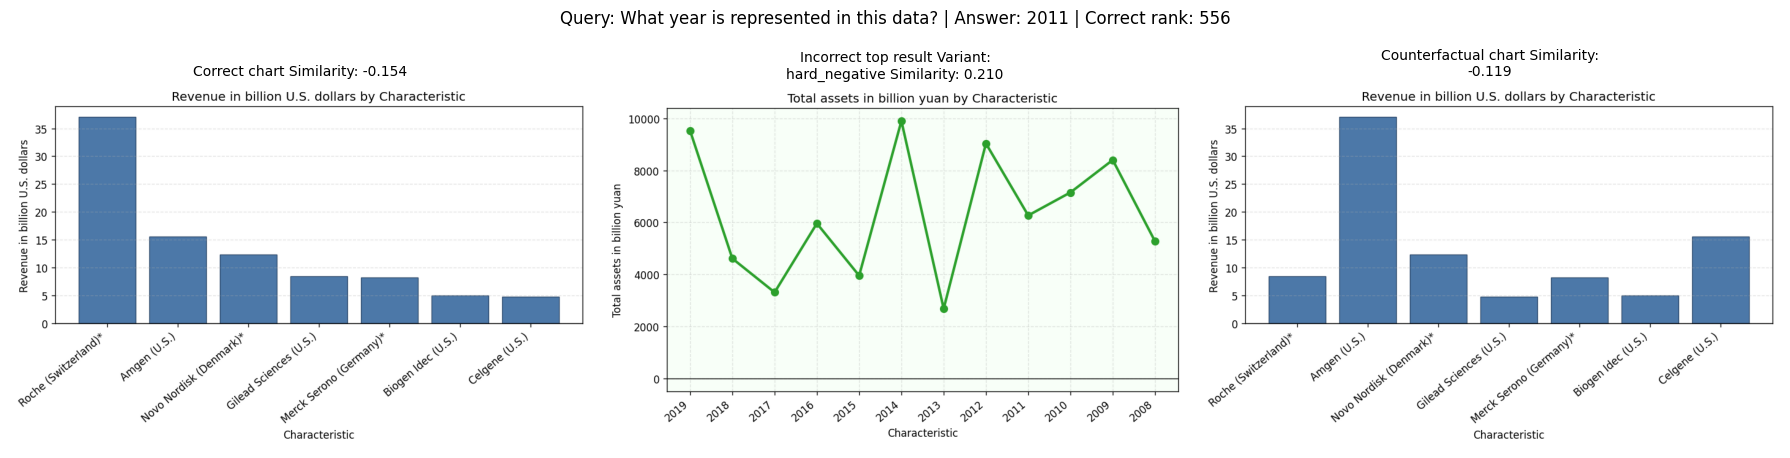

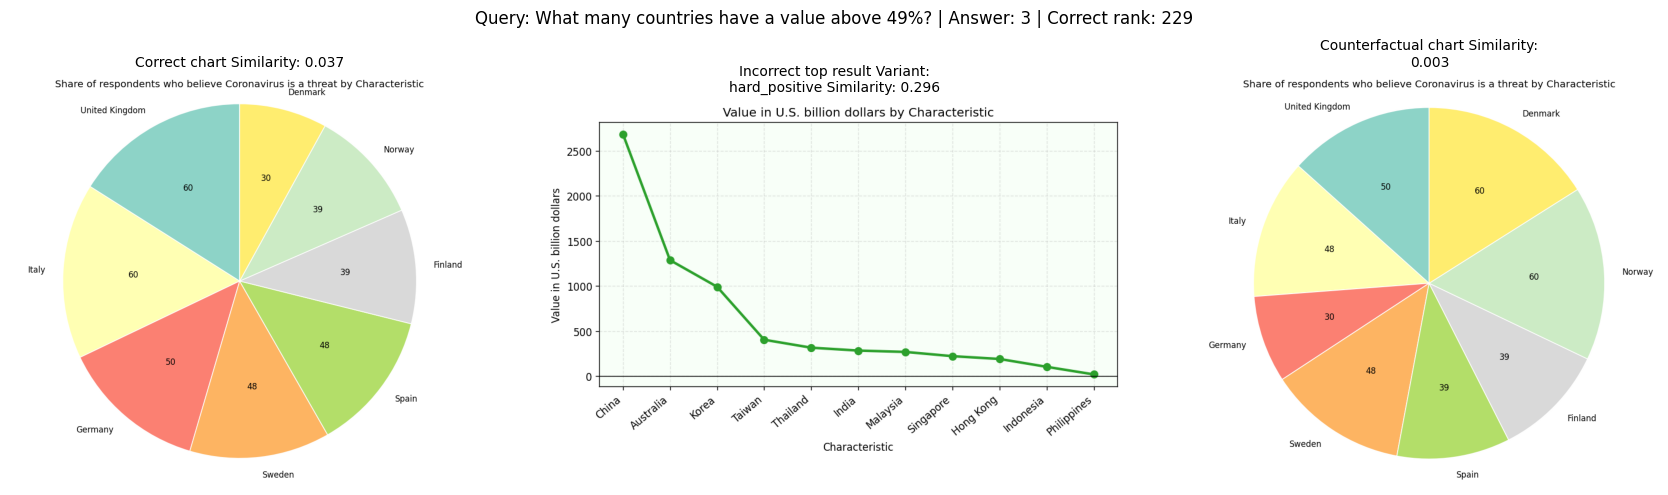

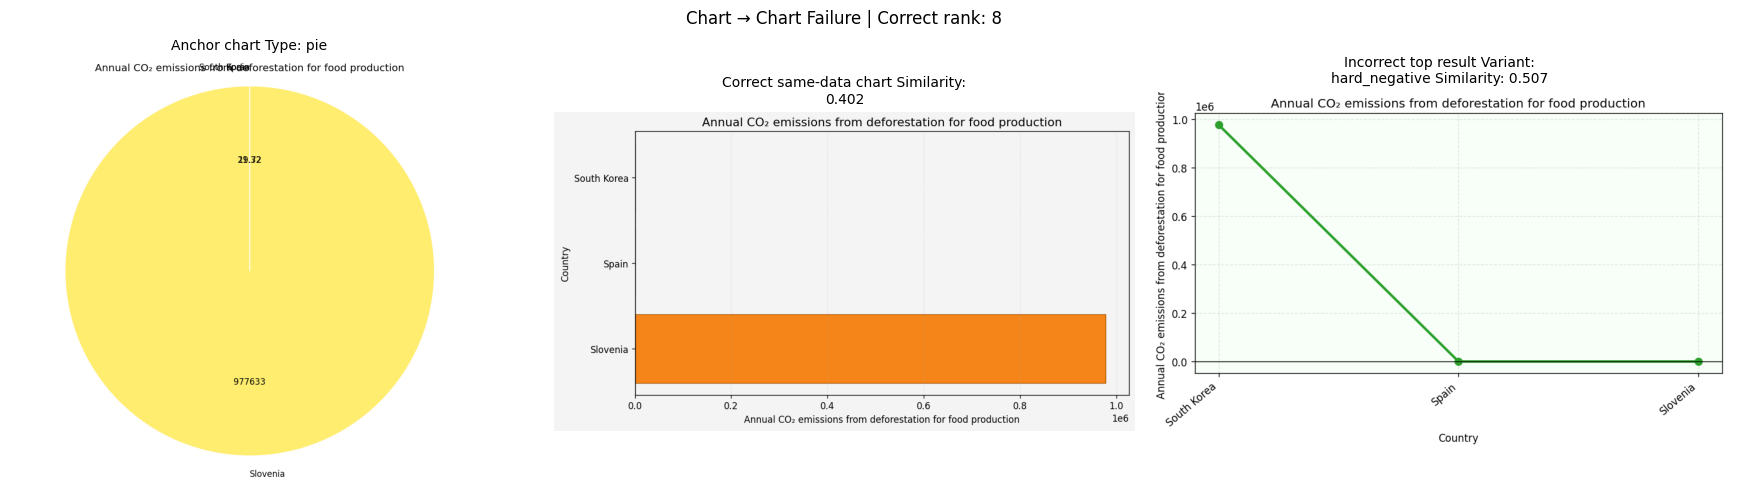

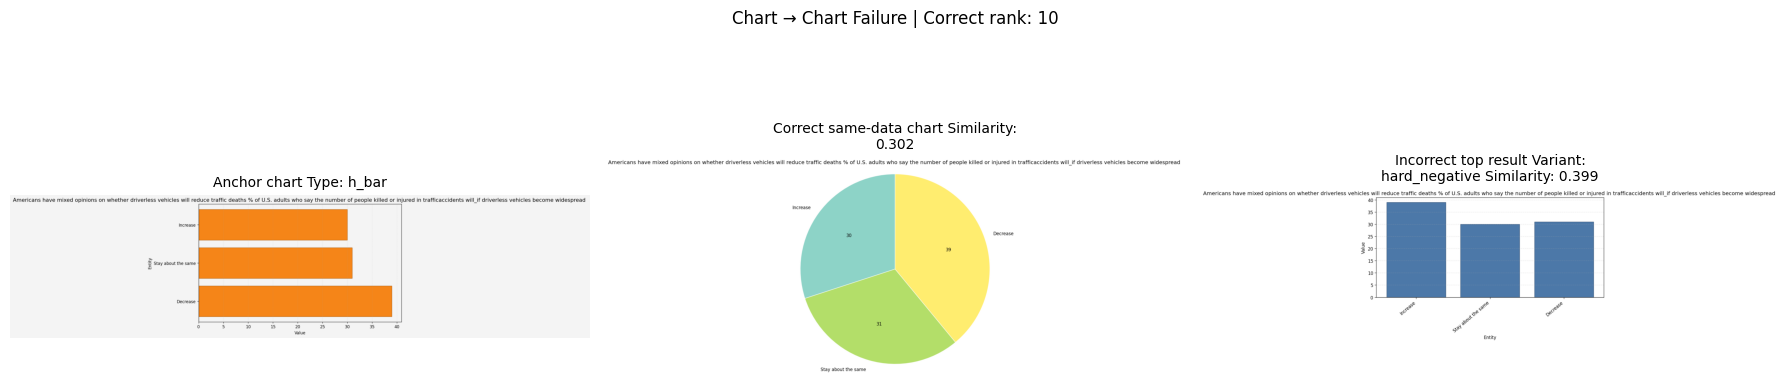

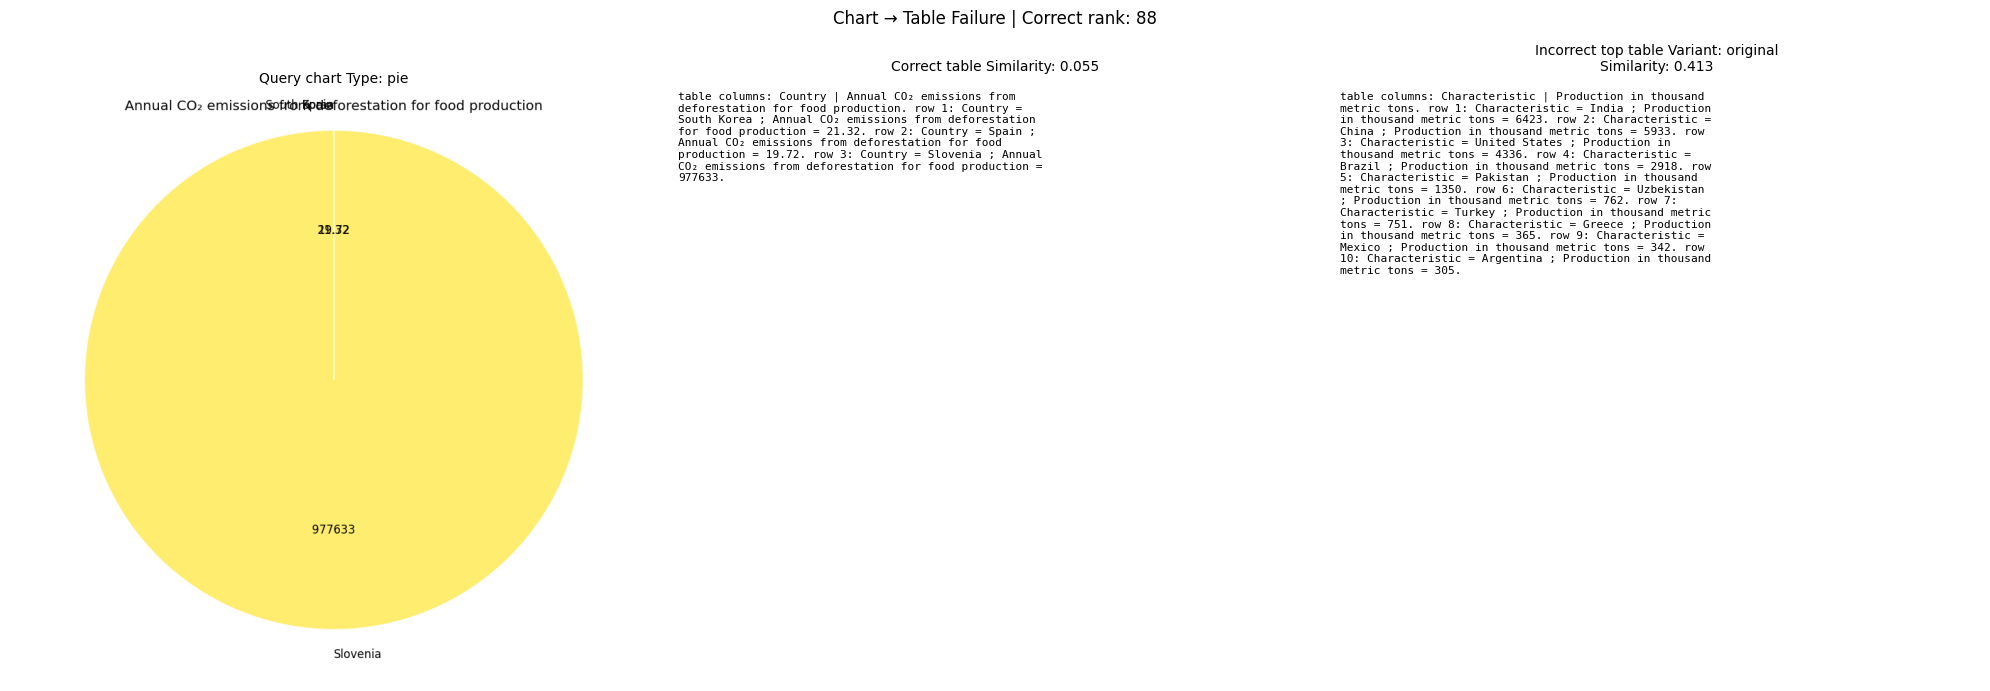

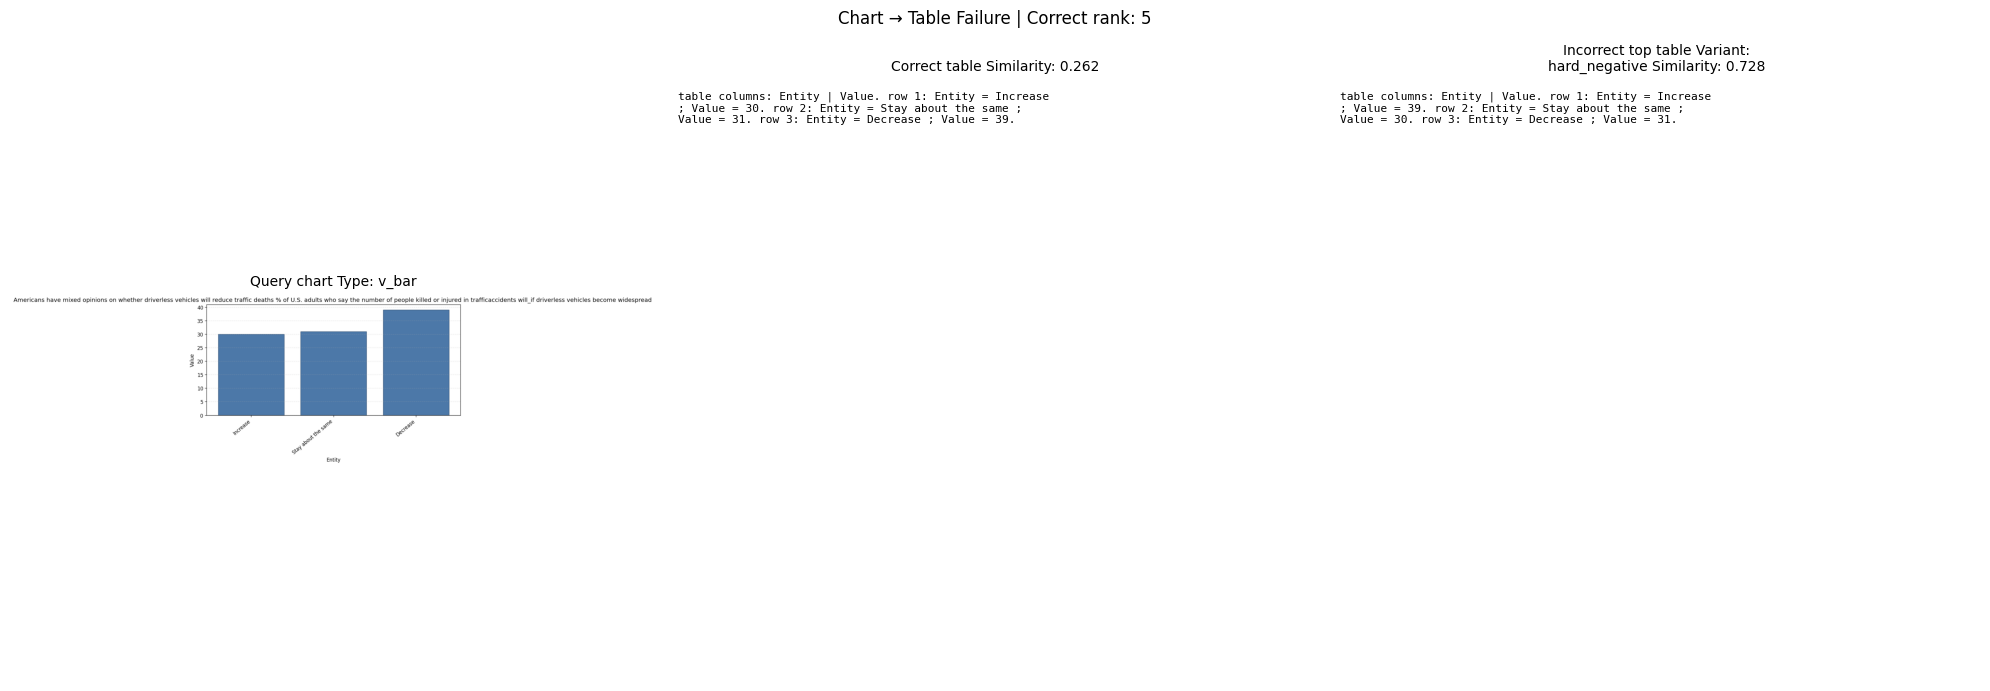


Saved qualitative failure analysis
Figures: 6
Figure directory: /home/pnola130/projects/chart_data_retrieval/reports/failure_analysis/figures


In [30]:
# ============================================================
# BLOCK 16B — Qualitative failure visualizations
# ============================================================

from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

FUSION_EMBEDDING_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "embeddings"
    / "gated_fusion"
)

FAILURE_DIR = (
    PROJECT_ROOT
    / "reports"
    / "failure_analysis"
)

FIGURE_DIR = (
    FAILURE_DIR
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CANONICAL_TABLE_PATH = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "oracle_e5"
    / "canonical_tables.parquet"
)

GENERATED_CHARTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "benchmark"
    / "generated_charts.parquet"
)


# ------------------------------------------------------------
# Load embeddings and metadata
# ------------------------------------------------------------

query_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "query_embeddings.npy"
).astype("float32")

chart_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "chart_embeddings.npy"
).astype("float32")

table_embeddings = np.load(
    FUSION_EMBEDDING_DIR
    / "table_embeddings.npy"
).astype("float32")


query_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "query_metadata.parquet"
).sort_values(
    "embedding_index"
).reset_index(drop=True)

chart_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "chart_metadata.parquet"
).sort_values(
    "embedding_index"
).reset_index(drop=True)

table_metadata_df = pd.read_parquet(
    FUSION_EMBEDDING_DIR
    / "table_metadata.parquet"
).sort_values(
    "embedding_index"
).reset_index(drop=True)


# Load the saved failure lists
query_failures_df = pd.read_parquet(
    FAILURE_DIR
    / "query_chart_failures.parquet"
)

chart_chart_failures_df = pd.read_parquet(
    FAILURE_DIR
    / "chart_chart_failures.parquet"
)

chart_table_failures_df = pd.read_parquet(
    FAILURE_DIR
    / "chart_table_failures.parquet"
)


# ------------------------------------------------------------
# ID-to-row lookups
# ------------------------------------------------------------

query_index_lookup = {
    str(query_id): index
    for index, query_id in enumerate(
        query_metadata_df["query_id"]
    )
}

chart_index_lookup = {
    str(chart_id): index
    for index, chart_id in enumerate(
        chart_metadata_df["chart_id"]
    )
}

table_index_lookup = {
    str(table_id): index
    for index, table_id in enumerate(
        table_metadata_df["data_id"]
    )
}


# ------------------------------------------------------------
# Locate chart images
# ------------------------------------------------------------

chart_image_lookup = {}

if (
    "image_path"
    in chart_metadata_df.columns
):

    for _, row in chart_metadata_df.iterrows():

        path = Path(
            str(row["image_path"])
        )

        if path.exists():

            chart_image_lookup[
                str(row["chart_id"])
            ] = str(path)


if GENERATED_CHARTS_PATH.exists():

    generated_charts_df = pd.read_parquet(
        GENERATED_CHARTS_PATH
    )

    if {
        "chart_id",
        "image_path"
    }.issubset(
        generated_charts_df.columns
    ):

        for _, row in generated_charts_df.iterrows():

            path = Path(
                str(row["image_path"])
            )

            if path.exists():

                chart_image_lookup[
                    str(row["chart_id"])
                ] = str(path)


# Fall back to finding images by filename
generated_image_root = (
    PROJECT_ROOT
    / "generated_charts"
)

if generated_image_root.exists():

    for path in generated_image_root.rglob(
        "*.png"
    ):

        chart_image_lookup.setdefault(
            path.stem,
            str(path)
        )


print(
    "Chart images located:",
    len(chart_image_lookup)
)


# ------------------------------------------------------------
# Load canonical table text
# ------------------------------------------------------------

table_text_lookup = {}

if CANONICAL_TABLE_PATH.exists():

    canonical_tables_df = pd.read_parquet(
        CANONICAL_TABLE_PATH
    )

    if {
        "data_id",
        "canonical_table_text"
    }.issubset(
        canonical_tables_df.columns
    ):

        table_text_lookup = dict(
            zip(
                canonical_tables_df[
                    "data_id"
                ].astype(str),
                canonical_tables_df[
                    "canonical_table_text"
                ].astype(str)
            )
        )


print(
    "Canonical tables located:",
    len(table_text_lookup)
)


# ------------------------------------------------------------
# Select representative failures
# ------------------------------------------------------------

def select_representative_failures(
    dataframe,
    number=2,
    prefer_pie=False
):

    selected_rows = []

    if prefer_pie and (
        "chart_type"
        in dataframe.columns
    ):

        pie_rows = dataframe[
            dataframe["chart_type"]
            == "pie"
        ]

        if len(pie_rows) > 0:

            selected_rows.append(
                pie_rows.iloc[0]
            )

    for failure_type in [
        "counterfactual_outranked_correct_data",
        "other_wrong_candidate"
    ]:

        matching_rows = dataframe[
            dataframe["failure_type"]
            == failure_type
        ]

        for _, row in matching_rows.iterrows():

            row_id = str(
                row["query_id"]
            )

            existing_ids = {
                str(
                    selected["query_id"]
                )
                for selected in selected_rows
            }

            if row_id not in existing_ids:

                selected_rows.append(row)
                break

    for _, row in dataframe.iterrows():

        if len(selected_rows) >= number:
            break

        row_id = str(row["query_id"])

        existing_ids = {
            str(
                selected["query_id"]
            )
            for selected in selected_rows
        }

        if row_id not in existing_ids:
            selected_rows.append(row)

    return selected_rows[:number]


selected_query_failures = (
    select_representative_failures(
        query_failures_df,
        number=2
    )
)

selected_chart_chart_failures = (
    select_representative_failures(
        chart_chart_failures_df,
        number=2,
        prefer_pie=True
    )
)

selected_chart_table_failures = (
    select_representative_failures(
        chart_table_failures_df,
        number=2,
        prefer_pie=True
    )
)


# ------------------------------------------------------------
# Retrieval-detail functions
# ------------------------------------------------------------

test_chart_indices = np.flatnonzero(
    chart_metadata_df["split"]
    .astype(str)
    .to_numpy()
    == "test"
)

test_table_indices = np.flatnonzero(
    table_metadata_df["split"]
    .astype(str)
    .to_numpy()
    == "test"
)


def get_query_chart_details(query_id):

    query_index = query_index_lookup[
        str(query_id)
    ]

    query_row = query_metadata_df.iloc[
        query_index
    ]

    source_id = str(
        query_row["data_id"]
    )

    similarities = (
        query_embeddings[query_index]
        @ chart_embeddings[
            test_chart_indices
        ].T
    )

    candidate_df = (
        chart_metadata_df
        .iloc[test_chart_indices]
        .reset_index(drop=True)
    )

    positive_mask = (
        (
            candidate_df[
                "source_data_id"
            ].astype(str)
            == source_id
        )
        &
        (
            candidate_df[
                "variant_type"
            ] != "hard_negative"
        )
    ).to_numpy()

    counterfactual_mask = (
        (
            candidate_df[
                "source_data_id"
            ].astype(str)
            == source_id
        )
        &
        (
            candidate_df[
                "variant_type"
            ] == "hard_negative"
        )
    ).to_numpy()

    ranking = np.argsort(
        -similarities
    )

    positive_rank = int(
        np.flatnonzero(
            positive_mask[ranking]
        )[0]
        + 1
    )

    top_position = int(
        ranking[0]
    )

    correct_position = int(
        np.flatnonzero(
            positive_mask
        )[
            np.argmax(
                similarities[
                    positive_mask
                ]
            )
        ]
    )

    counterfactual_position = int(
        np.flatnonzero(
            counterfactual_mask
        )[
            np.argmax(
                similarities[
                    counterfactual_mask
                ]
            )
        ]
    )

    return {
        "query_id": str(query_id),
        "question": str(
            query_row.get(
                "question",
                query_row.get(
                    "query",
                    ""
                )
            )
        ),
        "answer": str(
            query_row.get(
                "answer",
                ""
            )
        ),
        "positive_rank": positive_rank,
        "correct_chart_id": str(
            candidate_df.iloc[
                correct_position
            ]["chart_id"]
        ),
        "top_chart_id": str(
            candidate_df.iloc[
                top_position
            ]["chart_id"]
        ),
        "top_chart_source": str(
            candidate_df.iloc[
                top_position
            ]["source_data_id"]
        ),
        "top_chart_variant": str(
            candidate_df.iloc[
                top_position
            ]["variant_type"]
        ),
        "counterfactual_chart_id": str(
            candidate_df.iloc[
                counterfactual_position
            ]["chart_id"]
        ),
        "correct_similarity": float(
            similarities[
                correct_position
            ]
        ),
        "top_similarity": float(
            similarities[
                top_position
            ]
        ),
        "counterfactual_similarity": float(
            similarities[
                counterfactual_position
            ]
        )
    }


def get_chart_chart_details(chart_id):

    query_index = chart_index_lookup[
        str(chart_id)
    ]

    query_row = chart_metadata_df.iloc[
        query_index
    ]

    source_id = str(
        query_row["source_data_id"]
    )

    similarities = (
        chart_embeddings[query_index]
        @ chart_embeddings[
            test_chart_indices
        ].T
    )

    candidate_df = (
        chart_metadata_df
        .iloc[test_chart_indices]
        .reset_index(drop=True)
    )

    self_mask = (
        candidate_df["chart_id"]
        .astype(str)
        == str(chart_id)
    ).to_numpy()

    similarities[self_mask] = -np.inf

    positive_mask = (
        (
            candidate_df[
                "source_data_id"
            ].astype(str)
            == source_id
        )
        &
        (
            candidate_df[
                "variant_type"
            ] != "hard_negative"
        )
        &
        (~self_mask)
    ).to_numpy()

    counterfactual_mask = (
        (
            candidate_df[
                "source_data_id"
            ].astype(str)
            == source_id
        )
        &
        (
            candidate_df[
                "variant_type"
            ] == "hard_negative"
        )
    ).to_numpy()

    ranking = np.argsort(
        -similarities
    )

    positive_rank = int(
        np.flatnonzero(
            positive_mask[ranking]
        )[0]
        + 1
    )

    top_position = int(ranking[0])

    correct_position = int(
        np.flatnonzero(
            positive_mask
        )[
            np.argmax(
                similarities[
                    positive_mask
                ]
            )
        ]
    )

    counterfactual_position = int(
        np.flatnonzero(
            counterfactual_mask
        )[
            np.argmax(
                similarities[
                    counterfactual_mask
                ]
            )
        ]
    )

    return {
        "anchor_chart_id": str(chart_id),
        "chart_type": str(
            query_row["chart_type"]
        ),
        "positive_rank": positive_rank,
        "correct_chart_id": str(
            candidate_df.iloc[
                correct_position
            ]["chart_id"]
        ),
        "top_chart_id": str(
            candidate_df.iloc[
                top_position
            ]["chart_id"]
        ),
        "top_chart_variant": str(
            candidate_df.iloc[
                top_position
            ]["variant_type"]
        ),
        "counterfactual_chart_id": str(
            candidate_df.iloc[
                counterfactual_position
            ]["chart_id"]
        ),
        "correct_similarity": float(
            similarities[
                correct_position
            ]
        ),
        "top_similarity": float(
            similarities[
                top_position
            ]
        ),
        "counterfactual_similarity": float(
            similarities[
                counterfactual_position
            ]
        )
    }


def get_chart_table_details(chart_id):

    chart_index = chart_index_lookup[
        str(chart_id)
    ]

    chart_row = chart_metadata_df.iloc[
        chart_index
    ]

    source_id = str(
        chart_row["source_data_id"]
    )

    similarities = (
        chart_embeddings[chart_index]
        @ table_embeddings[
            test_table_indices
        ].T
    )

    candidate_df = (
        table_metadata_df
        .iloc[test_table_indices]
        .reset_index(drop=True)
    )

    positive_mask = (
        (
            candidate_df[
                "source_data_id"
            ].astype(str)
            == source_id
        )
        &
        (
            candidate_df[
                "table_variant_type"
            ] == "original"
        )
    ).to_numpy()

    counterfactual_mask = (
        (
            candidate_df[
                "source_data_id"
            ].astype(str)
            == source_id
        )
        &
        (
            candidate_df[
                "table_variant_type"
            ] == "hard_negative"
        )
    ).to_numpy()

    ranking = np.argsort(
        -similarities
    )

    positive_rank = int(
        np.flatnonzero(
            positive_mask[ranking]
        )[0]
        + 1
    )

    top_position = int(ranking[0])

    correct_position = int(
        np.flatnonzero(
            positive_mask
        )[0]
    )

    counterfactual_position = int(
        np.flatnonzero(
            counterfactual_mask
        )[0]
    )

    return {
        "query_chart_id": str(chart_id),
        "chart_type": str(
            chart_row["chart_type"]
        ),
        "positive_rank": positive_rank,
        "correct_table_id": str(
            candidate_df.iloc[
                correct_position
            ]["data_id"]
        ),
        "top_table_id": str(
            candidate_df.iloc[
                top_position
            ]["data_id"]
        ),
        "top_table_variant": str(
            candidate_df.iloc[
                top_position
            ]["table_variant_type"]
        ),
        "counterfactual_table_id": str(
            candidate_df.iloc[
                counterfactual_position
            ]["data_id"]
        ),
        "correct_similarity": float(
            similarities[
                correct_position
            ]
        ),
        "top_similarity": float(
            similarities[
                top_position
            ]
        ),
        "counterfactual_similarity": float(
            similarities[
                counterfactual_position
            ]
        )
    }


# ------------------------------------------------------------
# Create qualitative records
# ------------------------------------------------------------

query_visual_records = [
    get_query_chart_details(
        row["query_id"]
    )
    for row in selected_query_failures
]

chart_chart_visual_records = [
    get_chart_chart_details(
        row["query_id"]
    )
    for row in selected_chart_chart_failures
]

chart_table_visual_records = [
    get_chart_table_details(
        row["query_id"]
    )
    for row in selected_chart_table_failures
]


query_visual_df = pd.DataFrame(
    query_visual_records
)

chart_chart_visual_df = pd.DataFrame(
    chart_chart_visual_records
)

chart_table_visual_df = pd.DataFrame(
    chart_table_visual_records
)


print("Selected query→chart examples")
display(query_visual_df)

print("\nSelected chart→chart examples")
display(chart_chart_visual_df)

print("\nSelected chart→table examples")
display(chart_table_visual_df)


# ------------------------------------------------------------
# Visualization helpers
# ------------------------------------------------------------

def show_chart(
    axis,
    chart_id,
    title
):

    axis.axis("off")

    image_path = chart_image_lookup.get(
        str(chart_id)
    )

    if (
        image_path is not None
        and Path(image_path).exists()
    ):

        image = Image.open(
            image_path
        ).convert("RGB")

        axis.imshow(image)

    else:

        axis.text(
            0.5,
            0.5,
            "Image not found",
            ha="center",
            va="center",
            fontsize=12
        )

    axis.set_title(
        textwrap.fill(
            title,
            width=35
        ),
        fontsize=10
    )


def show_table_text(
    axis,
    table_id,
    title
):

    axis.axis("off")

    table_text = table_text_lookup.get(
        str(table_id),
        "Table text not found"
    )

    table_text = table_text[:1500]

    axis.text(
        0.01,
        0.98,
        textwrap.fill(
            table_text,
            width=55
        ),
        ha="left",
        va="top",
        fontsize=8,
        family="monospace"
    )

    axis.set_title(
        textwrap.fill(
            title,
            width=38
        ),
        fontsize=10
    )


# ------------------------------------------------------------
# Query → Chart figures
# ------------------------------------------------------------

for example_number, record in enumerate(
    query_visual_records,
    start=1
):

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5)
    )

    show_chart(
        axes[0],
        record["correct_chart_id"],
        (
            "Correct chart\n"
            f"Similarity: "
            f"{record['correct_similarity']:.3f}"
        )
    )

    show_chart(
        axes[1],
        record["top_chart_id"],
        (
            "Incorrect top result\n"
            f"Variant: "
            f"{record['top_chart_variant']}\n"
            f"Similarity: "
            f"{record['top_similarity']:.3f}"
        )
    )

    show_chart(
        axes[2],
        record[
            "counterfactual_chart_id"
        ],
        (
            "Counterfactual chart\n"
            f"Similarity: "
            f"{record['counterfactual_similarity']:.3f}"
        )
    )

    figure.suptitle(
        textwrap.fill(
            (
                f"Query: {record['question']} | "
                f"Answer: {record['answer']} | "
                f"Correct rank: "
                f"{record['positive_rank']}"
            ),
            width=120
        ),
        fontsize=12
    )

    figure.tight_layout()

    output_path = (
        FIGURE_DIR
        / (
            f"query_chart_failure_"
            f"{example_number}.png"
        )
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# Chart → Chart figures
# ------------------------------------------------------------

for example_number, record in enumerate(
    chart_chart_visual_records,
    start=1
):

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5)
    )

    show_chart(
        axes[0],
        record["anchor_chart_id"],
        (
            "Anchor chart\n"
            f"Type: {record['chart_type']}"
        )
    )

    show_chart(
        axes[1],
        record["correct_chart_id"],
        (
            "Correct same-data chart\n"
            f"Similarity: "
            f"{record['correct_similarity']:.3f}"
        )
    )

    show_chart(
        axes[2],
        record["top_chart_id"],
        (
            "Incorrect top result\n"
            f"Variant: "
            f"{record['top_chart_variant']}\n"
            f"Similarity: "
            f"{record['top_similarity']:.3f}"
        )
    )

    figure.suptitle(
        (
            "Chart → Chart Failure | "
            f"Correct rank: "
            f"{record['positive_rank']}"
        ),
        fontsize=12
    )

    figure.tight_layout()

    output_path = (
        FIGURE_DIR
        / (
            f"chart_chart_failure_"
            f"{example_number}.png"
        )
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# Chart → Table figures
# ------------------------------------------------------------

for example_number, record in enumerate(
    chart_table_visual_records,
    start=1
):

    figure, axes = plt.subplots(
        1,
        3,
        figsize=(20, 7)
    )

    show_chart(
        axes[0],
        record["query_chart_id"],
        (
            "Query chart\n"
            f"Type: {record['chart_type']}"
        )
    )

    show_table_text(
        axes[1],
        record["correct_table_id"],
        (
            "Correct table\n"
            f"Similarity: "
            f"{record['correct_similarity']:.3f}"
        )
    )

    show_table_text(
        axes[2],
        record["top_table_id"],
        (
            "Incorrect top table\n"
            f"Variant: "
            f"{record['top_table_variant']}\n"
            f"Similarity: "
            f"{record['top_similarity']:.3f}"
        )
    )

    figure.suptitle(
        (
            "Chart → Table Failure | "
            f"Correct rank: "
            f"{record['positive_rank']}"
        ),
        fontsize=12
    )

    figure.tight_layout()

    output_path = (
        FIGURE_DIR
        / (
            f"chart_table_failure_"
            f"{example_number}.png"
        )
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# Save qualitative records
# ------------------------------------------------------------

query_visual_df.to_csv(
    FAILURE_DIR
    / "qualitative_query_chart_examples.csv",
    index=False
)

chart_chart_visual_df.to_csv(
    FAILURE_DIR
    / "qualitative_chart_chart_examples.csv",
    index=False
)

chart_table_visual_df.to_csv(
    FAILURE_DIR
    / "qualitative_chart_table_examples.csv",
    index=False
)


print("\nSaved qualitative failure analysis")

print(
    "Figures:",
    len(
        list(
            FIGURE_DIR.glob(
                "*.png"
            )
        )
    )
)

print(
    "Figure directory:",
    FIGURE_DIR
)

Comparison rows: 9
Chart-type rows: 8
Failure-summary rows: 3


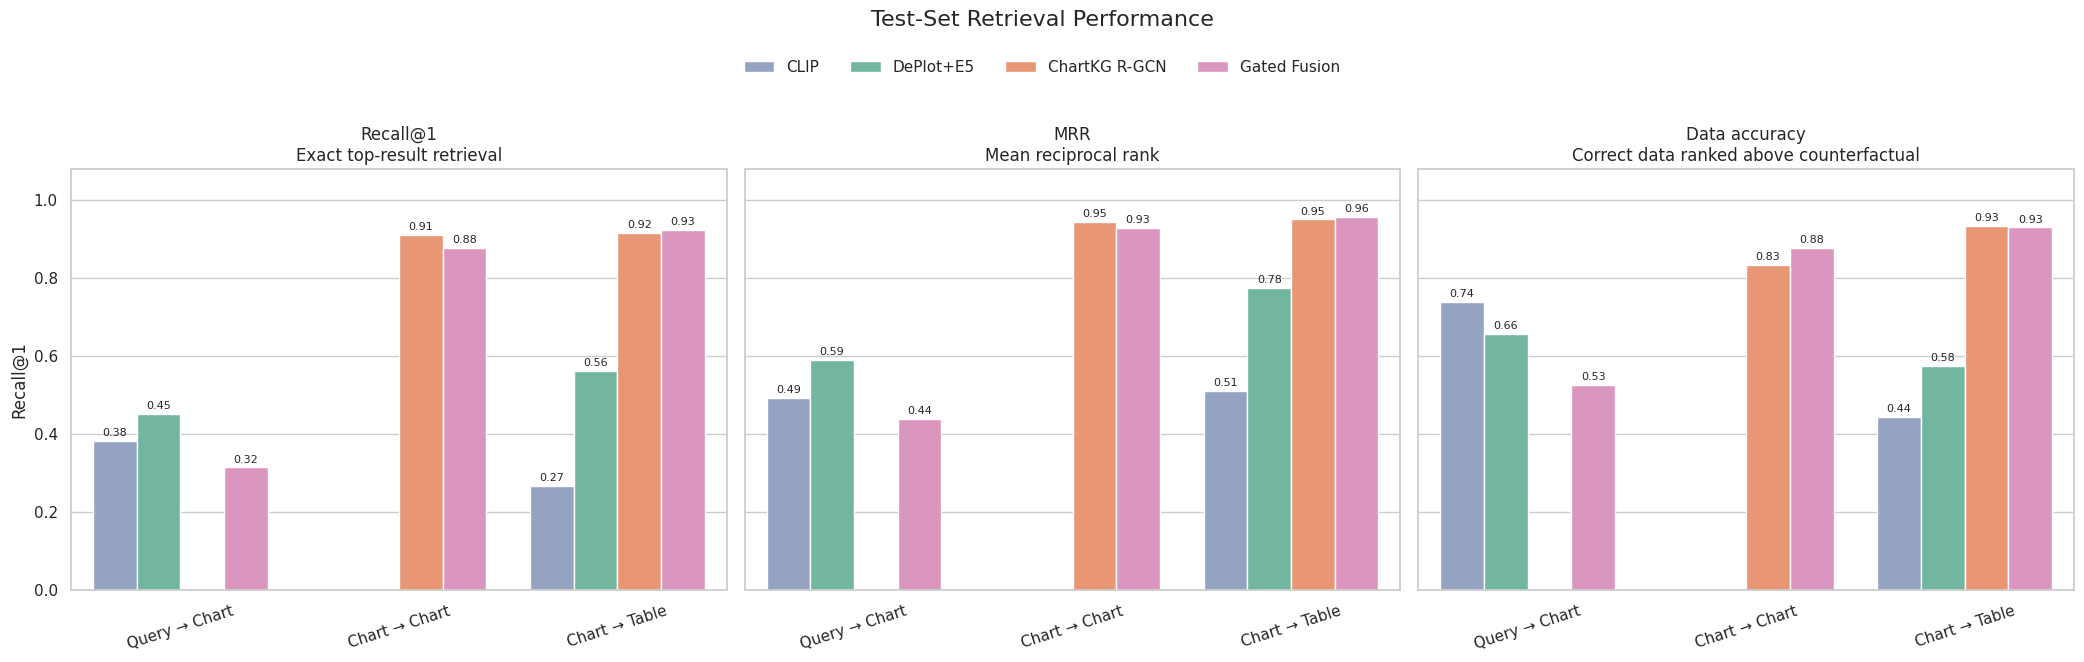

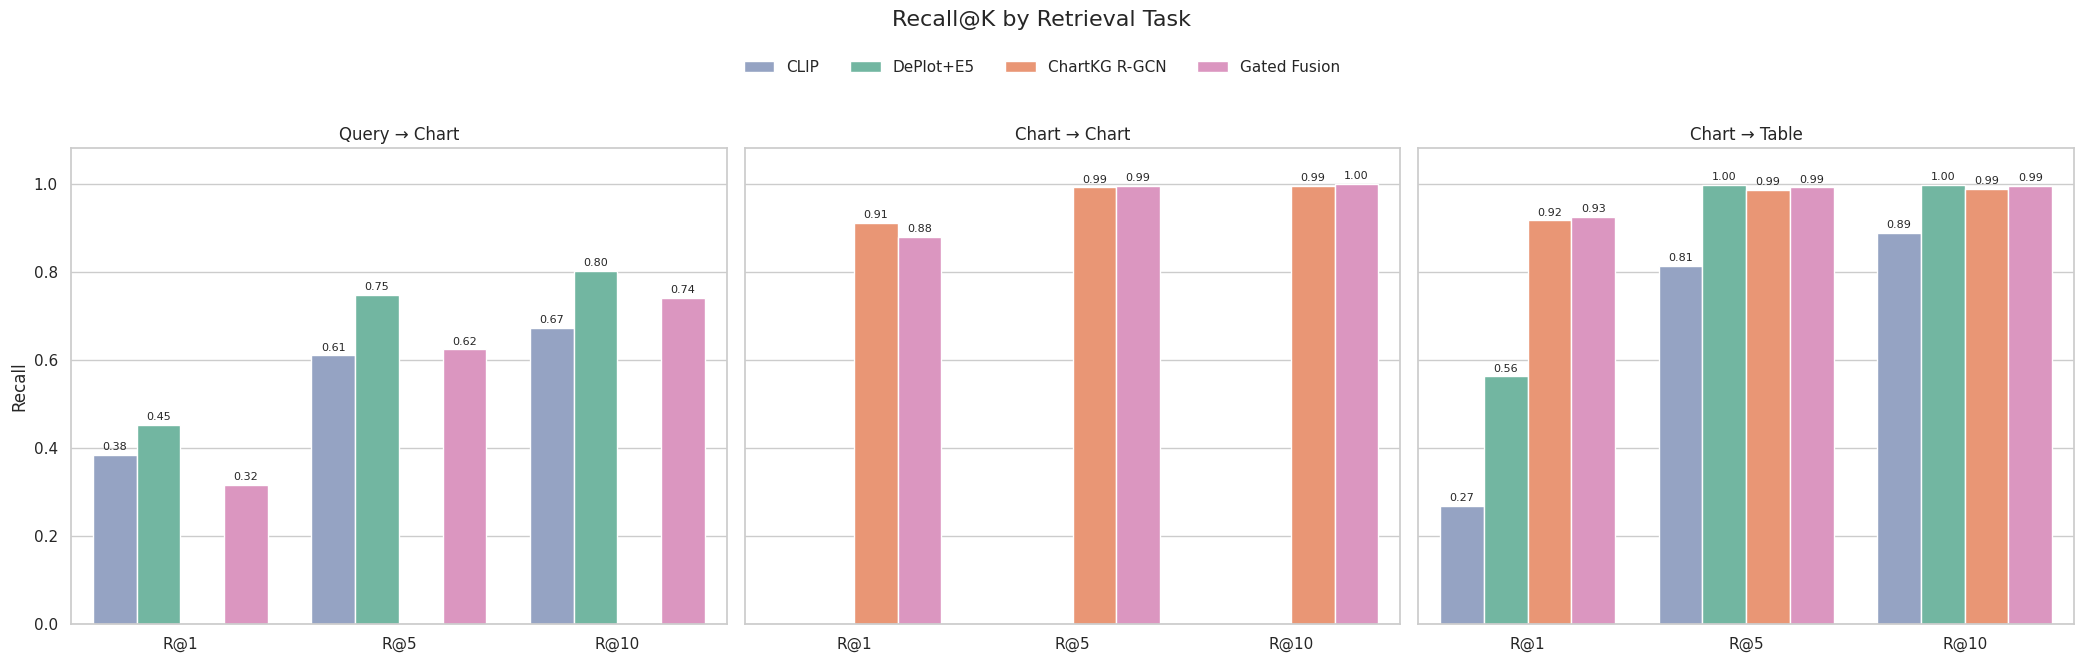

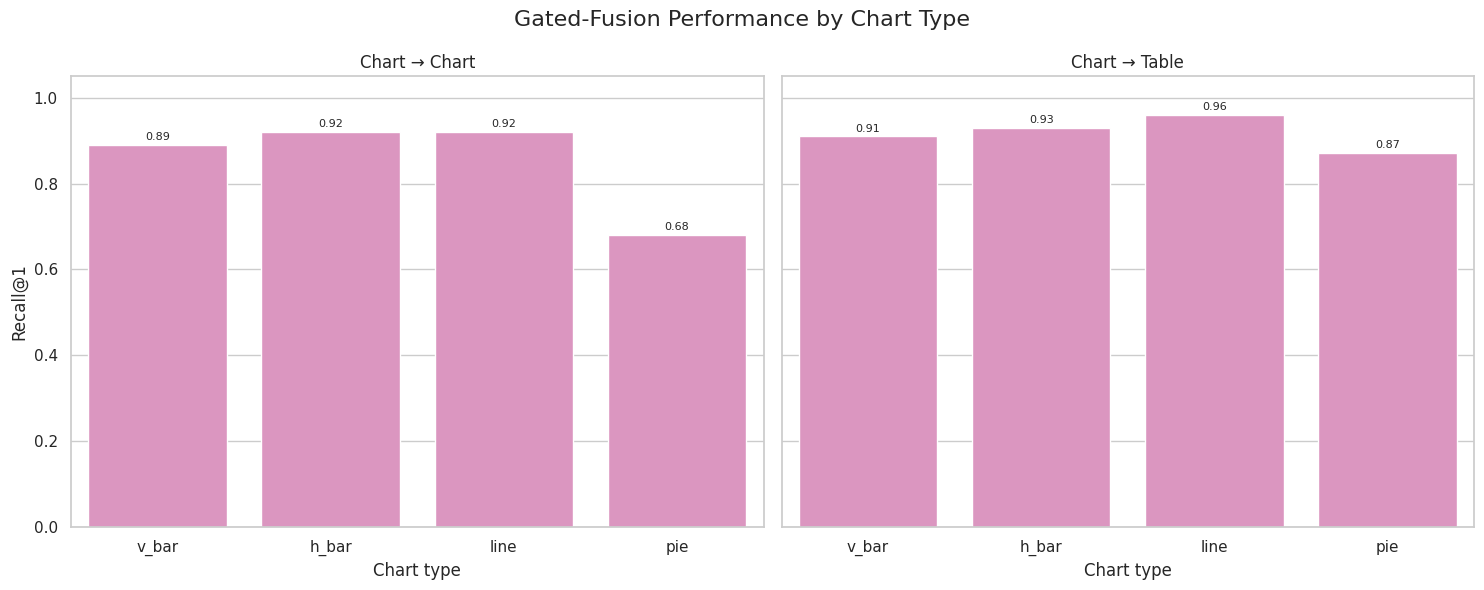

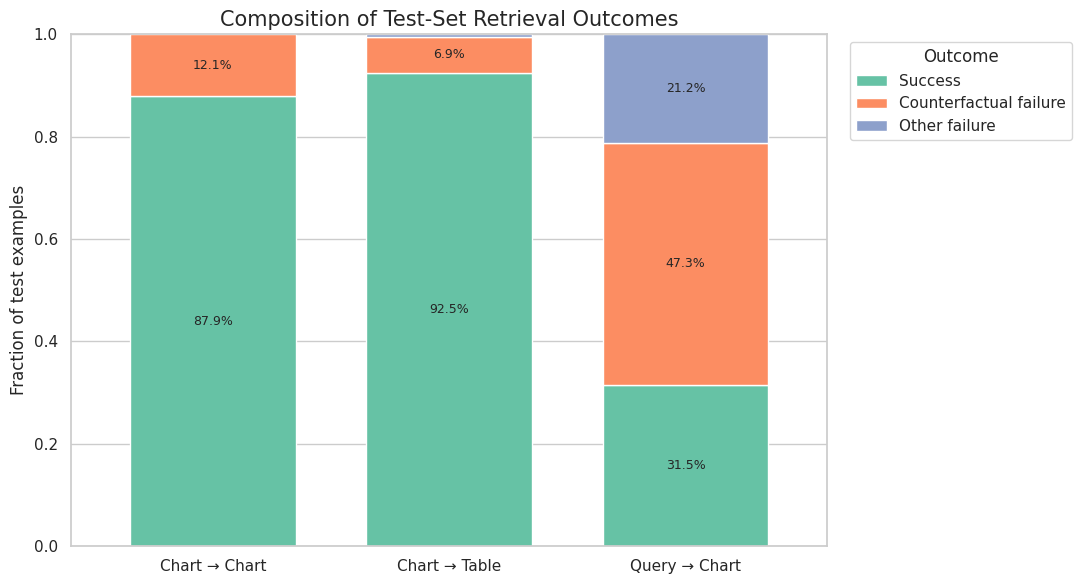

/tmp/ipykernel_3628480/2104423904.py:633: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(


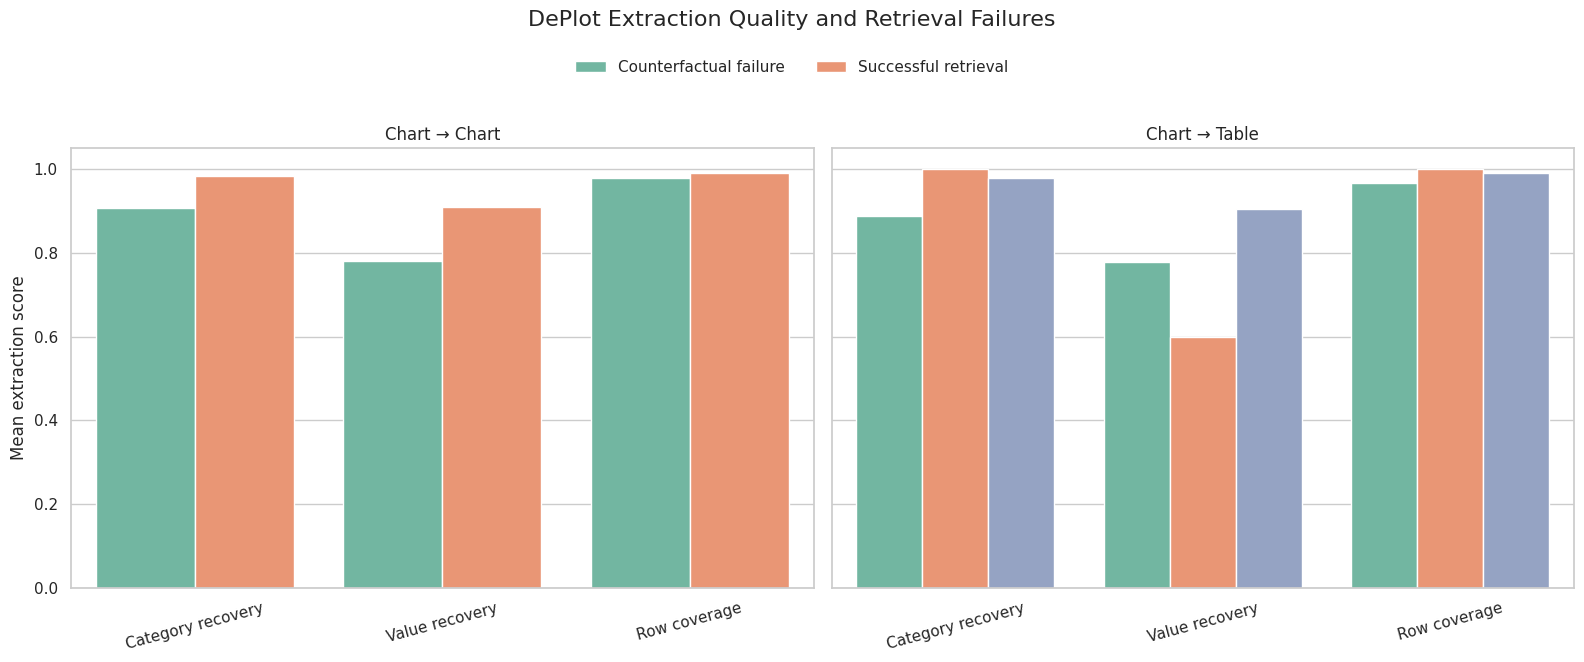


Saved final figures
deplot_quality_vs_retrieval.png : True
failure_composition.png : True
model_comparison.png : True
performance_by_chart_type.png : True
recall_at_k_comparison.png : True

Figure directory: /home/pnola130/projects/chart_data_retrieval/reports/figures


In [31]:
# ============================================================
# BLOCK 17 — Final performance and failure-analysis plots
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

FINAL_COMPARISON_DIR = (
    PROJECT_ROOT
    / "reports"
    / "final_comparison"
)

FAILURE_DIR = (
    PROJECT_ROOT
    / "reports"
    / "failure_analysis"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "reports"
    / "figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Plot style
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

MODEL_ORDER = [
    "CLIP",
    "DePlot+E5",
    "ChartKG R-GCN",
    "Gated Fusion"
]

MODEL_COLORS = {
    "CLIP": "#8DA0CB",
    "DePlot+E5": "#66C2A5",
    "ChartKG R-GCN": "#FC8D62",
    "Gated Fusion": "#E78AC3"
}


# ------------------------------------------------------------
# Load final results
# ------------------------------------------------------------

comparison_df = pd.read_csv(
    FINAL_COMPARISON_DIR
    / "final_model_comparison.csv"
)

comparison_df = comparison_df[
    comparison_df["is_oracle"]
    == False
].copy()

chart_type_df = pd.read_csv(
    FAILURE_DIR
    / "failure_by_chart_type.csv"
)

failure_summary_df = pd.read_csv(
    FAILURE_DIR
    / "failure_summary.csv"
)


print("Comparison rows:", len(comparison_df))
print("Chart-type rows:", len(chart_type_df))
print("Failure-summary rows:", len(failure_summary_df))


# ------------------------------------------------------------
# Helper for bar labels
# ------------------------------------------------------------

def add_bar_labels(
    axis,
    decimal_places=2
):

    format_string = (
        f"%.{decimal_places}f"
    )

    for container in axis.containers:

        axis.bar_label(
            container,
            fmt=format_string,
            fontsize=8,
            padding=2
        )


# ============================================================
# Figure 1: Main model comparison
# ============================================================

metric_specs = [
    (
        "recall_at_1",
        "Recall@1",
        "Exact top-result retrieval"
    ),
    (
        "mrr",
        "MRR",
        "Mean reciprocal rank"
    ),
    (
        "data_over_counterfactual_accuracy",
        "Data accuracy",
        "Correct data ranked above counterfactual"
    )
]

figure, axes = plt.subplots(
    1,
    3,
    figsize=(21, 6),
    sharey=True
)

for axis, (
    metric_column,
    metric_label,
    subtitle
) in zip(
    axes,
    metric_specs
):

    sns.barplot(
        data=comparison_df,
        x="task_name",
        y=metric_column,
        hue="model",
        hue_order=MODEL_ORDER,
        palette=MODEL_COLORS,
        errorbar=None,
        ax=axis
    )

    axis.set_title(
        f"{metric_label}\n{subtitle}",
        fontsize=12
    )

    axis.set_xlabel("")
    axis.set_ylabel(metric_label)
    axis.set_ylim(0, 1.08)

    axis.tick_params(
        axis="x",
        rotation=18
    )

    add_bar_labels(
        axis,
        decimal_places=2
    )

    if axis is not axes[0]:

        legend = axis.get_legend()

        if legend is not None:
            legend.remove()


handles, labels = (
    axes[0].get_legend_handles_labels()
)

axes[0].legend_.remove()

figure.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=4,
    frameon=False
)

figure.suptitle(
    "Test-Set Retrieval Performance",
    fontsize=16,
    y=1.10
)

figure.tight_layout()

figure.savefig(
    FIGURE_DIR
    / "model_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

figure.savefig(
    FIGURE_DIR
    / "model_comparison.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 2: Recall@K comparison
# ============================================================

recall_long_df = comparison_df.melt(
    id_vars=[
        "task_name",
        "model"
    ],
    value_vars=[
        "recall_at_1",
        "recall_at_5",
        "recall_at_10"
    ],
    var_name="metric",
    value_name="score"
)

recall_long_df["metric"] = (
    recall_long_df["metric"]
    .map(
        {
            "recall_at_1": "R@1",
            "recall_at_5": "R@5",
            "recall_at_10": "R@10"
        }
    )
)

tasks = [
    "Query → Chart",
    "Chart → Chart",
    "Chart → Table"
]

figure, axes = plt.subplots(
    1,
    3,
    figsize=(21, 6),
    sharey=True
)

for axis, task_name in zip(
    axes,
    tasks
):

    task_data = recall_long_df[
        recall_long_df["task_name"]
        == task_name
    ]

    sns.barplot(
        data=task_data,
        x="metric",
        y="score",
        hue="model",
        hue_order=MODEL_ORDER,
        palette=MODEL_COLORS,
        errorbar=None,
        ax=axis
    )

    axis.set_title(task_name)
    axis.set_xlabel("")
    axis.set_ylabel(
        "Recall"
        if axis is axes[0]
        else ""
    )
    axis.set_ylim(0, 1.08)

    add_bar_labels(
        axis,
        decimal_places=2
    )

    legend = axis.get_legend()

    if legend is not None:
        legend.remove()


handles, labels = (
    axes[0].get_legend_handles_labels()
)

figure.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=4,
    frameon=False
)

figure.suptitle(
    "Recall@K by Retrieval Task",
    fontsize=16,
    y=1.10
)

figure.tight_layout()

figure.savefig(
    FIGURE_DIR
    / "recall_at_k_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

figure.savefig(
    FIGURE_DIR
    / "recall_at_k_comparison.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 3: Gated-fusion chart-type performance
# ============================================================

chart_type_plot_df = (
    chart_type_df.copy()
)

chart_type_order = [
    "v_bar",
    "h_bar",
    "line",
    "pie"
]

figure, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    sharey=True
)

for axis, task_name in zip(
    axes,
    [
        "Chart → Chart",
        "Chart → Table"
    ]
):

    task_data = chart_type_plot_df[
        chart_type_plot_df["task_name"]
        == task_name
    ]

    sns.barplot(
        data=task_data,
        x="chart_type",
        y="recall_at_1",
        order=chart_type_order,
        color="#E78AC3",
        errorbar=None,
        ax=axis
    )

    axis.set_title(task_name)
    axis.set_xlabel("Chart type")
    axis.set_ylabel(
        "Recall@1"
        if axis is axes[0]
        else ""
    )
    axis.set_ylim(0, 1.05)

    add_bar_labels(
        axis,
        decimal_places=2
    )


figure.suptitle(
    "Gated-Fusion Performance by Chart Type",
    fontsize=16
)

figure.tight_layout()

figure.savefig(
    FIGURE_DIR
    / "performance_by_chart_type.png",
    dpi=220,
    bbox_inches="tight"
)

figure.savefig(
    FIGURE_DIR
    / "performance_by_chart_type.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 4: Failure composition
# ============================================================

failure_plot_df = (
    failure_summary_df[
        [
            "task_name",
            "successful_at_rank_1",
            "counterfactual_failures",
            "other_wrong_candidate_failures"
        ]
    ]
    .set_index("task_name")
)

failure_rate_df = (
    failure_plot_df.div(
        failure_plot_df.sum(axis=1),
        axis=0
    )
)

failure_rate_df = failure_rate_df.rename(
    columns={
        "successful_at_rank_1": "Success",
        "counterfactual_failures": (
            "Counterfactual failure"
        ),
        "other_wrong_candidate_failures": (
            "Other failure"
        )
    }
)

axis = failure_rate_df.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=[
        "#66C2A5",
        "#FC8D62",
        "#8DA0CB"
    ],
    width=0.7
)

axis.set_title(
    "Composition of Test-Set Retrieval Outcomes",
    fontsize=15
)

axis.set_xlabel("")
axis.set_ylabel("Fraction of test examples")
axis.set_ylim(0, 1.0)

axis.tick_params(
    axis="x",
    rotation=0
)

axis.legend(
    title="Outcome",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for container in axis.containers:

    labels = [
        f"{value:.1%}"
        if value >= 0.04
        else ""
        for value in container.datavalues
    ]

    axis.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9
    )


plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "failure_composition.png",
    dpi=220,
    bbox_inches="tight"
)

plt.savefig(
    FIGURE_DIR
    / "failure_composition.pdf",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Figure 5: DePlot extraction quality vs retrieval outcome
# ============================================================

DEPLOT_ANALYSIS_PATH = (
    FAILURE_DIR
    / "deplot_quality_vs_retrieval.csv"
)

if DEPLOT_ANALYSIS_PATH.exists():

    deplot_quality_df = pd.read_csv(
        DEPLOT_ANALYSIS_PATH
    )

    deplot_plot_df = deplot_quality_df.melt(
        id_vars=[
            "task_name",
            "failure_type"
        ],
        value_vars=[
            column
            for column in [
                "category_recovery_rate",
                "tolerant_value_recovery",
                "row_coverage"
            ]
            if column
            in deplot_quality_df.columns
        ],
        var_name="extraction_metric",
        value_name="score"
    )

    deplot_plot_df[
        "extraction_metric"
    ] = deplot_plot_df[
        "extraction_metric"
    ].map(
        {
            "category_recovery_rate": (
                "Category recovery"
            ),
            "tolerant_value_recovery": (
                "Value recovery"
            ),
            "row_coverage": (
                "Row coverage"
            )
        }
    )

    deplot_plot_df[
        "retrieval_outcome"
    ] = deplot_plot_df[
        "failure_type"
    ].map(
        {
            "success": "Successful retrieval",
            (
                "counterfactual_"
                "outranked_correct_data"
            ): "Counterfactual failure",
            "other_wrong_candidate": (
                "Other failure"
            )
        }
    )

    figure, axes = plt.subplots(
        1,
        2,
        figsize=(16, 6),
        sharey=True
    )

    for axis, task_name in zip(
        axes,
        [
            "Chart → Chart",
            "Chart → Table"
        ]
    ):

        task_data = deplot_plot_df[
            deplot_plot_df["task_name"]
            == task_name
        ]

        sns.barplot(
            data=task_data,
            x="extraction_metric",
            y="score",
            hue="retrieval_outcome",
            palette=[
                "#66C2A5",
                "#FC8D62",
                "#8DA0CB"
            ],
            errorbar=None,
            ax=axis
        )

        axis.set_title(task_name)
        axis.set_xlabel("")
        axis.set_ylabel(
            "Mean extraction score"
            if axis is axes[0]
            else ""
        )
        axis.set_ylim(0, 1.05)

        axis.tick_params(
            axis="x",
            rotation=15
        )

        if axis is not axes[0]:

            legend = axis.get_legend()

            if legend is not None:
                legend.remove()


    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    axes[0].legend_.remove()

    figure.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.04),
        ncol=3,
        frameon=False
    )

    figure.suptitle(
        "DePlot Extraction Quality and Retrieval Failures",
        fontsize=16,
        y=1.10
    )

    figure.tight_layout()

    figure.savefig(
        FIGURE_DIR
        / "deplot_quality_vs_retrieval.png",
        dpi=220,
        bbox_inches="tight"
    )

    figure.savefig(
        FIGURE_DIR
        / "deplot_quality_vs_retrieval.pdf",
        bbox_inches="tight"
    )

    plt.show()


# ------------------------------------------------------------
# Verify saved figures
# ------------------------------------------------------------

print("\nSaved final figures")

for path in sorted(
    FIGURE_DIR.glob("*.png")
):

    print(
        path.name,
        ":",
        path.exists()
    )

print(
    "\nFigure directory:",
    FIGURE_DIR
)

In [32]:
# ============================================================
# BLOCK 18 — Archive Version 1 and generate full report
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import shutil

import pandas as pd


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ROOT = (
    Path.home()
    / "projects"
    / "chart_data_retrieval"
)

EXPERIMENT_NAME = (
    "v1_700_base_500_train"
)

EXPERIMENT_ROOT = (
    PROJECT_ROOT
    / "reports"
    / "experiments"
    / EXPERIMENT_NAME
)

if EXPERIMENT_ROOT.exists():

    existing_files = list(
        EXPERIMENT_ROOT.rglob("*")
    )

    if existing_files:

        raise FileExistsError(
            f"Version archive already exists and "
            f"will not be overwritten:\n"
            f"{EXPERIMENT_ROOT}"
        )

EXPERIMENT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Archive folders
# ------------------------------------------------------------

ARCHIVE_METRICS_DIR = (
    EXPERIMENT_ROOT / "metrics"
)

ARCHIVE_FIGURES_DIR = (
    EXPERIMENT_ROOT / "figures"
)

ARCHIVE_FAILURE_DIR = (
    EXPERIMENT_ROOT / "failure_analysis"
)

ARCHIVE_AUDIT_DIR = (
    EXPERIMENT_ROOT / "audits"
)

ARCHIVE_BENCHMARK_DIR = (
    EXPERIMENT_ROOT / "benchmark_metadata"
)

ARCHIVE_MODELS_DIR = (
    EXPERIMENT_ROOT / "model_artifacts"
)

ARCHIVE_CODE_DIR = (
    EXPERIMENT_ROOT / "code_snapshot"
)

for directory in [
    ARCHIVE_METRICS_DIR,
    ARCHIVE_FIGURES_DIR,
    ARCHIVE_FAILURE_DIR,
    ARCHIVE_AUDIT_DIR,
    ARCHIVE_BENCHMARK_DIR,
    ARCHIVE_MODELS_DIR,
    ARCHIVE_CODE_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# Copy helpers
# ------------------------------------------------------------

def copy_file_if_exists(
    source_path,
    destination_directory
):

    source_path = Path(source_path)

    if not source_path.exists():
        return False

    destination_directory = Path(
        destination_directory
    )

    destination_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    shutil.copy2(
        source_path,
        destination_directory
        / source_path.name
    )

    return True


def copy_directory_if_exists(
    source_directory,
    destination_directory
):

    source_directory = Path(
        source_directory
    )

    if not source_directory.exists():
        return False

    shutil.copytree(
        source_directory,
        destination_directory,
        dirs_exist_ok=True,
        ignore=shutil.ignore_patterns(
            "__pycache__",
            "*.pyc",
            ".ipynb_checkpoints"
        )
    )

    return True


def copy_selected_model_files(
    source_directory,
    destination_directory
):

    source_directory = Path(
        source_directory
    )

    if not source_directory.exists():
        return 0

    copied = 0

    allowed_names = {
        "best_model.pt",
        "training_history.csv",
        "training_history.parquet",
        "training_config.json",
        "training_configuration.json",
        "test_results.csv",
        "test_results.parquet",
        "test_summary.json",
        "model_config.json"
    }

    allowed_suffixes = {
        ".json",
        ".csv"
    }

    for source_path in (
        source_directory.rglob("*")
    ):

        if not source_path.is_file():
            continue

        if (
            source_path.name
            not in allowed_names
            and source_path.suffix
            not in allowed_suffixes
        ):
            continue

        relative_path = (
            source_path.relative_to(
                source_directory
            )
        )

        destination_path = (
            destination_directory
            / relative_path
        )

        destination_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        shutil.copy2(
            source_path,
            destination_path
        )

        copied += 1

    return copied


# ------------------------------------------------------------
# Copy evaluation metrics
# ------------------------------------------------------------

METRICS_SOURCE_DIR = (
    PROJECT_ROOT
    / "reports"
    / "metrics"
)

metric_file_count = 0

if METRICS_SOURCE_DIR.exists():

    for source_path in (
        METRICS_SOURCE_DIR.iterdir()
    ):

        if (
            source_path.is_file()
            and source_path.suffix
            in {
                ".json",
                ".csv",
                ".parquet"
            }
        ):

            shutil.copy2(
                source_path,
                ARCHIVE_METRICS_DIR
                / source_path.name
            )

            metric_file_count += 1


# Copy final comparison files
copy_directory_if_exists(
    PROJECT_ROOT
    / "reports"
    / "final_comparison",
    ARCHIVE_METRICS_DIR
    / "final_comparison"
)


# ------------------------------------------------------------
# Copy figures
# ------------------------------------------------------------

copy_directory_if_exists(
    PROJECT_ROOT
    / "reports"
    / "figures",
    ARCHIVE_FIGURES_DIR
    / "summary_figures"
)

copy_directory_if_exists(
    PROJECT_ROOT
    / "reports"
    / "failure_analysis"
    / "figures",
    ARCHIVE_FIGURES_DIR
    / "qualitative_failures"
)


# ------------------------------------------------------------
# Copy failure analysis and audits
# ------------------------------------------------------------

copy_directory_if_exists(
    PROJECT_ROOT
    / "reports"
    / "failure_analysis",
    ARCHIVE_FAILURE_DIR
)

copy_directory_if_exists(
    PROJECT_ROOT
    / "reports"
    / "audits",
    ARCHIVE_AUDIT_DIR
)


# ------------------------------------------------------------
# Copy benchmark metadata, but not chart images
# ------------------------------------------------------------

BENCHMARK_SOURCE_DIR = (
    PROJECT_ROOT
    / "data"
    / "benchmark"
)

benchmark_filenames = [
    "pilot_tables.parquet",
    "generated_charts.parquet",
    "benchmark_tables.parquet",
    "retrieval_pairs.parquet",
    "query_chart_pairs.parquet",
    "query_chart_ground_truth.parquet",
    "style_sensitive_queries.parquet"
]

benchmark_file_count = 0

for filename in benchmark_filenames:

    copied = copy_file_if_exists(
        BENCHMARK_SOURCE_DIR / filename,
        ARCHIVE_BENCHMARK_DIR
    )

    benchmark_file_count += int(copied)


# Save fusion triplets
copy_file_if_exists(
    PROJECT_ROOT
    / "data"
    / "derived"
    / "fusion"
    / "fusion_triplets.parquet",
    ARCHIVE_BENCHMARK_DIR
)


# Save DePlot summary, not all raw outputs
for filename in [
    "deplot_full_summary.json",
    "deplot_full_summary.parquet",
    "deplot_audit_summary.json"
]:

    copy_file_if_exists(
        PROJECT_ROOT
        / "data"
        / "derived"
        / "deplot"
        / filename,
        ARCHIVE_BENCHMARK_DIR
        / "deplot"
    )


# ------------------------------------------------------------
# Copy model checkpoints and training records
# ------------------------------------------------------------

chartkg_model_count = (
    copy_selected_model_files(
        PROJECT_ROOT
        / "artifacts"
        / "models"
        / "chartkg_rgcn_contrastive",
        ARCHIVE_MODELS_DIR
        / "chartkg_rgcn_contrastive"
    )
)

fusion_model_count = (
    copy_selected_model_files(
        PROJECT_ROOT
        / "artifacts"
        / "models"
        / "gated_fusion",
        ARCHIVE_MODELS_DIR
        / "gated_fusion"
    )
)


# Save embedding configuration, but not large arrays
embedding_config_sources = [
    (
        PROJECT_ROOT
        / "artifacts"
        / "embeddings"
        / "deplot_e5_base_v2"
        / "embedding_config.json",
        "deplot_e5_embedding_config.json"
    ),
    (
        PROJECT_ROOT
        / "artifacts"
        / "embeddings"
        / "chartkg_rgcn_contrastive"
        / "embedding_config.json",
        "chartkg_embedding_config.json"
    ),
    (
        PROJECT_ROOT
        / "artifacts"
        / "embeddings"
        / "gated_fusion"
        / "embedding_config.json",
        "gated_fusion_embedding_config.json"
    )
]

for source_path, archive_name in (
    embedding_config_sources
):

    if source_path.exists():

        shutil.copy2(
            source_path,
            ARCHIVE_MODELS_DIR
            / archive_name
        )


# ------------------------------------------------------------
# Copy code and notebooks
# ------------------------------------------------------------

copy_directory_if_exists(
    PROJECT_ROOT / "src",
    ARCHIVE_CODE_DIR / "src"
)

copy_directory_if_exists(
    PROJECT_ROOT / "notebooks",
    ARCHIVE_CODE_DIR / "notebooks"
)


# ------------------------------------------------------------
# Load summary results for the report
# ------------------------------------------------------------

FINAL_COMPARISON_PATH = (
    PROJECT_ROOT
    / "reports"
    / "final_comparison"
    / "final_model_comparison.csv"
)

FAILURE_SUMMARY_PATH = (
    PROJECT_ROOT
    / "reports"
    / "failure_analysis"
    / "failure_summary.csv"
)

AUDIT_REPORT_PATH = (
    PROJECT_ROOT
    / "reports"
    / "audits"
    / "benchmark_integrity_audit.json"
)


comparison_df = pd.read_csv(
    FINAL_COMPARISON_PATH
)

comparison_df = comparison_df[
    comparison_df["is_oracle"]
    == False
].copy()

failure_summary_df = pd.read_csv(
    FAILURE_SUMMARY_PATH
)

with open(
    AUDIT_REPORT_PATH,
    "r",
    encoding="utf-8"
) as file:

    audit_report = json.load(file)


# ------------------------------------------------------------
# Simple Markdown table formatter
# ------------------------------------------------------------

def format_value(value):

    if pd.isna(value):
        return "—"

    if isinstance(
        value,
        (float, np.floating)
    ):
        return f"{value:.4f}"

    return str(value)


def dataframe_to_markdown(
    dataframe,
    columns
):

    selected = dataframe[
        columns
    ].copy()

    header = (
        "| "
        + " | ".join(columns)
        + " |"
    )

    separator = (
        "| "
        + " | ".join(
            ["---"] * len(columns)
        )
        + " |"
    )

    rows = []

    for _, row in selected.iterrows():

        rows.append(
            "| "
            + " | ".join(
                format_value(
                    row[column]
                )
                for column in columns
            )
            + " |"
        )

    return "\n".join(
        [
            header,
            separator,
            *rows
        ]
    )


comparison_table = dataframe_to_markdown(
    comparison_df,
    [
        "task_name",
        "model",
        "recall_at_1",
        "recall_at_5",
        "recall_at_10",
        "mrr",
        "ndcg_at_10",
        "data_gap",
        (
            "data_over_"
            "counterfactual_accuracy"
        )
    ]
)

failure_table = dataframe_to_markdown(
    failure_summary_df,
    [
        "task_name",
        "number_of_test_queries",
        "successful_at_rank_1",
        "rank_1_failures",
        "recall_at_1",
        "counterfactual_failures",
        "other_wrong_candidate_failures",
        "mean_first_positive_rank"
    ]
)


# ------------------------------------------------------------
# Generate Version 1 report
# ------------------------------------------------------------

created_time = datetime.now(
    timezone.utc
).isoformat()

report_text = f"""# Experiment Report: {EXPERIMENT_NAME}

## Experiment status

This archive preserves the first complete experimental version of the
Data-Aware Chart Retrieval and Chart–Table Join project.

Created: {created_time}

This version must remain unchanged. Future experiments should use new
version directories such as `v2_task_specific_heads` or
`v3_scaled_training`.

## Research tasks

1. Natural-language query to chart retrieval.
2. Same-data chart-to-chart retrieval across style changes.
3. Chart-to-table matching using underlying data.
4. Separation of same-style/different-data counterfactual negatives.

## Benchmark

- Base tables: 700
- Approximate training sources: 500
- Validation sources: 100
- Test sources: 100
- Generated charts: 4,104
- Benchmark tables: 1,400
- Usable data-semantic queries: 986
- Query-to-chart triplets: 3,413
- Chart-to-chart triplets: 2,704
- Chart-to-table pairs: 2,402
- Unified fusion triplets: 8,519

### Chart variants

- Anchors: 700
- Different-style positives: 700
- Additional hard positives: 1,002
- Hard negatives: 1,702

### Split counts

- Train charts: 2,918
- Validation charts: 592
- Test charts: 594
- Train queries: 689
- Validation queries: 151
- Test queries: 146

## Benchmark integrity

Overall audit passed: {audit_report["overall_audit_passed"]}

- Cross-split source IDs: {audit_report["counts"]["cross_split_sources"]}
- Triplet violations: {audit_report["counts"]["triplet_violations"]}
- Duplicate entity IDs: none
- Missing query-positive mappings: none
- Missing chart-table mappings: none

## Models evaluated

### CLIP baseline

Generic image-text embedding baseline used to measure whether ordinary
visual embeddings follow chart style or underlying data.

### DePlot + E5

Charts were converted into serialized tables using DePlot and embedded
with E5. This served as the strongest semantic query baseline.

### ChartKG R-GCN

DePlot output was converted into relational graphs containing root,
title, column, category, value and typed-edge information. An R-GCN was
trained using contrastive learning, hard-negative ranking and variance
regularization.

### Gated fusion

A trainable gated model combined 768-dimensional DePlot/E5 semantic
representations with 256-dimensional ChartKG graph representations.
The model used a shared 256-dimensional retrieval space.

## Training history

The initial triplet-only graph model collapsed: positive and negative
similarities both approached 1.0. It is retained as a failed ablation.

The corrected ChartKG model used task-specific InfoNCE, hard-negative
ranking and variance regularization. Its selected checkpoint occurred
around epoch 23.

The gated-fusion model trained on all three tasks. The selected
checkpoint was epoch 48. Mean learned semantic gates were approximately
0.55 for charts and 0.52 for tables.

## Final test results

{comparison_table}

## Failure analysis

{failure_table}

## Principal findings

1. CLIP is not reliably data-aware and frequently follows visual style.
2. DePlot+E5 is the strongest Version 1 query-to-chart model.
3. ChartKG provides the strongest exact chart-to-chart Recall@1.
4. Gated fusion provides the strongest chart-to-table Recall@1.
5. The unified fusion model does not improve all tasks.
6. Query-to-chart fusion severely overfits the training set.
7. Pie charts are the weakest chart type.
8. Retrieval failures correlate with lower DePlot category and numeric
   value recovery.
9. Most chart-to-chart and chart-to-table errors are counterfactual
   value errors rather than unrelated-topic errors.

## Honest interpretation

Version 1 validates the controlled benchmark and demonstrates that
relational graph representations improve data-aware retrieval.
However, it does not validate the hypothesis that one shared fusion
embedding is optimal for query-to-chart, chart-to-chart and
chart-to-table retrieval simultaneously.

The fusion model underperforms DePlot+E5 for query-to-chart and
underperforms ChartKG for chart-to-chart Recall@1. Its chart-to-table
improvement over ChartKG is small and requires multi-seed validation.

## Known limitations

- Only about 500 independent training sources.
- Only 689 unique training queries.
- Large train-test gap for query retrieval.
- Mostly synthetic chart-style variants.
- One shared output embedding for incompatible tasks.
- Limited query-conditioned hard negatives.
- DePlot extraction noise, especially for pie charts and large values.
- Single-seed training.
- No external-benchmark validation.

## Planned Version 2

Version 2 will keep shared semantic and graph encoders but introduce:

1. Separate query-to-chart, chart-to-chart and chart-to-table heads.
2. Task-specific gates and projection spaces.
3. Frozen or regularized E5 query representations.
4. Validation retrieval metrics for checkpoint selection.
5. Better hard negatives:
   - Same categories with shuffled values.
   - Same schema with perturbed values.
   - Same values with changed labels.
   - Entity/year swaps.
   - Query-conditioned near misses.
6. Balanced task sampling.

## Planned scaling experiment

After isolating the architecture change on the current dataset,
training will be expanded to approximately 3,000–5,000 unique ChartQA
training sources with fewer variants per source.

The current validation and test sources will remain fixed for direct
comparison with Version 1.
"""


REPORT_PATH = (
    EXPERIMENT_ROOT
    / "VERSION_1_EXPERIMENT_REPORT.md"
)

REPORT_PATH.write_text(
    report_text,
    encoding="utf-8"
)


# ------------------------------------------------------------
# Create file checksum manifest
# ------------------------------------------------------------

def sha256_file(path):

    hash_object = hashlib.sha256()

    with open(path, "rb") as file:

        while True:

            block = file.read(
                1024 * 1024
            )

            if not block:
                break

            hash_object.update(block)

    return hash_object.hexdigest()


manifest_records = []

for path in sorted(
    EXPERIMENT_ROOT.rglob("*")
):

    if not path.is_file():
        continue

    if path.name == "manifest.json":
        continue

    relative_path = str(
        path.relative_to(
            EXPERIMENT_ROOT
        )
    )

    manifest_records.append(
        {
            "path": relative_path,
            "size_bytes": int(
                path.stat().st_size
            ),
            "sha256": sha256_file(path)
        }
    )


manifest = {
    "experiment_name": EXPERIMENT_NAME,
    "created_at_utc": created_time,
    "number_of_files": len(
        manifest_records
    ),
    "files": manifest_records
}

MANIFEST_PATH = (
    EXPERIMENT_ROOT
    / "manifest.json"
)

with open(
    MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        manifest,
        file,
        indent=2
    )


# ------------------------------------------------------------
# Final archive summary
# ------------------------------------------------------------

total_size_bytes = sum(
    record["size_bytes"]
    for record in manifest_records
)

print("Version 1 archived successfully")

print("Archive:", EXPERIMENT_ROOT)
print("Report:", REPORT_PATH)
print("Manifest:", MANIFEST_PATH)

print(
    "Files archived:",
    len(manifest_records)
)

print(
    "Archive size MB:",
    round(
        total_size_bytes
        / (1024 ** 2),
        2
    )
)

print(
    "Metric files copied:",
    metric_file_count
)

print(
    "Benchmark files copied:",
    benchmark_file_count
)

print(
    "ChartKG model files copied:",
    chartkg_model_count
)

print(
    "Fusion model files copied:",
    fusion_model_count
)

print(
    "\nDo not overwrite this directory. "
    "Use a new version directory for "
    "the next experiment."
)

Version 1 archived successfully
Archive: /home/pnola130/projects/chart_data_retrieval/reports/experiments/v1_700_base_500_train
Report: /home/pnola130/projects/chart_data_retrieval/reports/experiments/v1_700_base_500_train/VERSION_1_EXPERIMENT_REPORT.md
Manifest: /home/pnola130/projects/chart_data_retrieval/reports/experiments/v1_700_base_500_train/manifest.json
Files archived: 112
Archive size MB: 90.97
Metric files copied: 33
Benchmark files copied: 7
ChartKG model files copied: 4
Fusion model files copied: 4

Do not overwrite this directory. Use a new version directory for the next experiment.
